In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score, rand_score

import os
import pickle

# Computing Clusters with kmeans

In [2]:
df_pre_PCA = pd.read_csv('../PART1/ddos_dataset_pre_PCA.csv', index_col=0)
df_pd = df_pre_PCA.copy()

In [3]:
label_counts = df_pd['label'].value_counts()
df_labels = df_pd['label'].values

In [4]:
# Dropping categorical or useless features
columnsToDrop = ["Flow ID","Source IP", "Source Port", "Destination IP", "Destination Port", "Timestamp","label"]
df_pd = df_pd.drop(columns=columnsToDrop)

In [5]:
df_np = df_pd.to_numpy()
df_pre_gmm_np = StandardScaler().fit_transform(df_np)
df_pre_gmm_pd = pd.DataFrame(df_pre_gmm_np, columns=df_pd.columns)

In [6]:
best_k = 15
randomstate = 42
cv_type = 'diag'

gmm = GaussianMixture(n_components=best_k, covariance_type=cv_type,n_init=50, max_iter=500, init_params="k-means++", random_state=randomstate)
cluster_labels = gmm.fit_predict(df_pre_gmm_np)

df_pd["cluster"] = cluster_labels
df_pd["label"] = df_pre_PCA["label"]

In [7]:
# create this folder to save already computed results
if not os.path.exists("./saved_results"):
    os.makedirs("./saved_results")

#  1. Cluster Distribution of Traffic Types

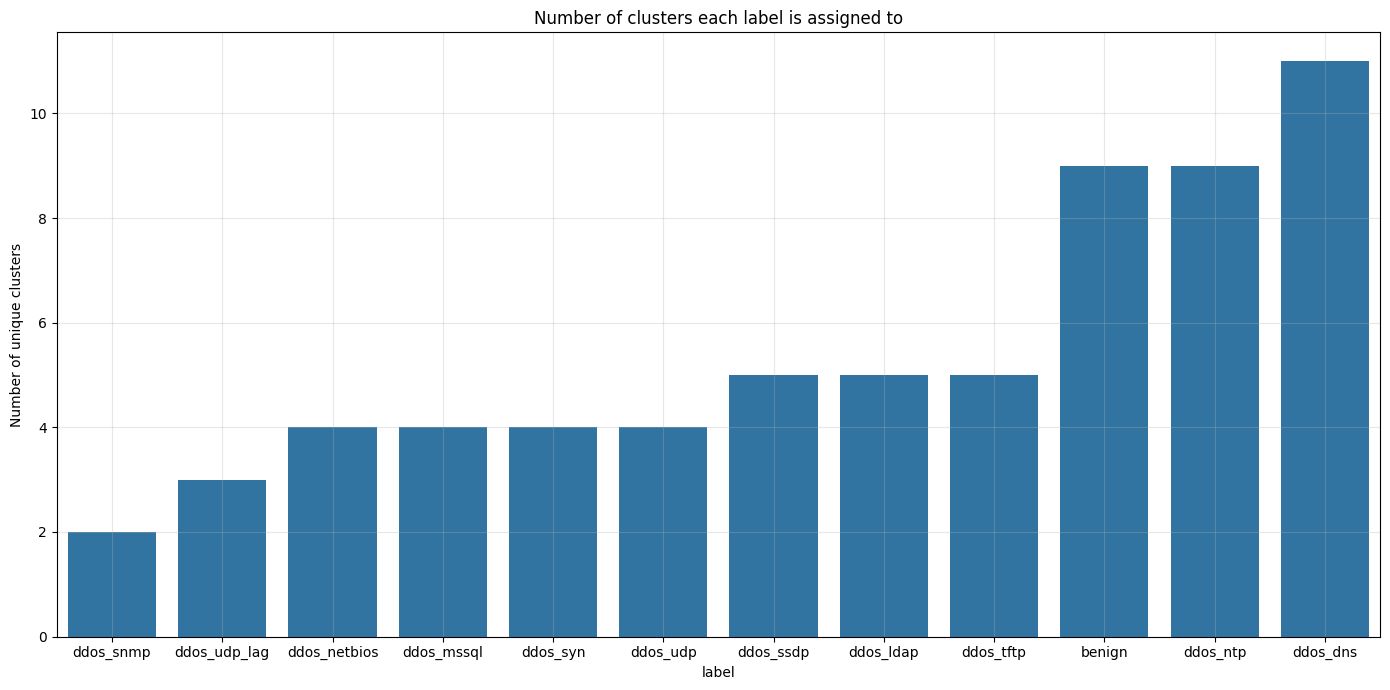

In [8]:
def plot_clusters_per_label(clusters_per_label):
    plt.figure(figsize=(14, 7))
    sns.barplot(x=clusters_per_label.index, y=clusters_per_label.values)

    plt.title('Number of clusters each label is assigned to')
    plt.xlabel('label')
    plt.ylabel('Number of unique clusters')
    
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

clusters_per_label = df_pd.groupby('label')['cluster'].nunique().sort_values()
plot_clusters_per_label(clusters_per_label)

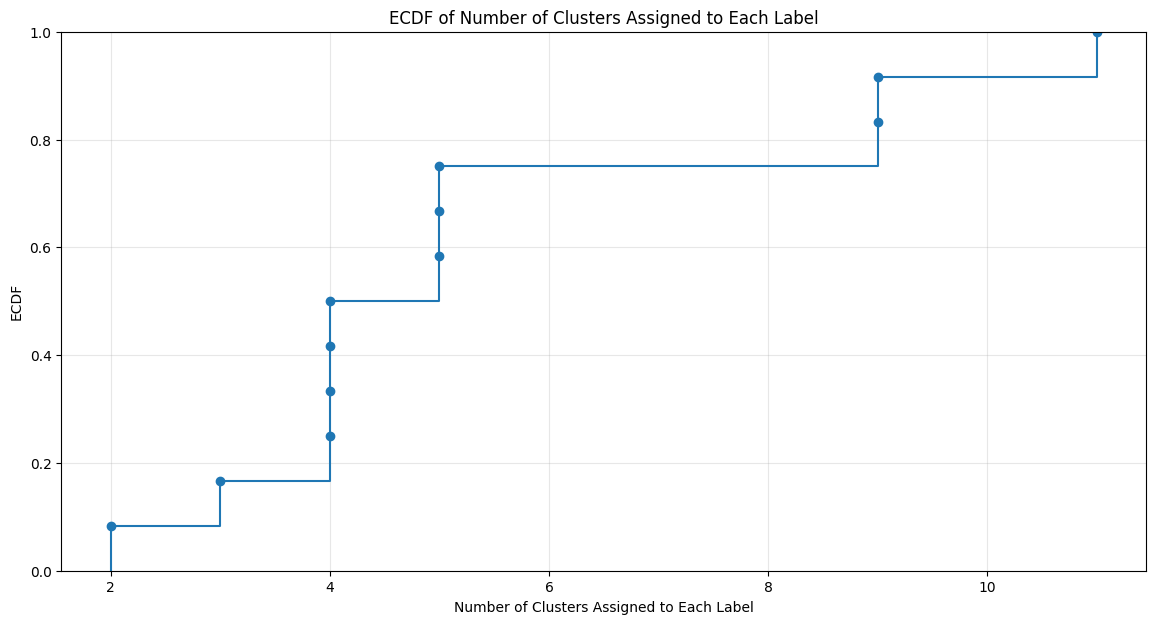

In [9]:
def plot_ECDF_number_of_clusters_per_label(clusters_per_label):
    plt.figure(figsize=(14, 7))
    sns.ecdfplot(clusters_per_label, marker='o')

    plt.title('ECDF of Number of Clusters Assigned to Each Label')
    plt.xlabel('Number of Clusters Assigned to Each Label')
    plt.ylabel('ECDF')
    plt.grid(alpha=0.3)
    plt.show()

plot_ECDF_number_of_clusters_per_label(clusters_per_label)

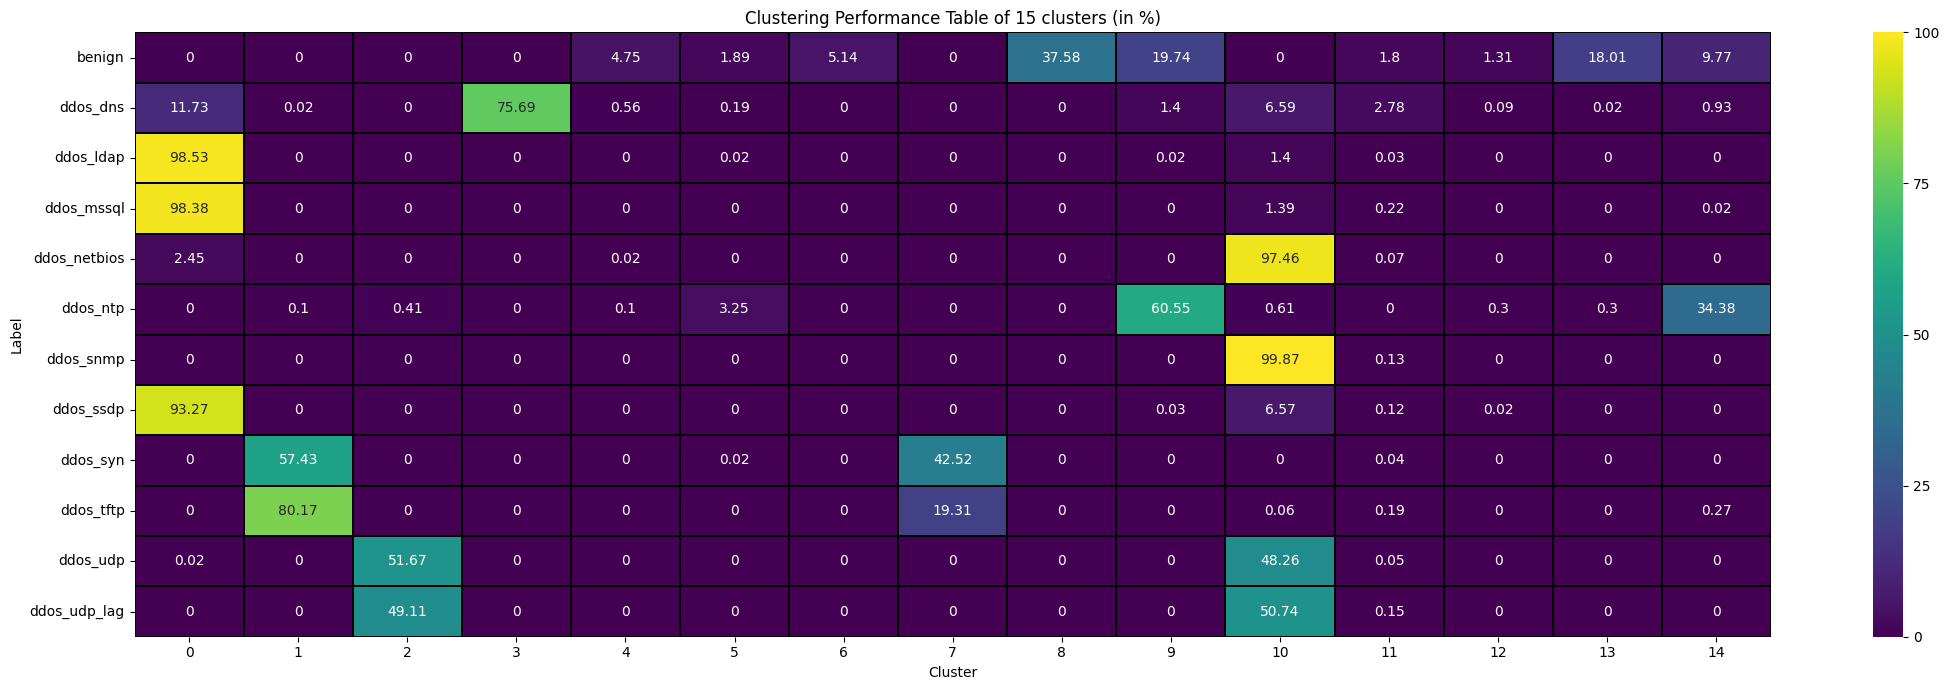

In [10]:
def plot_label_cluster_heatmap(cluster_labels, true_labels, normalize=True):
    df = pd.DataFrame({"label": true_labels,"cluster": cluster_labels})
    table = (df.groupby("label")["cluster"].value_counts().unstack(fill_value=0))

    if normalize:
        table = table.div(table.sum(axis=1), axis=0) *100

    plt.figure(figsize=(22,7))
    sns.heatmap(table, 
                cmap="viridis", 
                cbar=True, 
                cbar_kws={"ticks": np.linspace(0, 100 if normalize else table.values.max(), 5)}, 
                vmin=0, 
                vmax=100 if normalize else table.values.max(), 
                linewidths=0.1, 
                linecolor='black', 
                fmt="", 
                annot=table.map(lambda v: f"{v:.2f}".rstrip('0').rstrip('.')) if normalize else table,
                annot_kws={"size": 10})

    plt.xlabel("Cluster")
    plt.ylabel("Label")
    if normalize:
        plt.title(f"Clustering Performance Table of {len(np.unique(cluster_labels))} clusters (in %)")
    else:
        plt.title(f"Clustering Performance Table of {len(np.unique(cluster_labels))} clusters (num of samples)")

    plt.tight_layout()
    plt.show()

plot_label_cluster_heatmap(df_pd["cluster"],df_pd["label"],True)

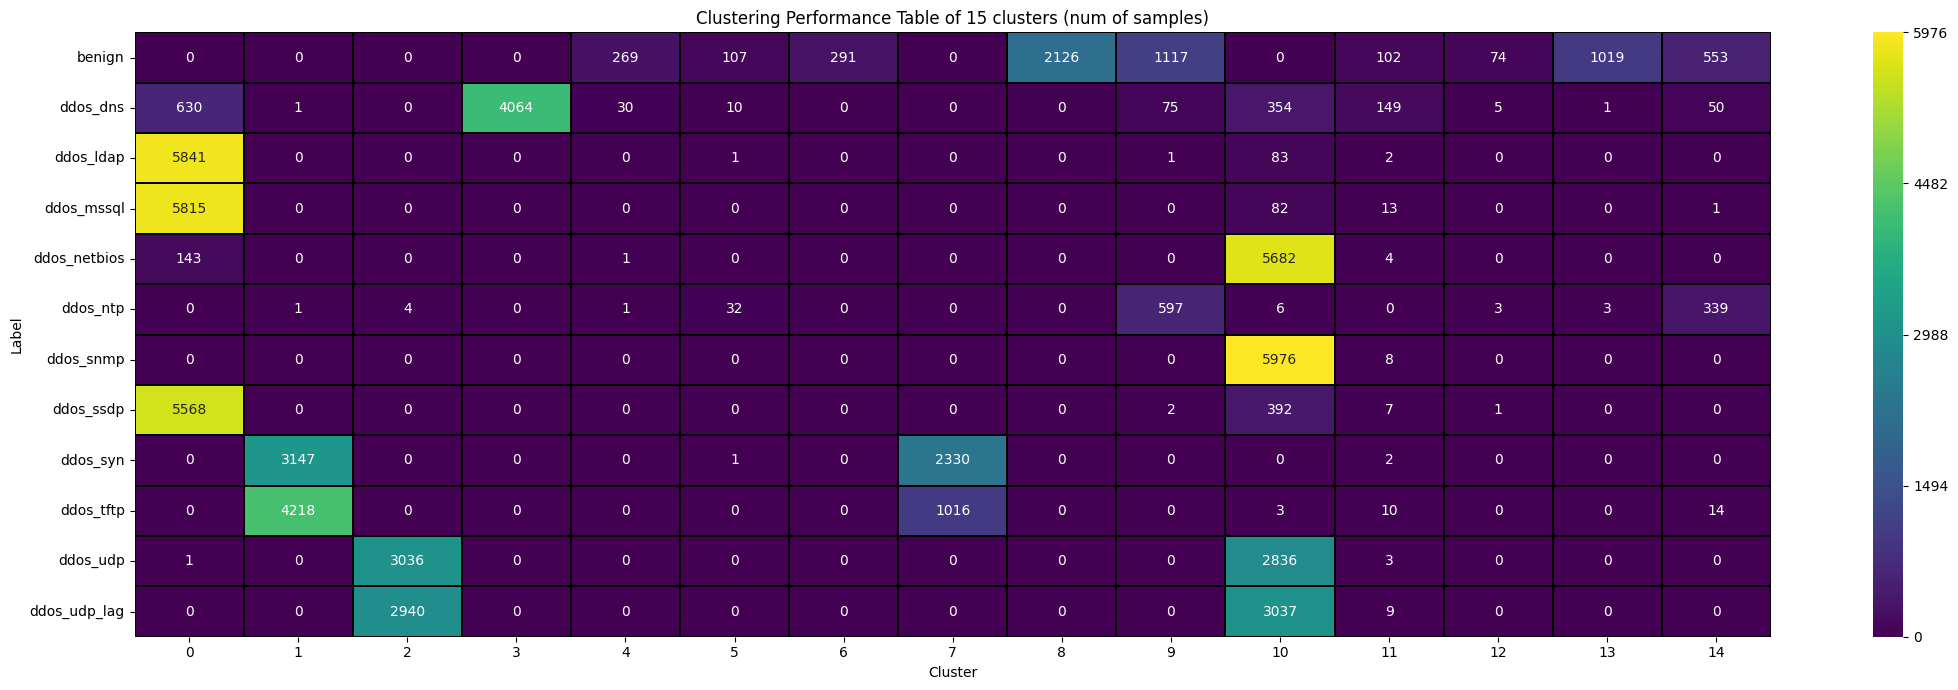

In [11]:
plot_label_cluster_heatmap(df_pd["cluster"],df_pd["label"],False)

# 2. Feature Importance Analysis.

### Permutation Importance

In [12]:
def permutation_importance_gmm(checkpoint_file, df, features, true_labels, n_clusters, cv_type, n_repeats=10, random_state=42, n_sample = None):
    if os.path.exists(checkpoint_file):
        with open(checkpoint_file, "rb") as f:
            saved_info = pickle.load(f)
            results = saved_info["results"]
            baseline = saved_info["baseline"]
            rng = np.random.default_rng()
            rng.bit_generator.state = saved_info["rng_state"]
            n_f = len(results["features"])
            print(f"Checkpoint found. Feature processed: {n_f}")
    else:
        rng = np.random.default_rng(random_state)
        gmm_baseline = GaussianMixture(n_components=n_clusters, covariance_type=cv_type,n_init=50, max_iter=500, init_params="k-means++", random_state=random_state)
        baseline_labels = gmm_baseline.fit_predict(df)

        baseline = {
            "labels": baseline_labels,
            "ari": adjusted_rand_score(true_labels, baseline_labels),
            "ri": rand_score(true_labels, baseline_labels),
            "log_likelihood": gmm_baseline.score(df),
            "silhouette": silhouette_score(df, baseline_labels, sample_size=n_sample ),
            "cluster_count": np.bincount(baseline_labels, minlength=n_clusters)
        }

        results = {
            "features": [],
            "ari": [],
            "ri": [],
            "log_likelihood": [],
            "silhouette": [],
            "cluster_count_variation": [],
            "instability_scores": []
        }

    for j in range(df.shape[1]):
        if features[j] not in results["features"]:
            print(f"Iterating on {features[j]}")
            ari_scores = []
            ri_scores = []
            log_l_scores = []
            silhouette_scores = []
            cluster_count_variation = []
            instability_scores = []

            for l in range(n_repeats):
                df_perm = df.copy()
                rng.shuffle(df_perm[:, j])
                
                gmm_perm = GaussianMixture(n_components=n_clusters, covariance_type=cv_type,n_init=50, max_iter=500, init_params="k-means++", random_state=random_state)
                perm_labels = gmm_perm.fit_predict(df_perm)

                ari_scores.append(baseline["ari"] - adjusted_rand_score(true_labels, perm_labels))
                ri_scores.append(baseline["ri"] - rand_score(true_labels, perm_labels))
                log_l_scores.append(baseline["log_likelihood"] - gmm_perm.score(df_perm))
                silhouette_scores.append(baseline["silhouette"] - silhouette_score(df_perm, perm_labels, sample_size=n_sample))
                cluster_count_variation.append(np.sum(np.abs(baseline["cluster_count"] - np.bincount(perm_labels, minlength=n_clusters))))
                instability_scores.append( 1.0 - adjusted_rand_score(baseline["labels"], perm_labels) )

            results["features"].append(features[j])
            results["ari"].append(np.mean(ari_scores))
            results["ri"].append(np.mean(ri_scores))
            results["log_likelihood"].append(np.mean(log_l_scores))
            results["silhouette"].append(np.mean(silhouette_scores))
            results["cluster_count_variation"].append(np.mean(cluster_count_variation))
            results["instability_scores"].append(np.mean(instability_scores))
        
            with open(checkpoint_file, "wb") as f:
                pickle.dump({"results": results, "baseline": baseline, "rng_state": rng.bit_generator.state}, f)
            print("Checkpoint saved")
    print(f"All saved")
    return results, baseline

In [13]:
results, baseline = permutation_importance_gmm(checkpoint_file="./saved_results/gmm_feature_importance.pkl", df=df_pre_gmm_np, features=df_pre_gmm_pd.columns, true_labels=df_pd["label"], n_clusters=best_k, cv_type='diag', n_repeats=20, random_state=42, n_sample = 100)

Checkpoint found. Feature processed: 75
All saved


#### Interpretation of Feature Permutation Impacts
When evaluating the importance of a feature by permuting its values and observing the change in a performance metric 
- $\Delta > 0$ (Metric Worsens): The Feature is Useful. Permuting the values destroys the inherent structure of the data, leading to a drop in clustering quality. This indicates that the model relies on this feature to distinguish between patterns.
- $\Delta = 0$ (Metric Stays the Same): The Feature is Redundant/Useless. Scrambling the feature has no impact on the clustering results, meaning the algorithm is not utilizing this information to form clusters.
- $\Delta < 0$ (Metric Improves): The Feature is Noisy. Permuting the feature actually improves the clustering performance. This suggests the feature was acting as "noise" or a distractor, and its original presence was hindering the algorithm's ability to find clean, separate groups.

In [14]:
def plot_all_importances(results, metrics, top_n=10):
    
    df_tops = pd.DataFrame({"feature": results["features"], metrics[0]: results[metrics[0]],metrics[1]: results[metrics[1]]})
    top_1 = set(df_tops.nlargest(top_n, metrics[0])["feature"])
    top_2 = set(df_tops.nlargest(top_n, metrics[1])["feature"])
    top_common = top_1 & top_2
    
    def get_category(f):
        if f in top_common: return  f"Top {top_n} {metrics[0]} & {metrics[1]}"
        if f in top_1: return f"Top {top_n} {metrics[0]}"
        if f in top_2: return f"Top {top_n} {metrics[1]}"
        return "Others"

    palette = {f"Top {top_n} {metrics[0]} & {metrics[1]}": "#8B4513", f"Top {top_n} {metrics[0]}": "#FF8C00", f"Top {top_n} {metrics[1]}": "#006400", "Others": "#D3D3D3"}

    fig, axes = plt.subplots(len(metrics) // 2, 2, figsize=(25, 25))
    axes = axes.flatten()

    for i, metric in enumerate(metrics):
        df_plot = pd.DataFrame({"feature":  results["features"],"importance": results[metric],"Category": [get_category(f) for f in  results["features"]]})
        
        df_plot = df_plot.reindex(df_plot['importance'].abs().sort_values(ascending=False).index)

        sns.barplot(data=df_plot,y="feature",x="importance",hue="Category",palette=palette,ax=axes[i],hue_order= list(palette.keys()))

        axes[i].set_title(f"Impact on {metric}")
        axes[i].set_xlabel("Permutation Importance Value")
        axes[i].set_ylabel("")
        axes[i].grid(axis='x', alpha=0.6)
        axes[i].grid(axis='y', linestyle = '--', alpha=0.2)
        axes[i].legend(title=f"Legend", loc='lower right', fontsize=9)

    plt.tight_layout()
    plt.show()

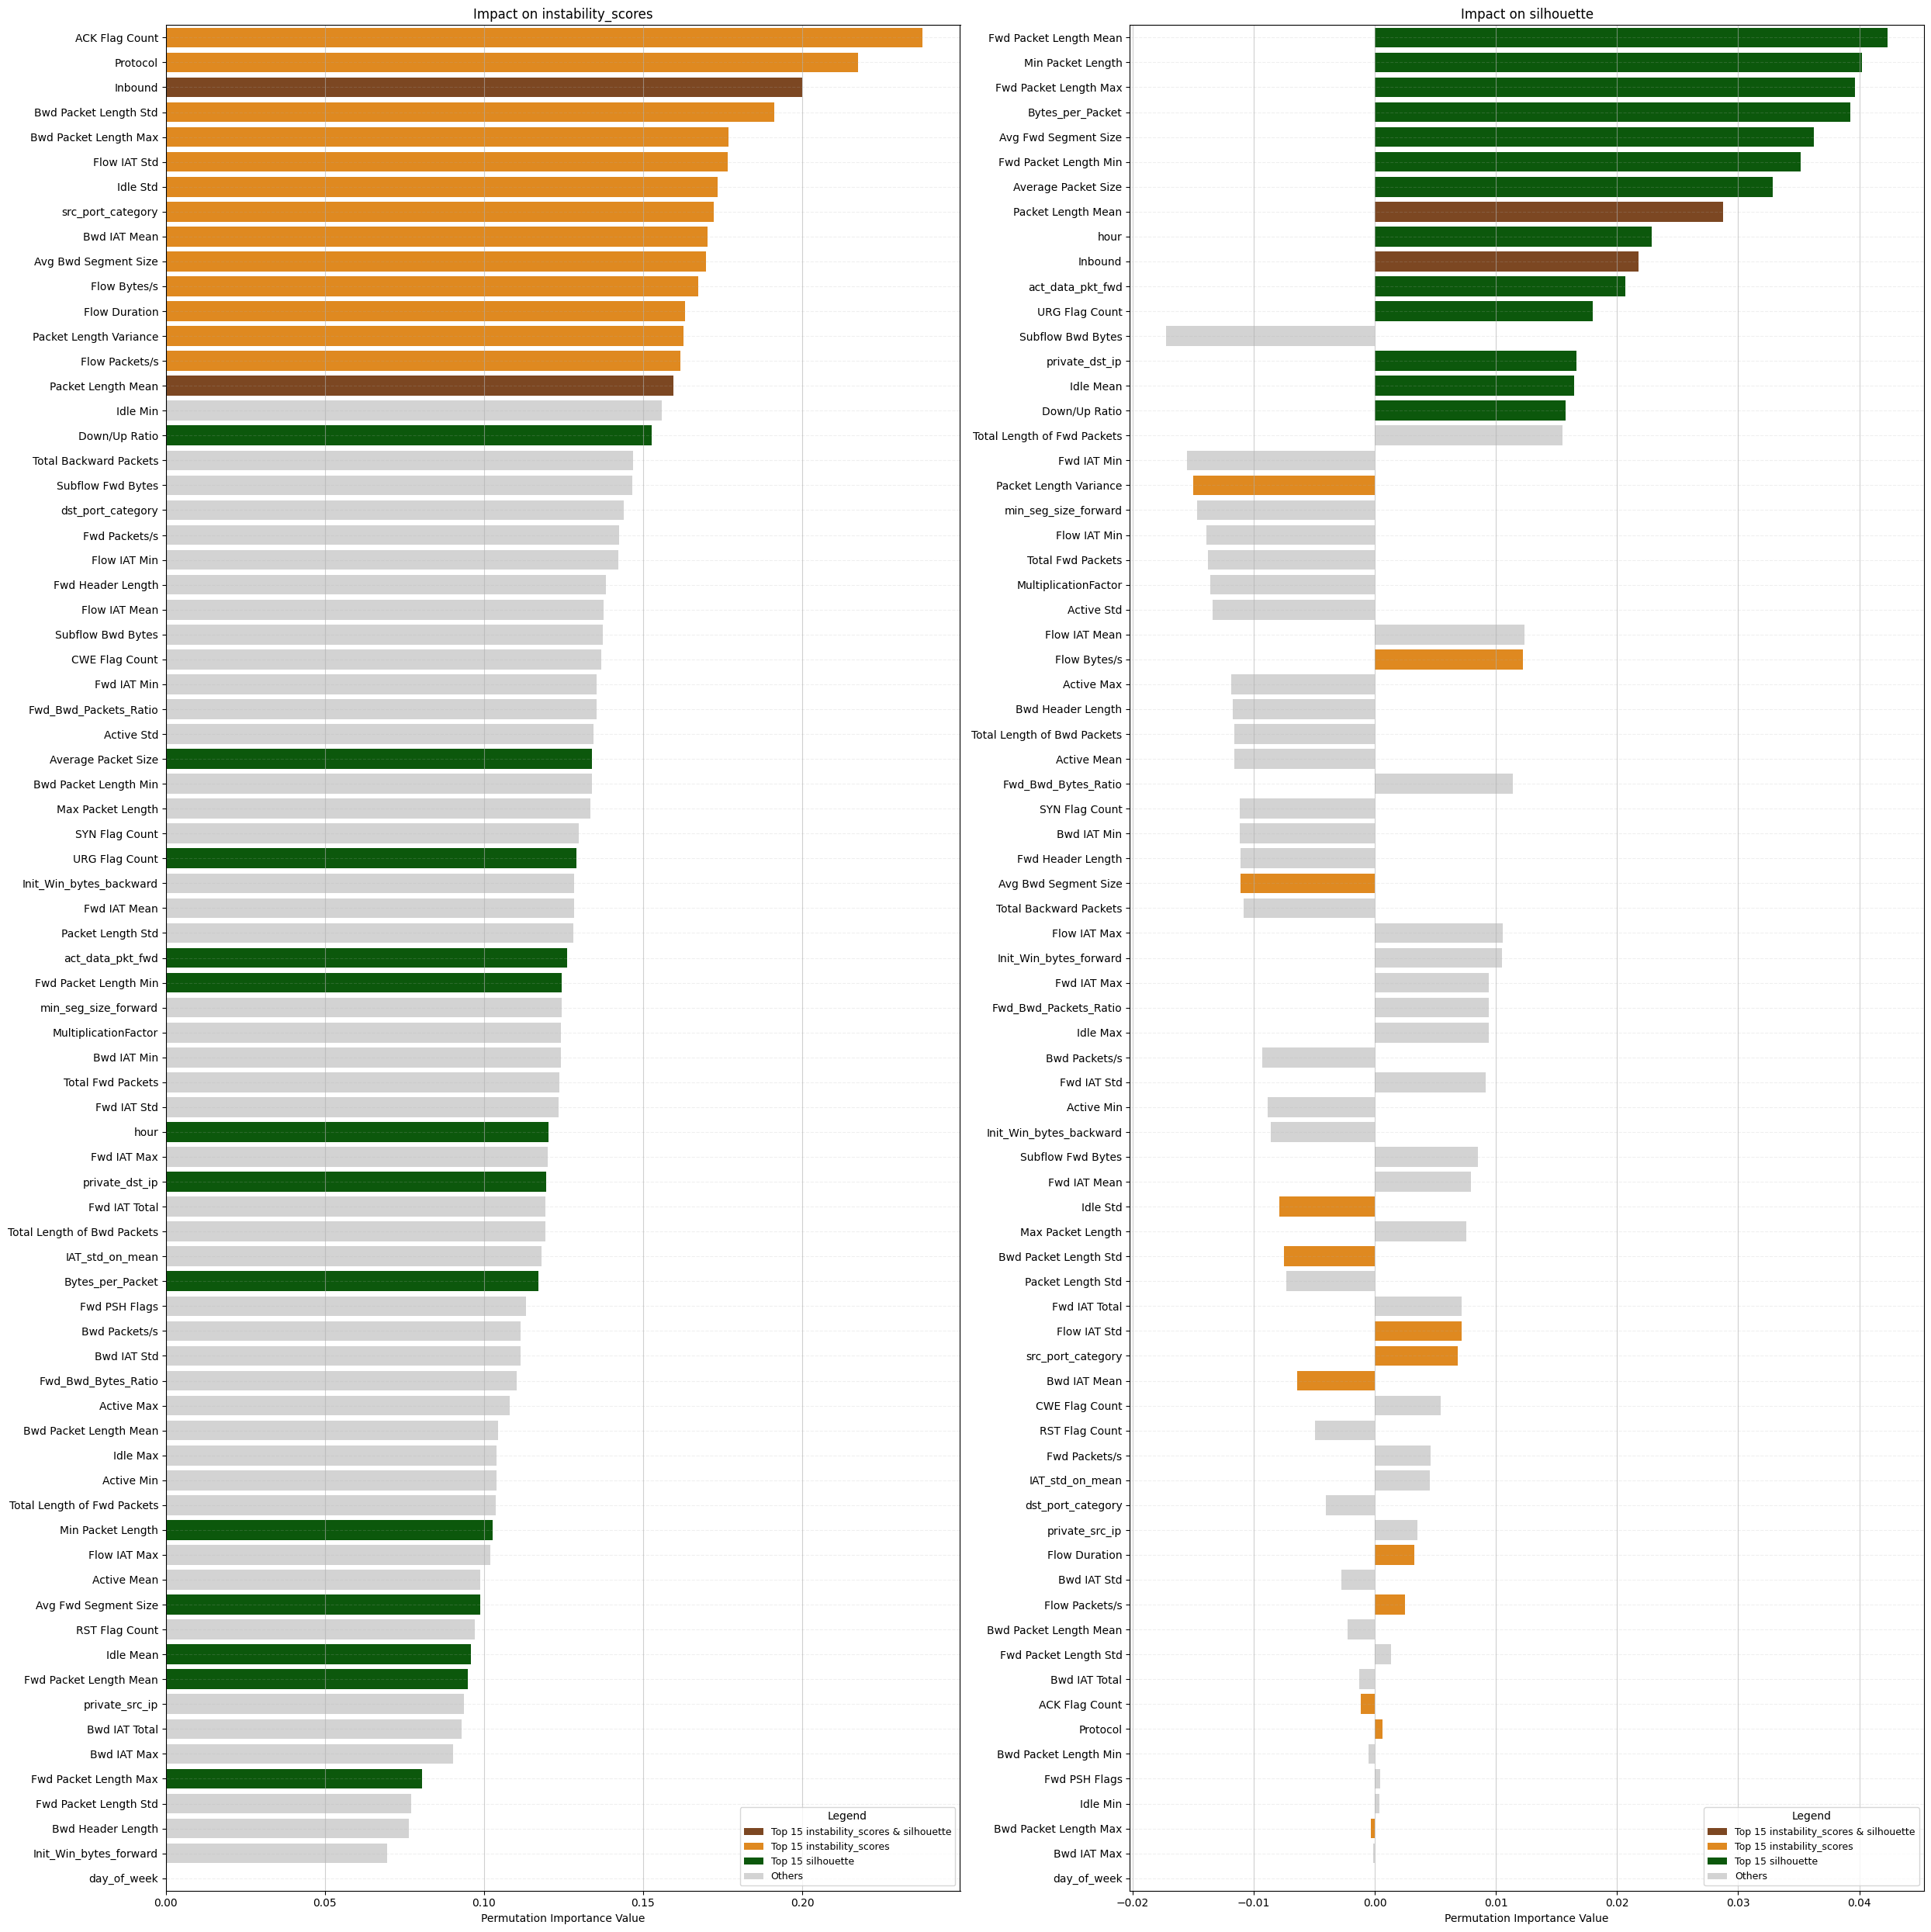

In [15]:
plot_all_importances(results,["instability_scores","silhouette"], top_n=15)

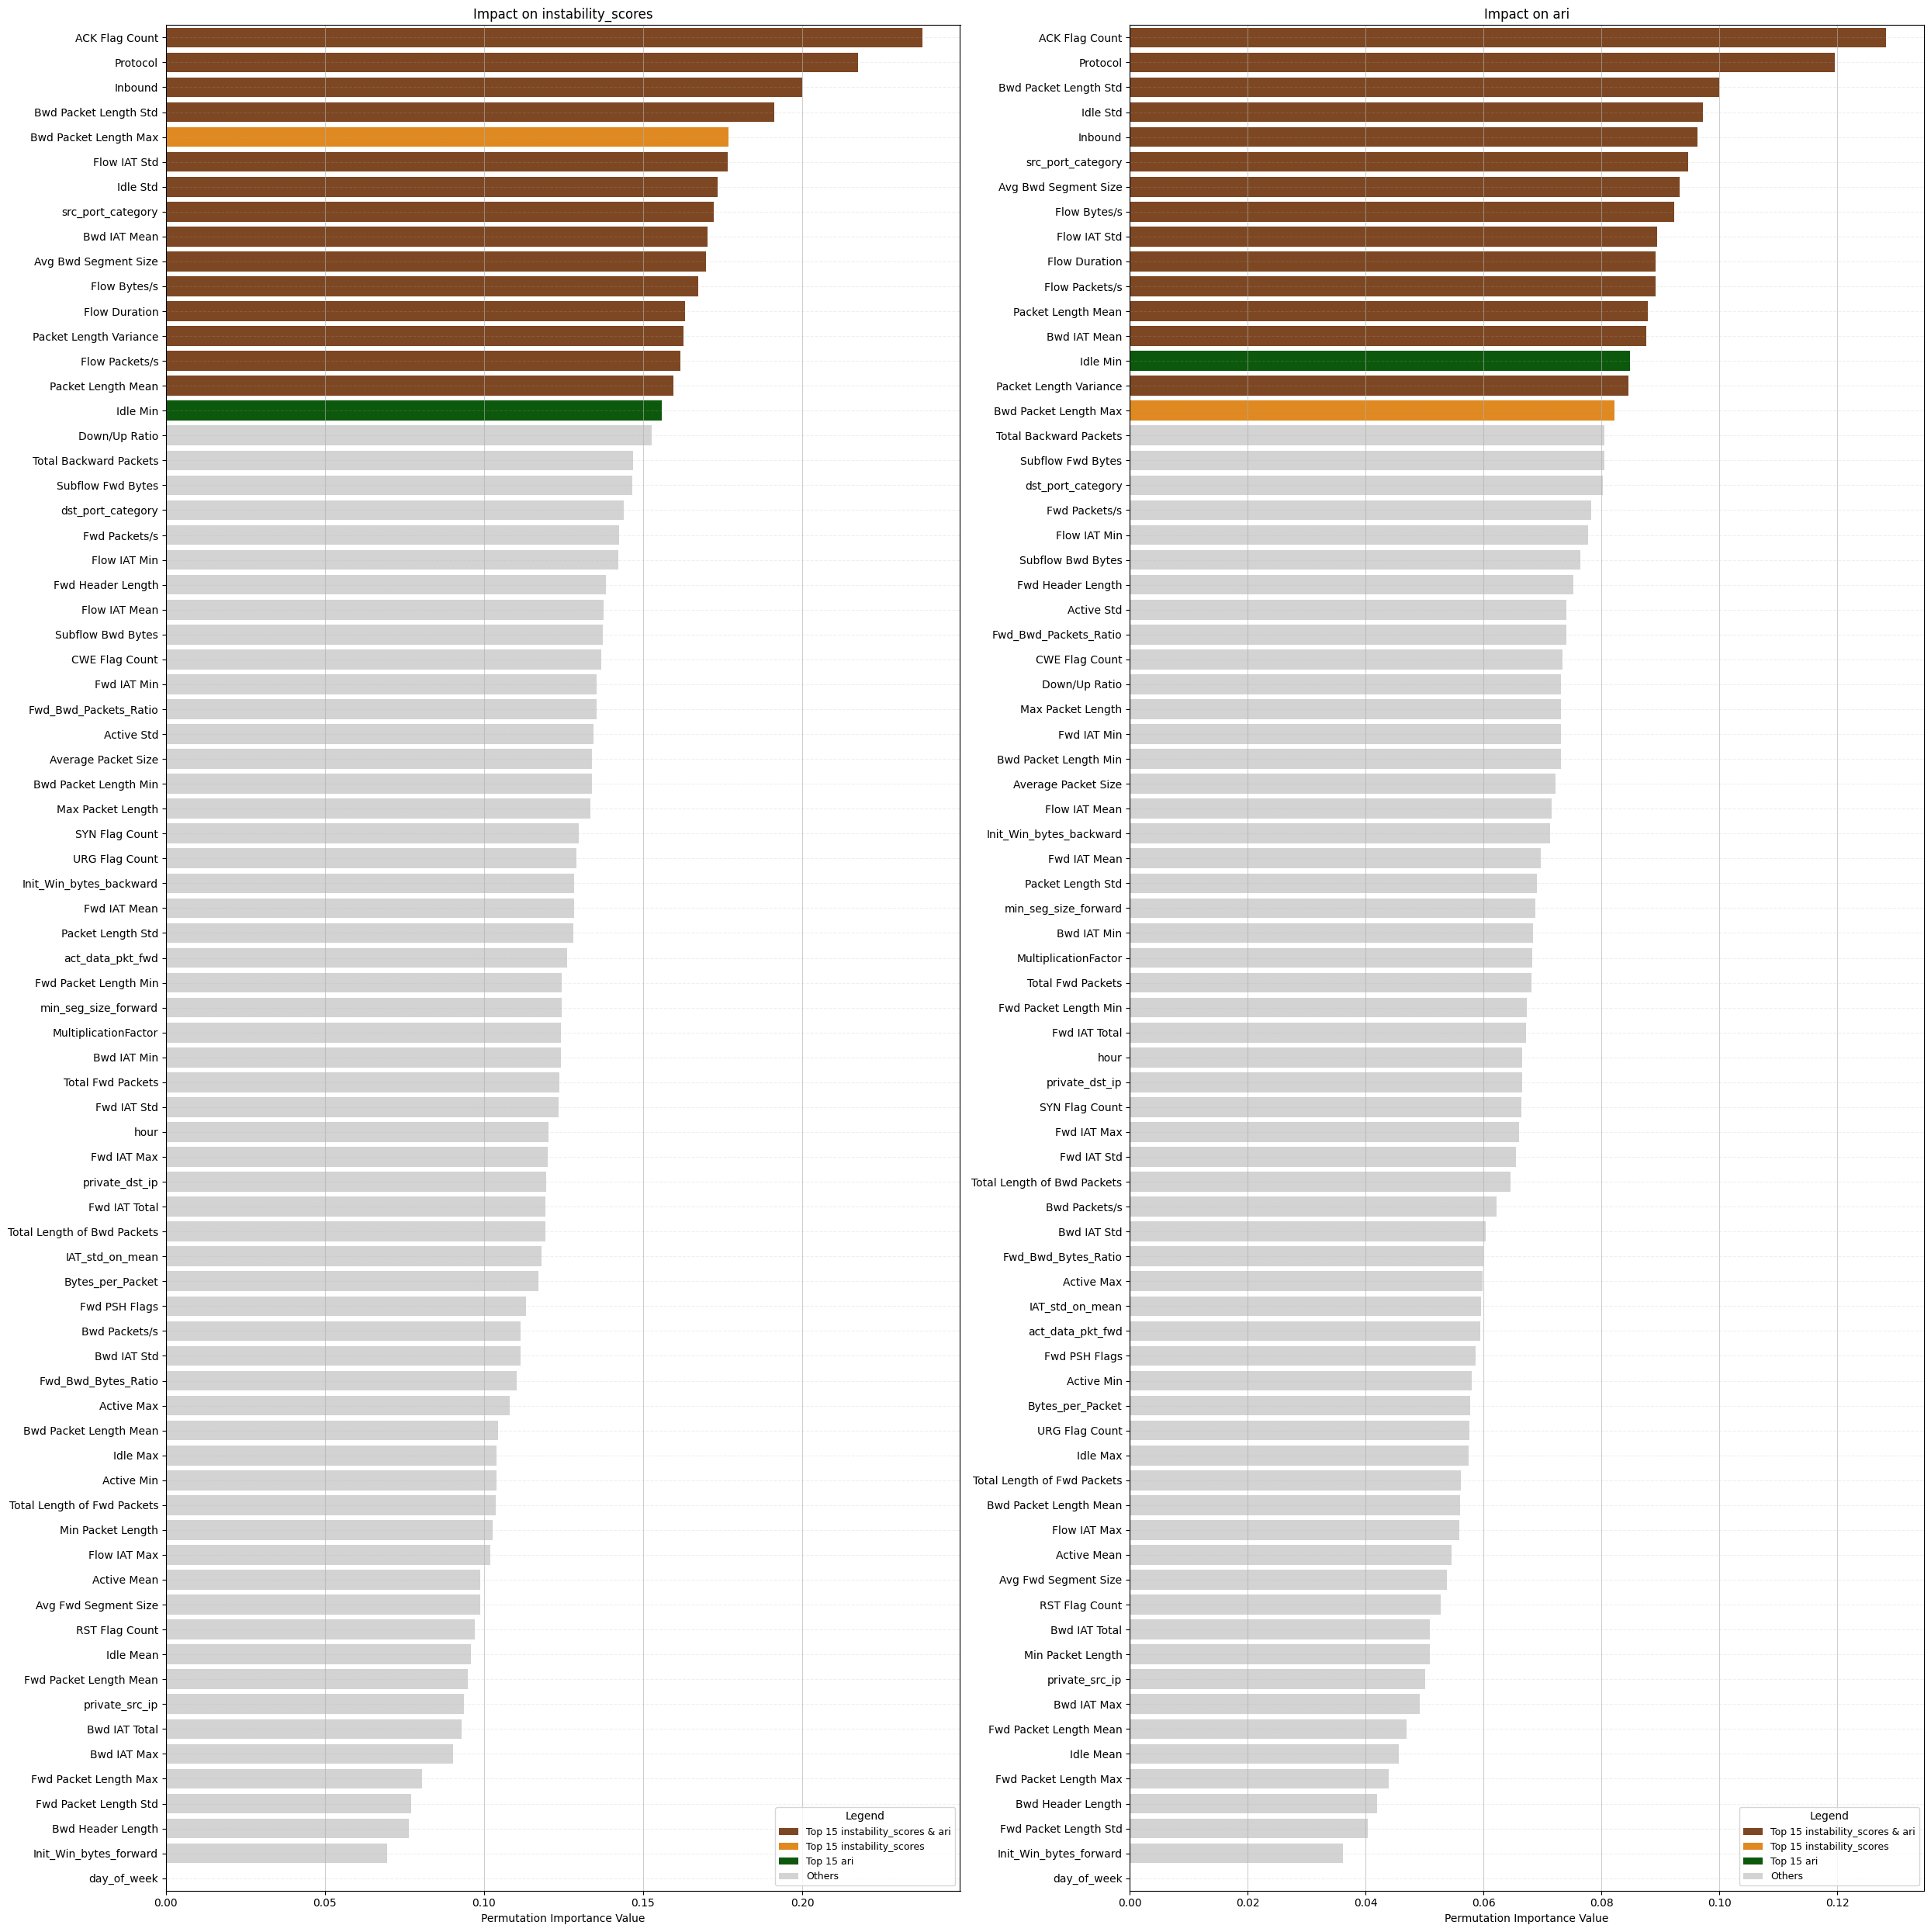

In [16]:
plot_all_importances(results,["instability_scores","ari"], top_n=15)

# Analysis of Instability Scores
The Instability Score identifies which features are foundational to the algorithm's grouping logic. A high score indicates that the feature is a primary driver of cluster formation.

- Primary Network Control Features: The ACK Flag Count, Protocol, and Inbound status emerge as the most critical features for cluster stability. The high instability values for these variables suggest they act as the primary "pivots" for the K-Means algorithm, likely separating traffic based on connection types and directional flow.

- Payload and Packet Dynamics: Features such as Bwd Packet Length Std, Bwd Packet Length Max, and Avg Bwd Segment Size show significant impact. This indicates that the variance and volume of data returning from the destination are essential for defining the "shape" of the clusters.

- Temporal and Flow Statistics: Flow IAT Std (Inter-Arrival Time) and Idle Std exhibit high importance. The algorithm relies heavily on these timing patterns to distinguish between different types of network behavior, such as persistent connections versus bursty or automated traffic.

- Throughput Metrics: Flow Bytes/s and Flow Duration are highlighted as key discriminators (indicated in green). Their removal significantly alters the resulting clusters, confirming that session density and duration are fundamental clustering criteria for this dataset.

Correlation with ARI (Adjusted Rand Index)
The comparison between Instability Scores and Impact on ARI provides a validation of the model's consistency.

- Metric Convergence: There is a strong alignment between features that provide internal stability (Instability) and those that align with the ground truth labels (ARI). Specifically, ACK Flag Count and Protocol dominate both metrics, confirming that the algorithm is capturing the most meaningful partitions in the data.

- Feature Robustness: The top 10 features identified in the Instability chart (marked in dark brown, orange, and green) remain the most influential in the ARI chart. This suggests that the structural clusters found by the algorithm are not arbitrary but are highly representative of the underlying data classes.

# 3. Attack Pattern Investigation.

### a)  Can you identify sub-attacks which belongs to the same class but have different patterns? Which feature contributes to your identification? 

Yes, the clustering clearly reveals that **sub-attacks belonging to the same DDoS class exhibit different behavioral patterns**, as they are mapped to **distinct clusters**.
1. To investigate sub-attack patterns, we analyzed the standardized mean feature values for each cluster (median values showed the same trends), focusing on features with the highest inter-cluster variance.
2. Features that showed the same values across all clusters, were excluded from the analysis, as they do not contribute to the characterization of the different sub-attack groups.
3. Clusters representing less than ~5% of the samples were excluded from the analysis, as they likely correspond to noise, outliers, or rare behaviors that do not significantly contribute to the dominant attack patterns

In [28]:
def getClassDf(ddos_class):
    df_clustered = df_pd.copy()

    df_ddos_class = df_clustered[df_clustered["label"] == ddos_class].copy().reset_index(drop=True)
    df_ddos_class = df_ddos_class.drop(columns="label")
    df_ddos_class = df_ddos_class.loc[:, df_ddos_class.nunique() > 1]

    df_ddos_class_scaled = pd.DataFrame(StandardScaler().fit_transform(df_ddos_class.drop(columns="cluster")), columns=df_ddos_class.drop(columns="cluster").columns)
    df_ddos_class_scaled['cluster'] = df_ddos_class["cluster"]
    
    return df_ddos_class, df_ddos_class_scaled

In [29]:
def plotClusterSummary(df, label):
    counts = df["cluster"].value_counts().sort_index()
    percentages = (df["cluster"].value_counts(normalize=True).sort_index() * 100)
    
    plt.figure(figsize=(14, 7))
    
    ax = sns.barplot(x=counts.index, y=counts.values, palette='viridis', hue=counts.index, legend=False)
    
    labels = []
    for i in range(len(counts)):
        c = counts.values[i]
        p = percentages.values[i]
        testo = f'{int(c)}\n({p:.1f}%)'
        labels.append(testo)
        
    for i, container in enumerate(ax.containers):
        ax.bar_label(container, labels=[labels[i]], padding=3)

    plt.title(f"Sample Distribution by Cluster ({label})")
    plt.xlabel("Cluster")
    plt.ylabel("Number of Samples")
    plt.ylim(0, max(counts.values) * 1.15) 
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

In [30]:
def drop_clusters(df, toDrop):
    for id in toDrop:
        df = df[df["cluster"] != id].reset_index(drop=True)
    return df

In [31]:
def plotMeanFeaturesPerCluster(df_s, mesure, ddos_class):
    if mesure == "Mean":
        df_mesure = df_s.groupby("cluster").mean().reset_index()
        sorted_features = df_s.groupby("cluster").mean().var().sort_values(ascending=False).index
    elif mesure == "Median":
        df_mesure = df_s.groupby("cluster").median().reset_index()
        sorted_features = df_s.groupby("cluster").median().var().sort_values(ascending=False).index
    else:
        print("Mesure invalid")
        return
    
    df_melted = df_mesure.melt(id_vars="cluster", var_name="Feature", value_name="Standardized Value")

    plt.figure(figsize=(10, 25)) 

    sns.barplot(data=df_melted, x="Standardized Value", y="Feature", hue="cluster", palette="viridis", order=sorted_features)

    plt.axvline(0, color='#333333', linewidth=2, label='Global Average') 
    plt.axvline(x=1, color='firebrick', linestyle='--', linewidth=1, alpha=0.7)
    plt.axvline(x=-1, color='firebrick', linestyle='--', linewidth=1, alpha=0.7)
    plt.axvline(x=0.5, color='gray', linestyle=':', linewidth=1, alpha=0.5)
    plt.axvline(x=-0.5, color='gray', linestyle=':', linewidth=1, alpha=0.5)
    plt.axvline(x=2, color='gray', linestyle='-.', linewidth=1, alpha=0.6)
    plt.axvline(x=-2, color='gray', linestyle='-.', linewidth=1, alpha=0.6)

    plt.title(f"{mesure} Values Feature per Cluster of {ddos_class}")
    plt.xlabel("Standardized Score")
    plt.ylabel("Features sorted by variance across cluster means")
    plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc='upper left')

    plt.grid(axis='y', alpha=0.6)
    plt.tight_layout()
    plt.show()

### Attack Pattern Investigation – ddos_dns

In [48]:
df_dns , df_dns_scaled = getClassDf("ddos_dns")

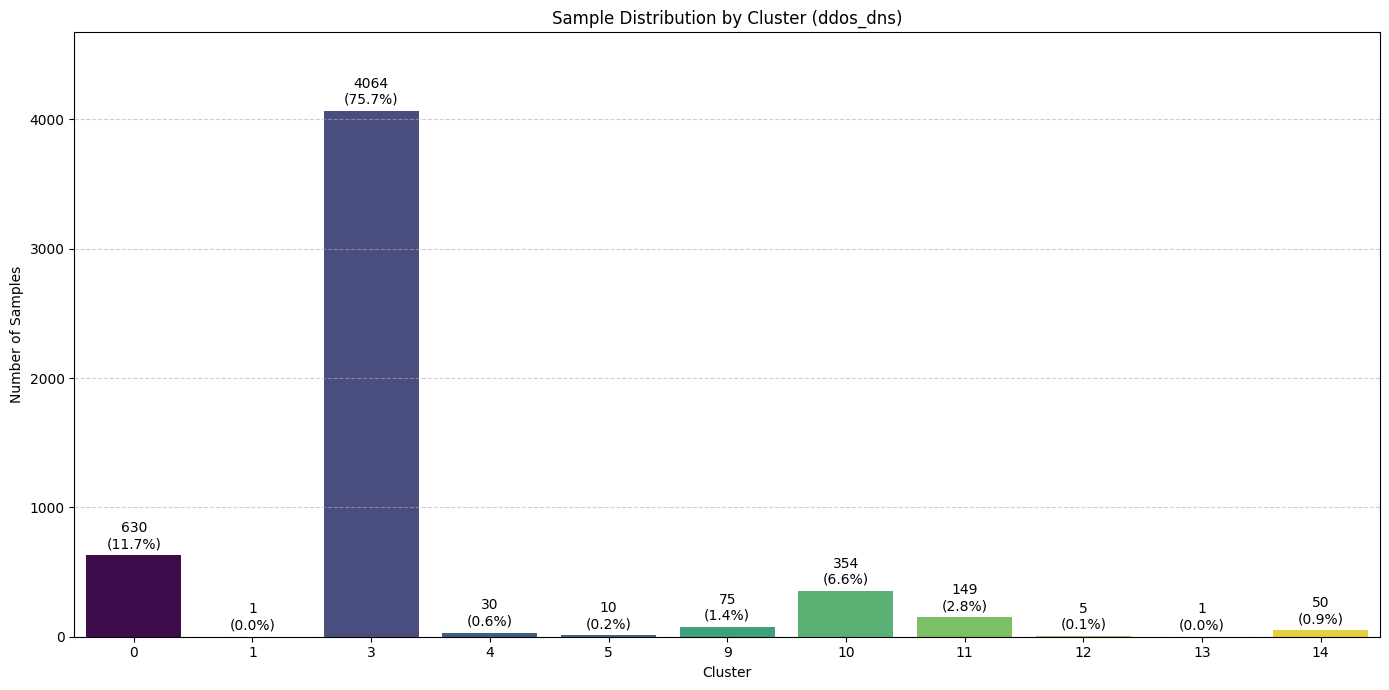

In [49]:
plotClusterSummary(df_dns, "ddos_dns")

In [50]:
toDrop = [1,4,5,9,10,11,12,13,14]
df_dns = drop_clusters(df_dns, toDrop)
df_dns_scaled = drop_clusters(df_dns_scaled, toDrop)

In [51]:
df_dns.groupby("cluster").agg(["mean", "std", "median"])

Protocol             Flow Duration                         \
            mean  std median          mean           std   median   
cluster                                                             
0           17.0  0.0   17.0      2.769841      5.141500      2.0   
3           17.0  0.0   17.0  65752.400591  71734.184651  30814.0   

        Total Fwd Packets                   Total Backward Packets  ...  \
                     mean        std median                   mean  ...   
cluster                                                             ...   
0                2.000000   0.000000    2.0           1.000000e-12  ...   
3              191.160679  19.613695  200.0           1.000000e-12  ...   

        Fwd_Bwd_Packets_Ratio Fwd_Bwd_Bytes_Ratio                              \
                       median                mean           std        median   
cluster                                                                         
0                2.000000e+12        2.940737e+15  2.063854e+13  2.944000e+15   
3                2.000000e+14        8.401811e+16  8.755524e+15  8.800000e+16   

        src_port_category                  dst_port_category                   
                     mean       std median              mean       std median  
cluster                                                                        
0                0.903175  0.974307    0.0          1.225397  0.418175    1.0  
3                0.000000  0.000000    0.0          1.249016  0.458463    1.0  

[2 rows x 210 columns]

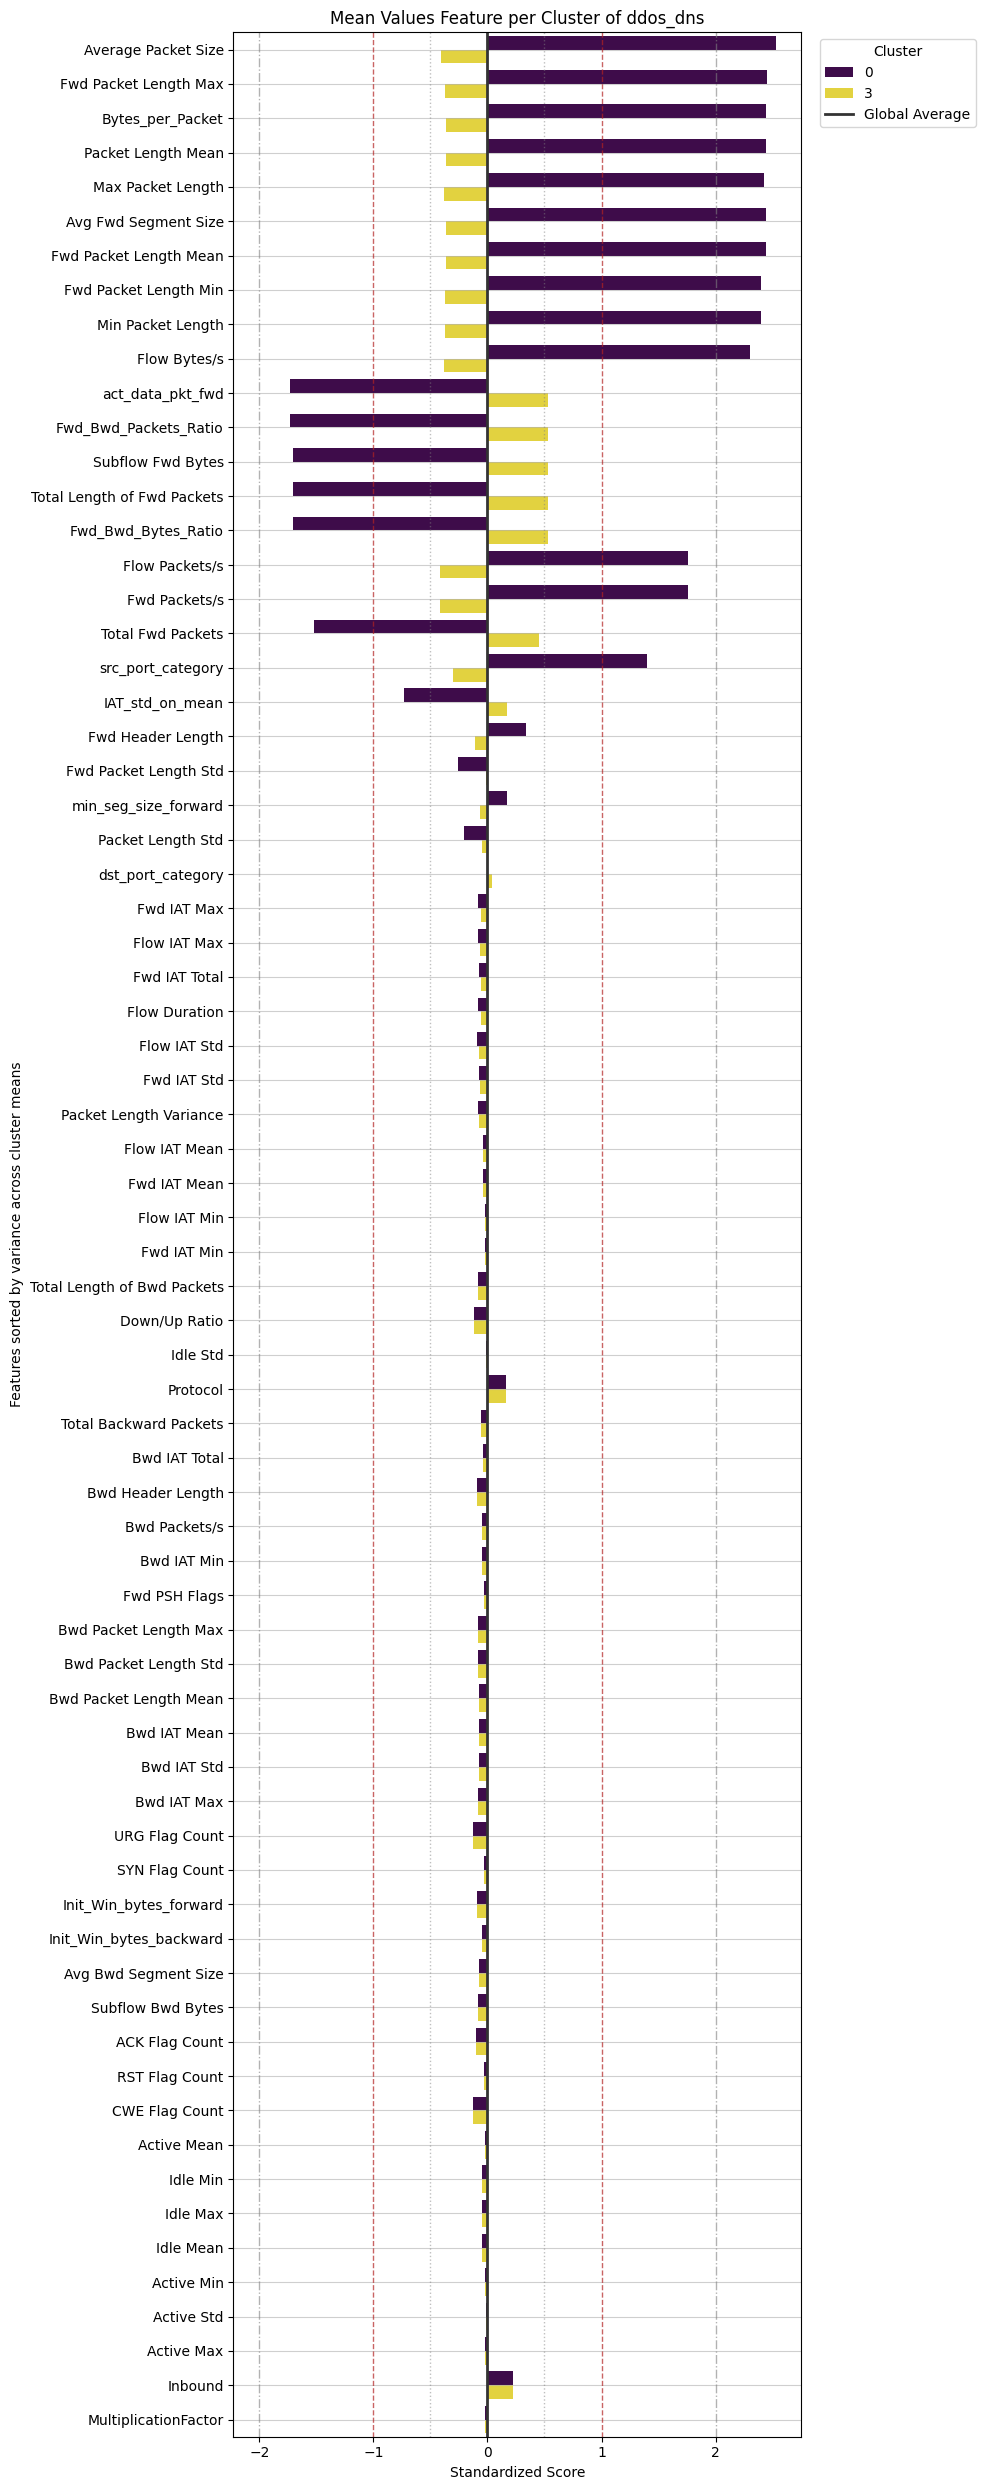

In [52]:
plotMeanFeaturesPerCluster(df_dns_scaled, "Mean", "ddos_dns")

### Attack Pattern Investigation – ddos_ntp

In [53]:
df_ntp , df_ntp_scaled = getClassDf("ddos_ntp")

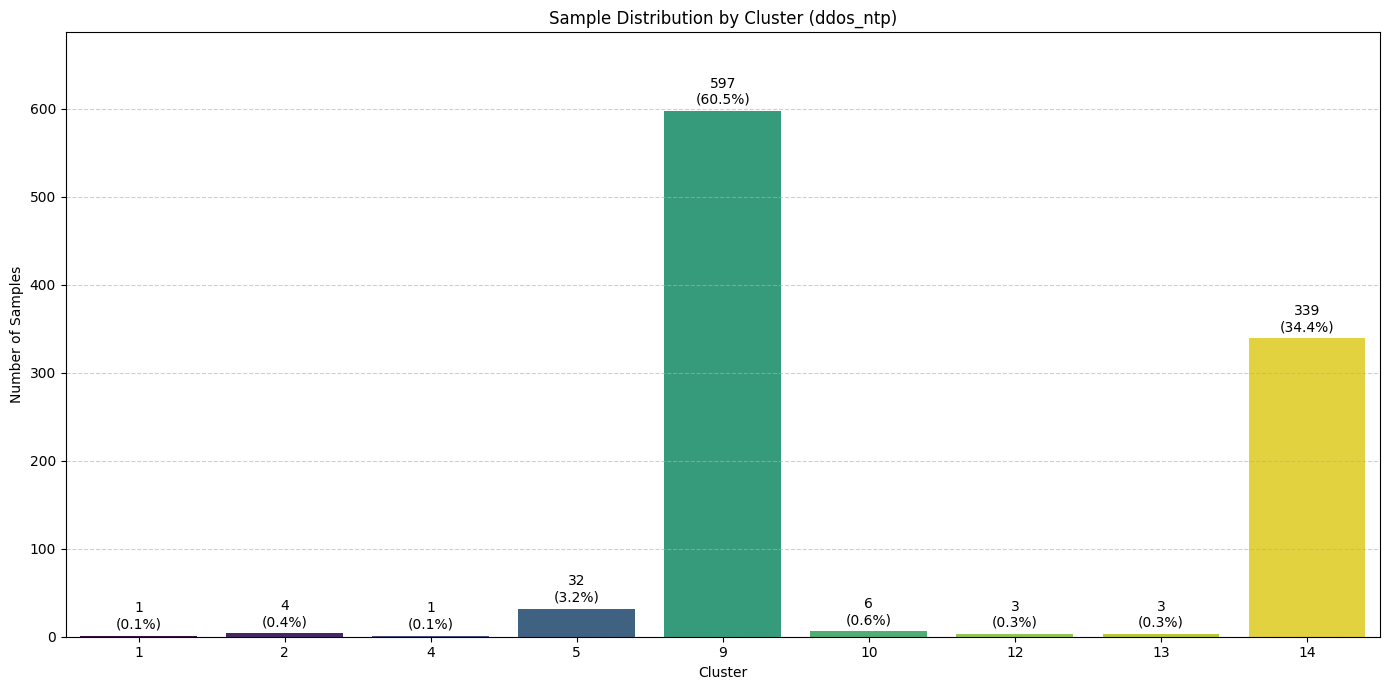

In [54]:
plotClusterSummary(df_ntp, "ddos_ntp")

In [55]:
toDrop = [1,2,6,4,5,10,12,13]
df_ntp = drop_clusters(df_ntp, toDrop)
df_ntp_scaled = drop_clusters(df_ntp_scaled, toDrop)

In [56]:
df_ntp.groupby("cluster").agg(["mean", "std", "median"])

Protocol             Flow Duration                           \
            mean  std median          mean           std     median   
cluster                                                               
9            6.0  0.0    6.0  2.774900e+04  9.552125e+04      151.0   
14           6.0  0.0    6.0  6.199737e+06  4.640005e+06  5247918.0   

        Total Fwd Packets                  Total Backward Packets  ...  \
                     mean       std median                   mean  ...   
cluster                                                            ...   
9                1.090452  0.554293    1.0               1.670017  ...   
14              11.401180  7.976563    9.0              10.103245  ...   

        Fwd_Bwd_Packets_Ratio Fwd_Bwd_Bytes_Ratio                          \
                       median                mean           std    median   
cluster                                                                     
9                    0.500000        8.710218e+11  9.485689e+12  1.000000   
14                   1.333333        6.390763e-01  2.496307e-01  0.517241   

        src_port_category                  dst_port_category                   
                     mean       std median              mean       std median  
cluster                                                                        
9                0.737018  0.810700    1.0          0.720268  0.807146    0.0  
14               1.445428  0.497748    1.0          0.109145  0.348121    0.0  

[2 rows x 210 columns]

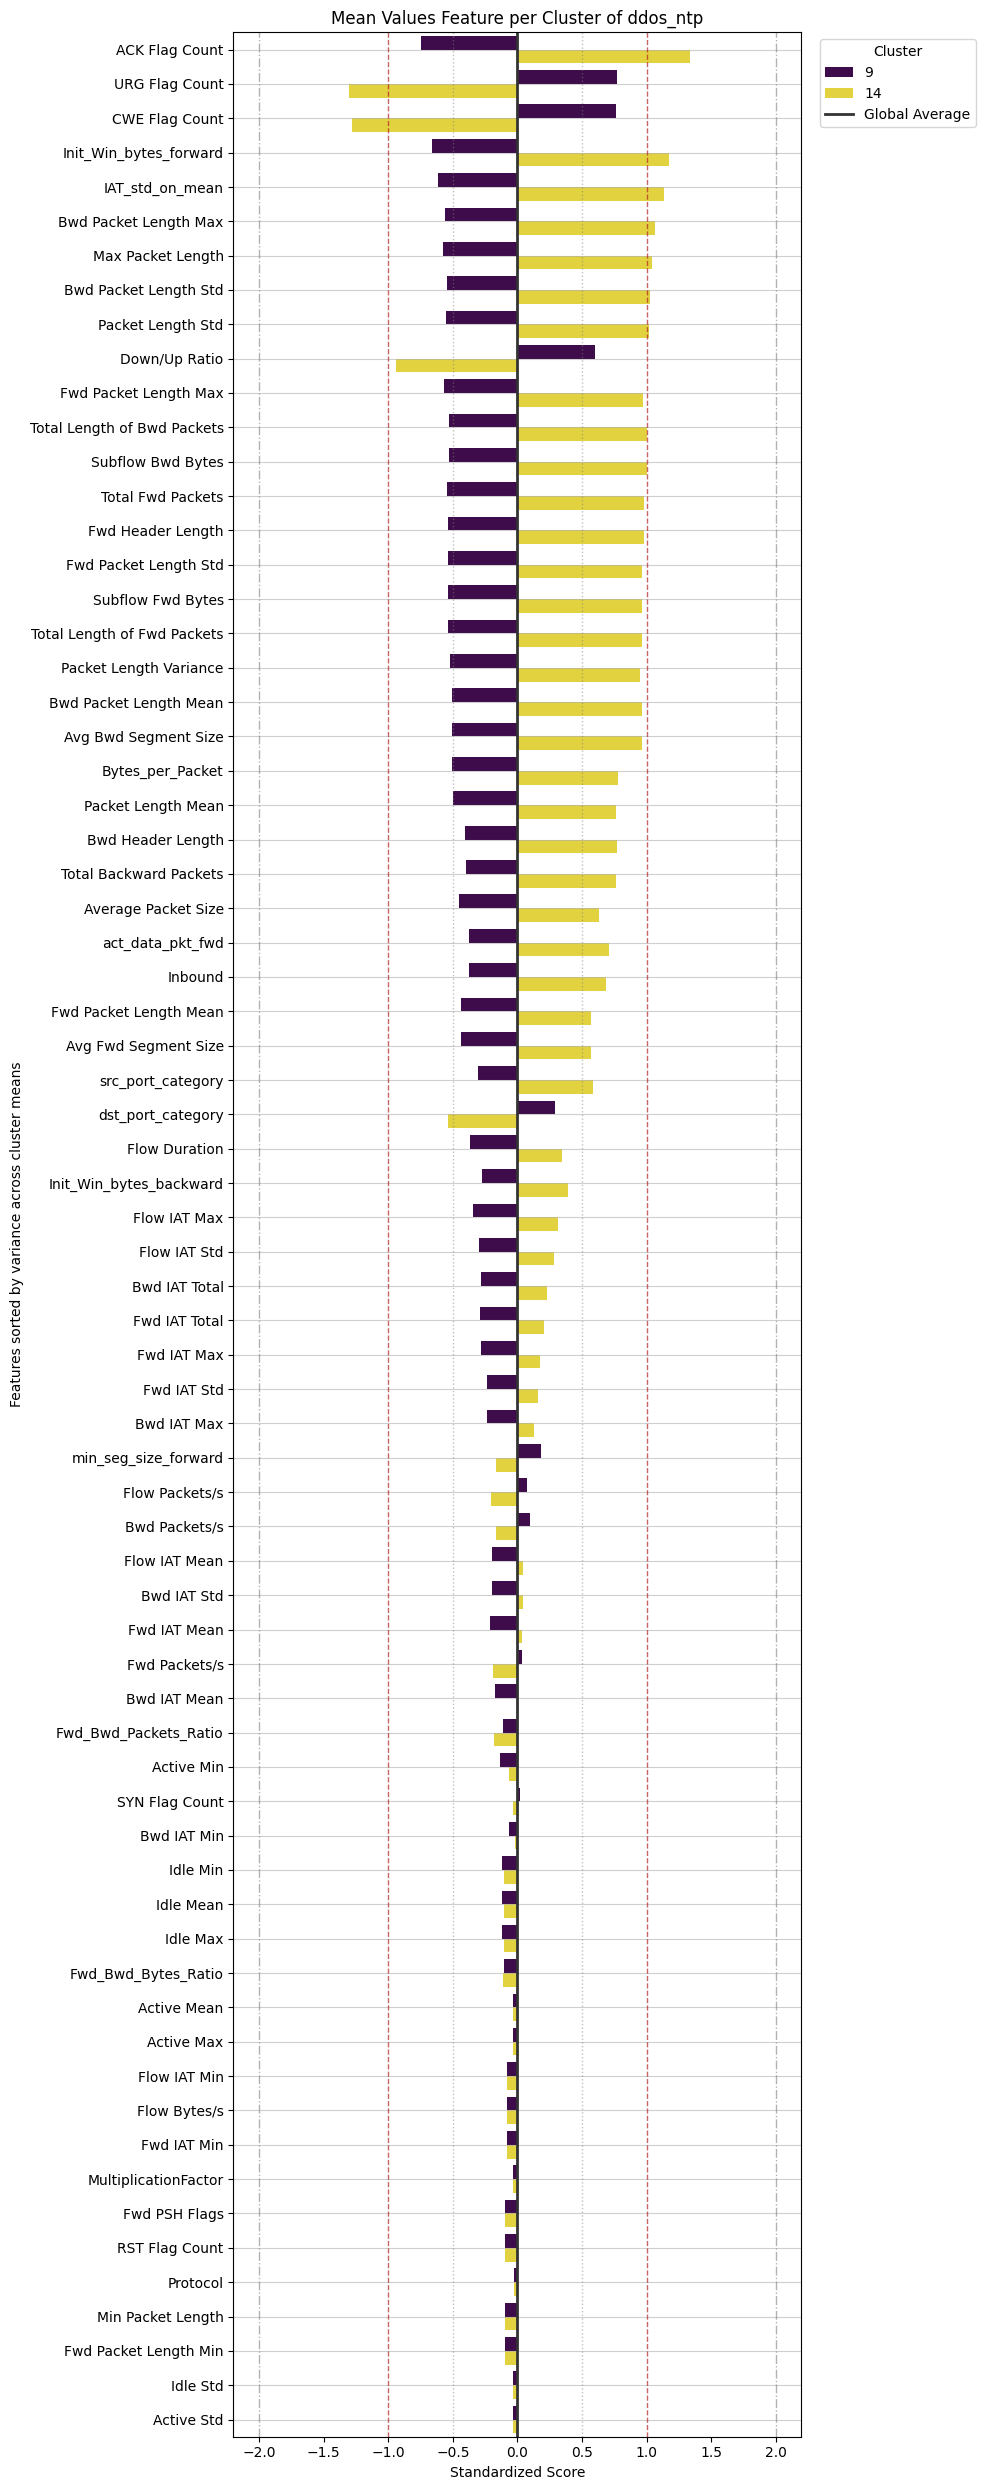

In [57]:
plotMeanFeaturesPerCluster(df_ntp_scaled, "Mean", "ddos_ntp")

### Attack Pattern Investigation – ddos_syn

In [58]:
df_syn , df_syn_scaled = getClassDf("ddos_syn")

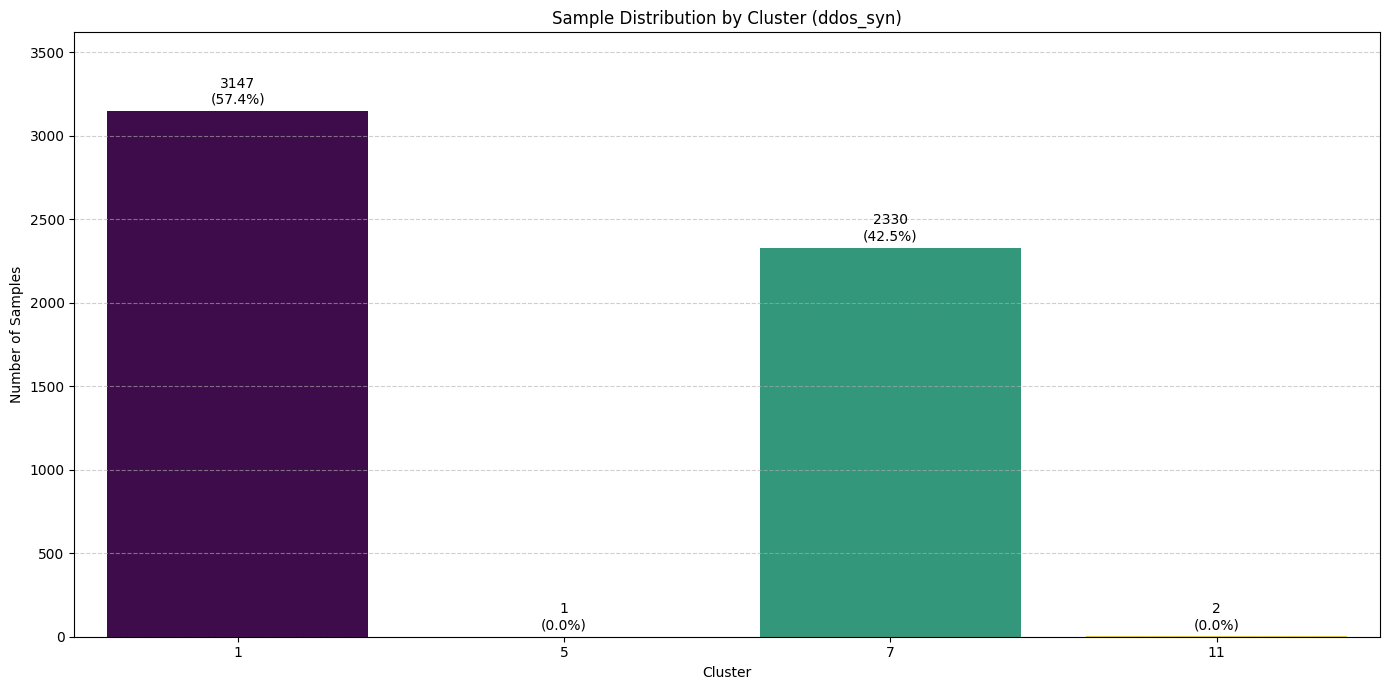

In [59]:
plotClusterSummary(df_syn,"ddos_syn")

In [60]:
toDrop = [5,11]
df_syn = drop_clusters(df_syn, toDrop)
df_syn_scaled = drop_clusters(df_syn_scaled, toDrop)

In [61]:
df_syn.groupby("cluster").agg(["mean", "std", "median"])

Protocol             Flow Duration                             \
            mean  std median          mean           std       median   
cluster                                                                 
1            6.0  0.0    6.0  1.880616e+01  3.319405e+01          1.0   
7            6.0  0.0    6.0  1.089501e+08  1.204771e+07  111278370.0   

        Total Fwd Packets                 Total Backward Packets  ...  \
                     mean      std median                   mean  ...   
cluster                                                           ...   
1                2.000000  0.00000    2.0               0.236416  ...   
7               14.691416  2.71528   14.0               1.577682  ...   

        Fwd_Bwd_Packets_Ratio Fwd_Bwd_Bytes_Ratio              \
                       median                mean  std median   
cluster                                                         
1                2.000000e+12                 1.0  0.0    1.0   
7                9.000000e+00                 1.0  0.0    1.0   

        src_port_category                  dst_port_category                   
                     mean       std median              mean       std median  
cluster                                                                        
1                1.949476  0.289115    2.0          1.245949  0.470231    1.0  
7                1.303004  0.484220    1.0          1.232618  0.449188    1.0  

[2 rows x 168 columns]

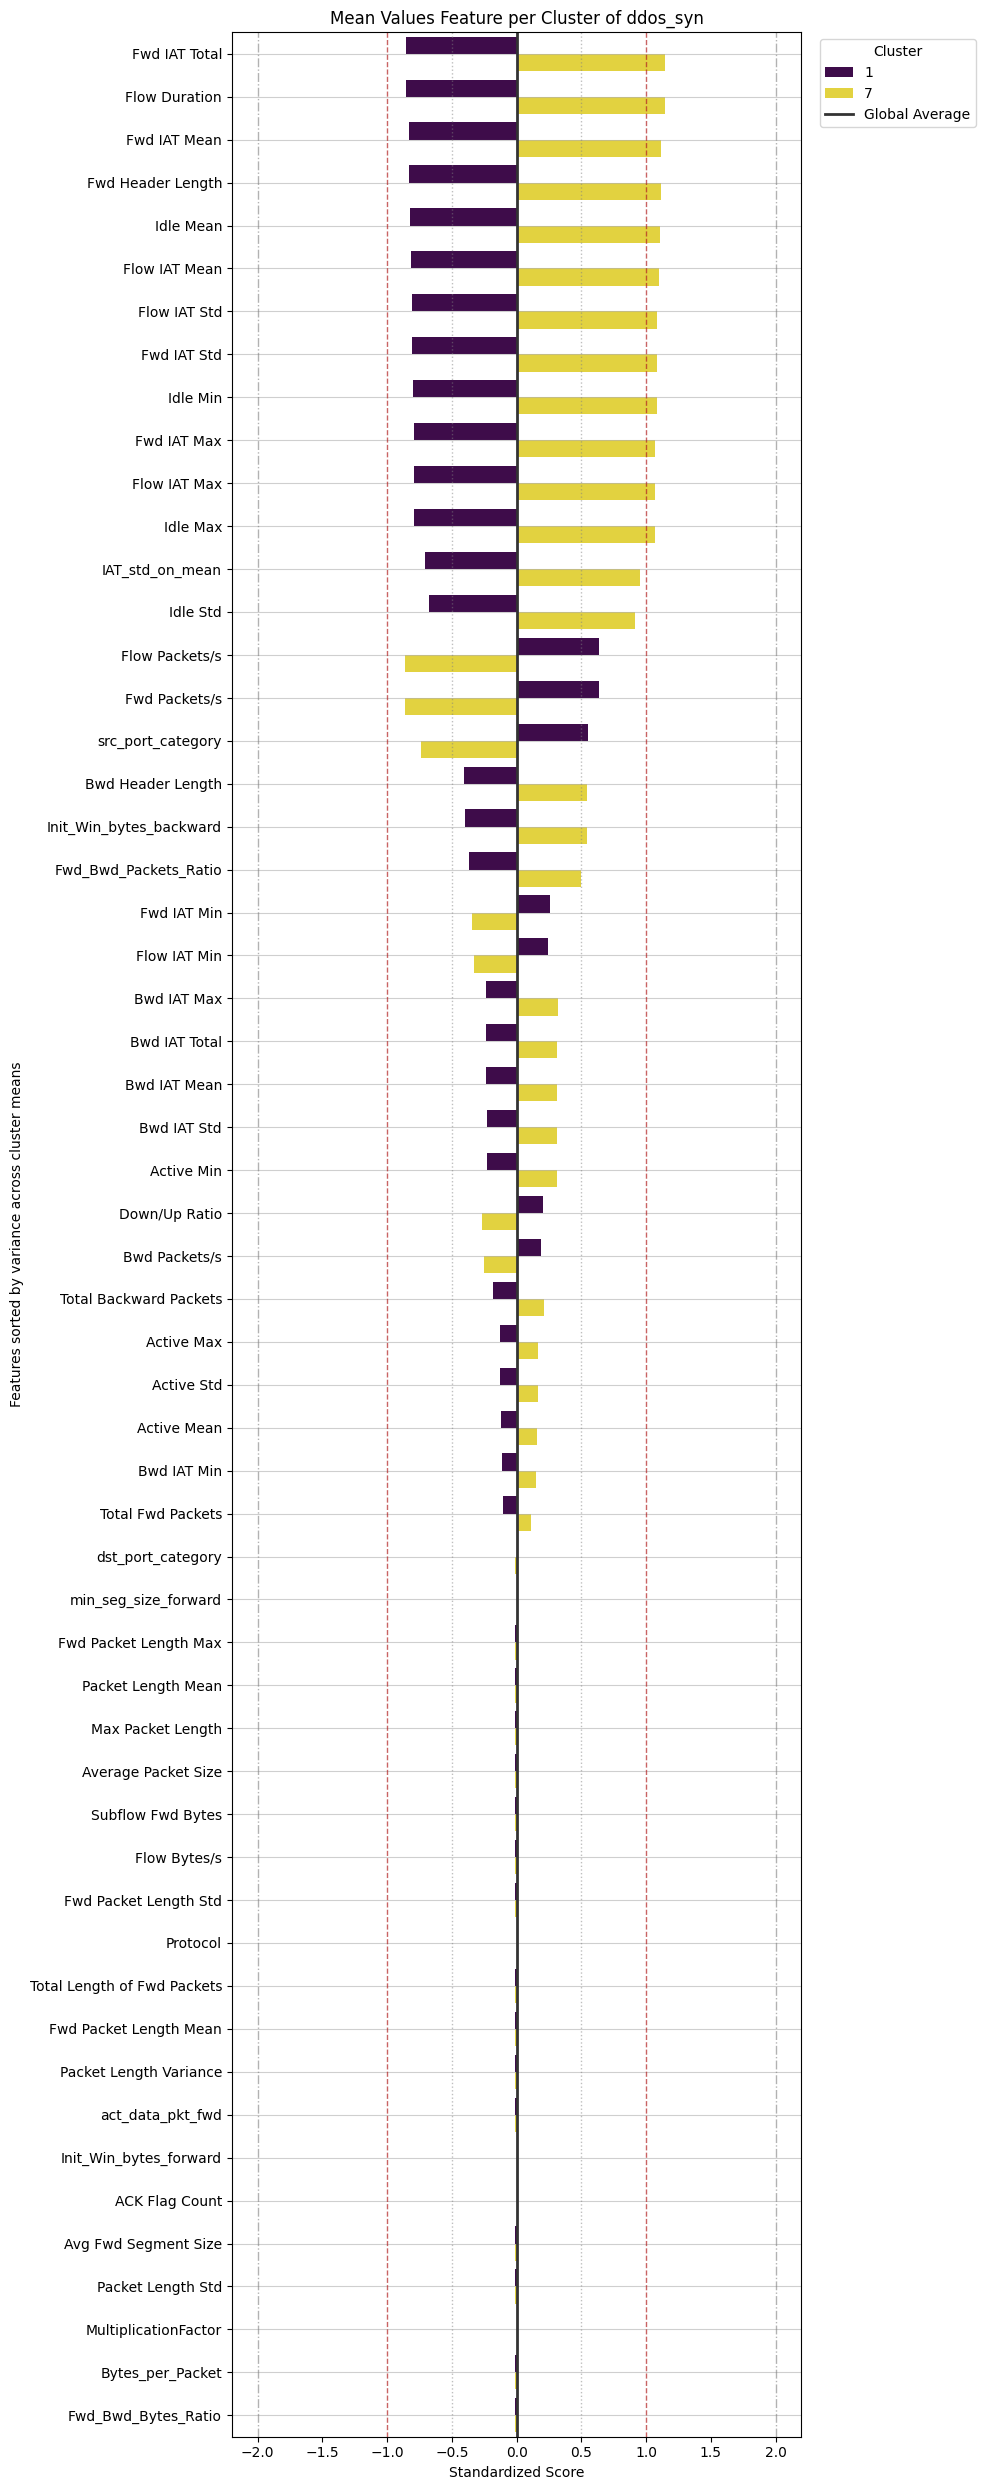

In [62]:
plotMeanFeaturesPerCluster(df_syn_scaled, "Mean", "ddos_syn")

### Attack Pattern Investigation – ddos_tftp

In [63]:
df_tftp , df_tftp_scaled = getClassDf("ddos_tftp")

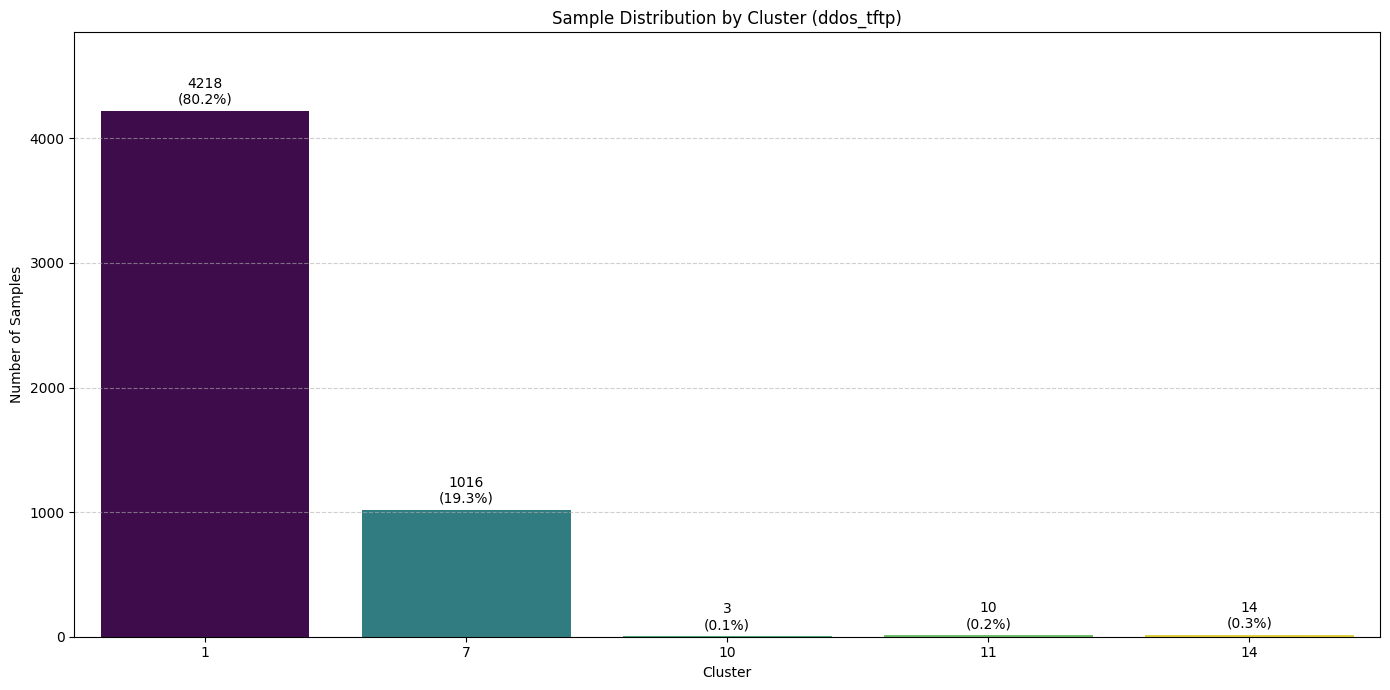

In [64]:
plotClusterSummary(df_tftp,"ddos_tftp")

In [65]:
toDrop = [10,11,14]
df_tftp = drop_clusters(df_tftp, toDrop)
df_tftp_scaled = drop_clusters(df_tftp_scaled, toDrop)

In [66]:
df_tftp.groupby("cluster").agg(["mean", "std", "median"])

Protocol             Flow Duration                            \
            mean  std median          mean           std      median   
cluster                                                                
1            6.0  0.0    6.0  2.751043e+01  4.606734e+02         1.0   
7            6.0  0.0    6.0  1.173903e+07  3.132387e+06  12407175.5   

        Total Fwd Packets                  Total Backward Packets  ...  \
                     mean       std median                   mean  ...   
cluster                                                            ...   
1                2.000948  0.043545    2.0               0.230915  ...   
7                4.019685  0.197537    4.0               0.421260  ...   

        Fwd_Bwd_Packets_Ratio Fwd_Bwd_Bytes_Ratio              \
                       median                mean  std median   
cluster                                                         
1                2.000000e+12                 1.0  0.0    1.0   
7                4.000000e+12                 1.0  0.0    1.0   

        src_port_category                  dst_port_category                   
                     mean       std median              mean       std median  
cluster                                                                        
1                1.062352  0.297249    1.0          1.241347  0.461542    1.0  
7                1.277559  0.488012    1.0          1.237205  0.467499    1.0  

[2 rows x 168 columns]

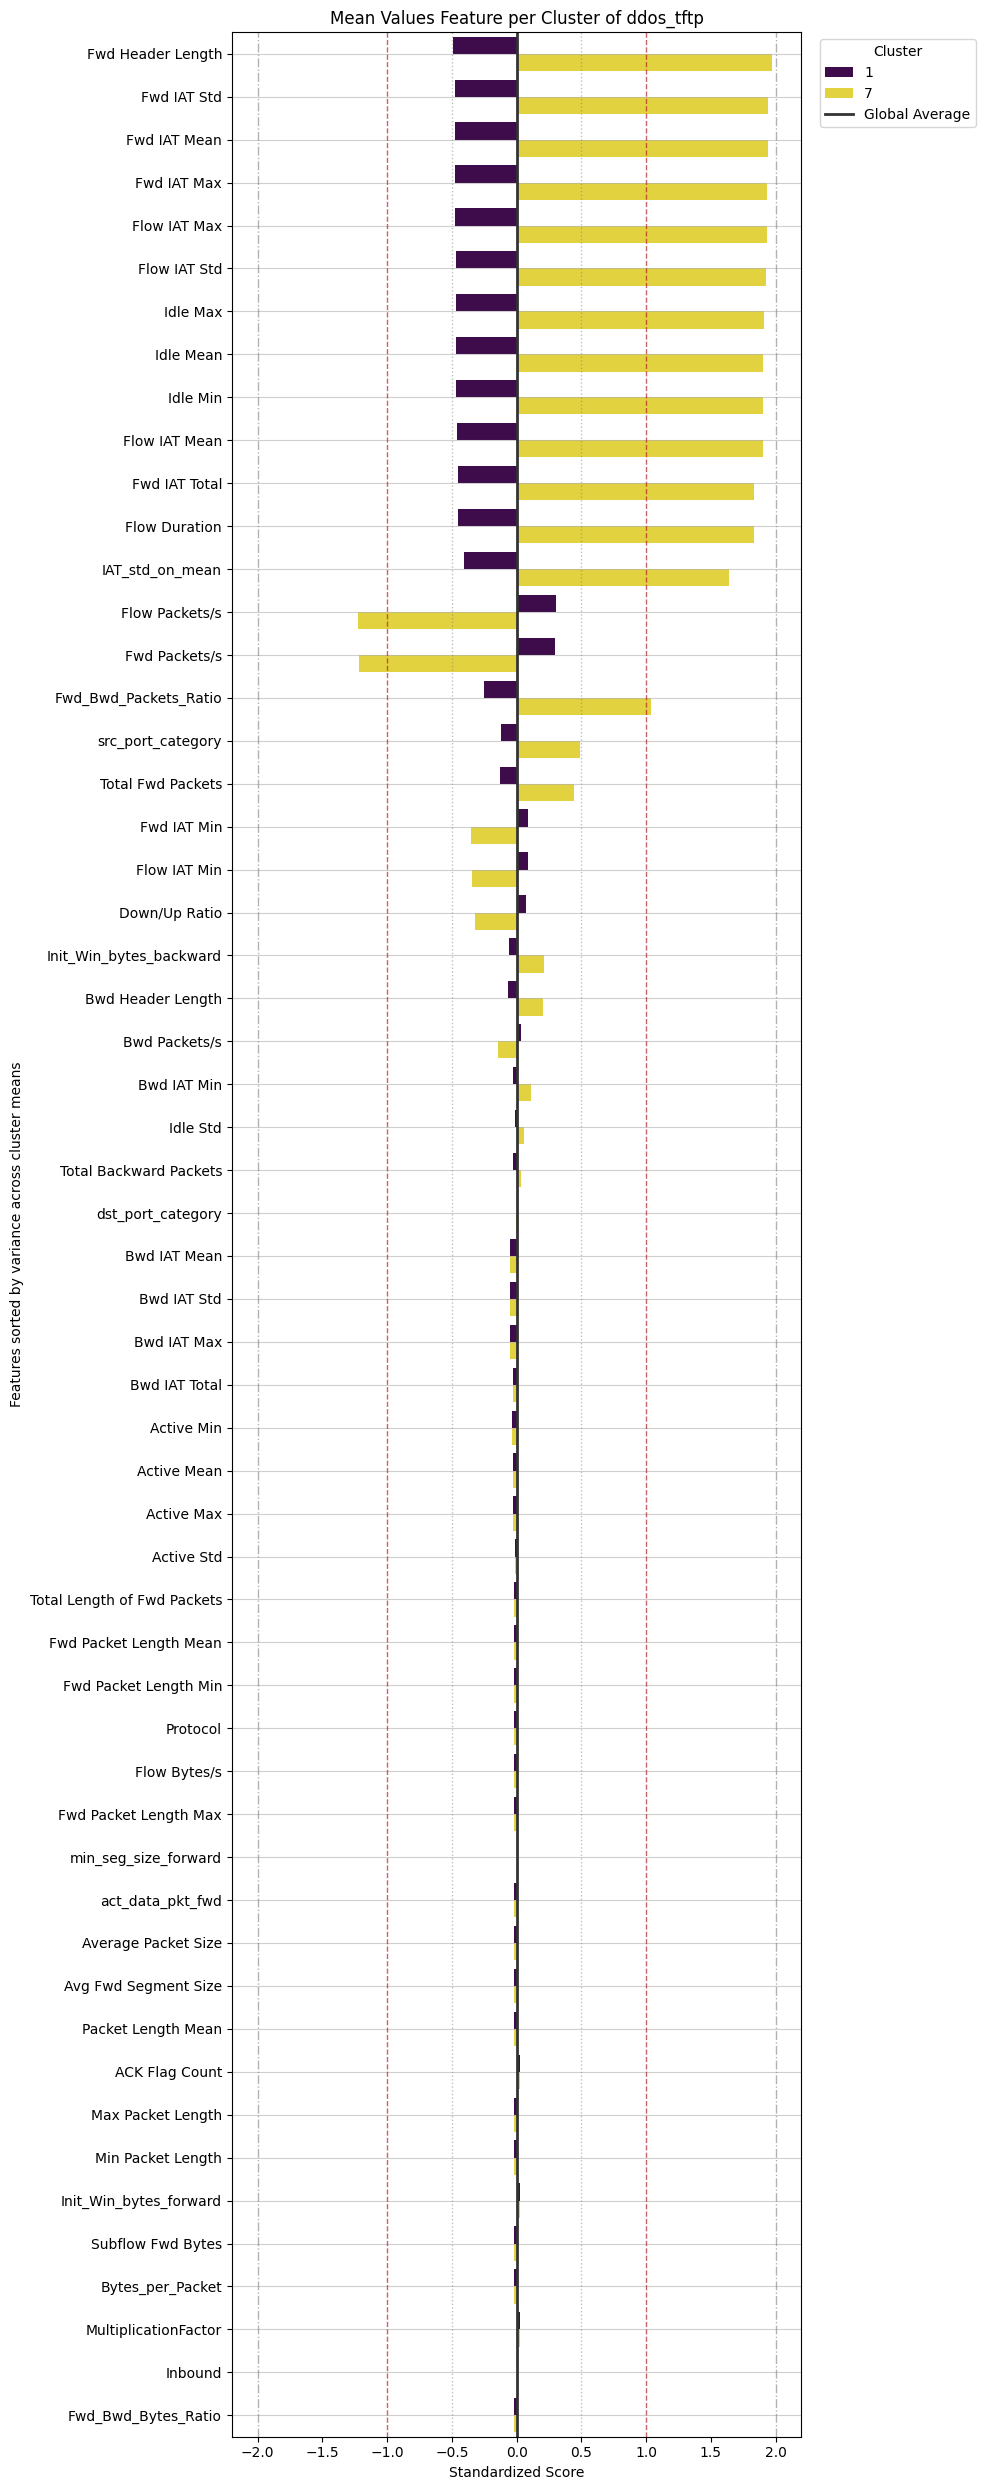

In [67]:
plotMeanFeaturesPerCluster(df_tftp_scaled, "Mean", "ddos_tftp")

### Attack Pattern Investigation – ddos_udp

In [68]:
df_udp , df_udp_scaled = getClassDf("ddos_udp")

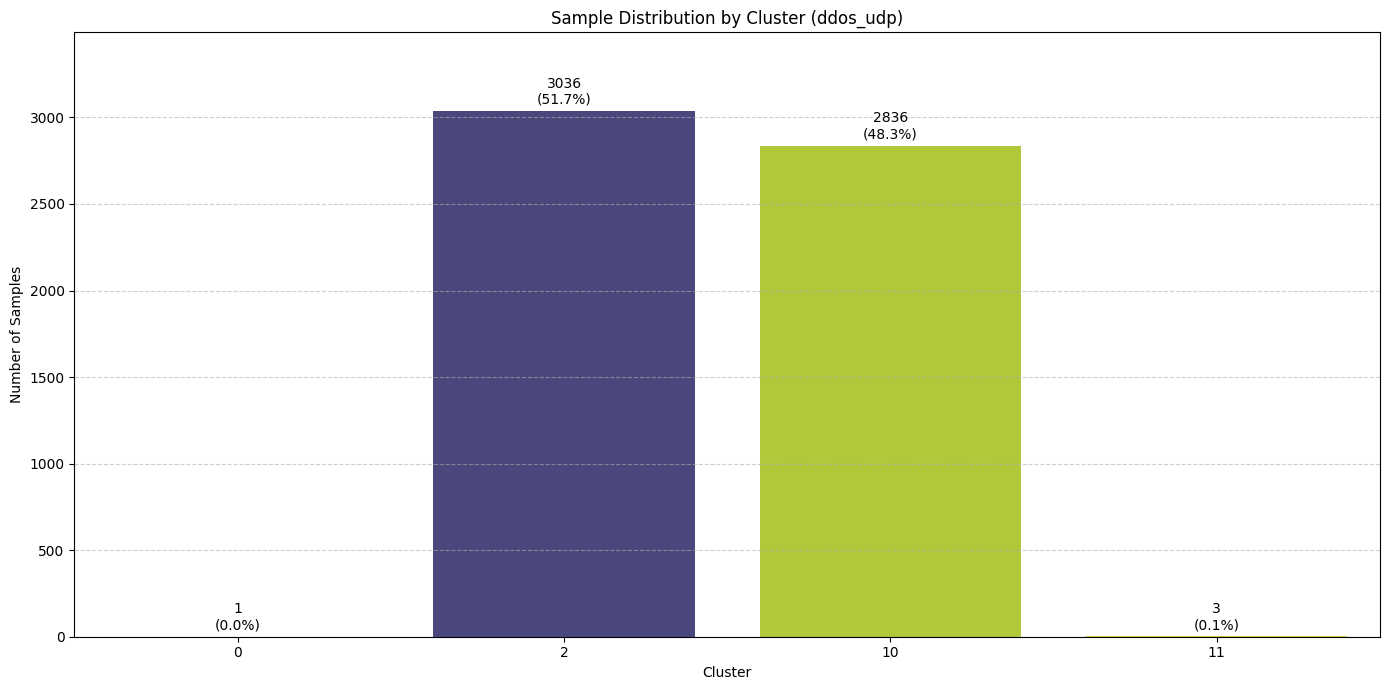

In [69]:
plotClusterSummary(df_udp,"ddos_udp")

In [70]:
toDrop = [0,11]
df_udp = drop_clusters(df_udp, toDrop)
df_udp_scaled = drop_clusters(df_udp_scaled, toDrop)

In [71]:
df_udp.groupby("cluster").agg(["mean", "std", "median"])

Protocol              Flow Duration                           \
            mean  std median           mean            std    median   
cluster                                                                
2           17.0  0.0   17.0  179423.709486  168115.425728  108930.0   
10          17.0  0.0   17.0       6.480959      14.981823       1.0   

        Total Fwd Packets                  Total Backward Packets  ...  \
                     mean       std median                   mean  ...   
cluster                                                            ...   
2                5.317523  3.061259    4.0           1.000000e-12  ...   
10               2.000000  0.000000    2.0           1.000000e-12  ...   

        Fwd_Bwd_Packets_Ratio Fwd_Bwd_Bytes_Ratio                              \
                       median                mean           std        median   
cluster                                                                         
2                4.000000e+12        1.885447e+15  1.117872e+15  1.438000e+15   
10               2.000000e+12        7.726544e+14  3.900303e+13  7.660000e+14   

        src_port_category                  dst_port_category                   
                     mean       std median              mean       std median  
cluster                                                                        
2                1.470685  0.499222    1.0          1.267128  0.443276    1.0  
10               1.459097  0.499119    1.0          1.263047  0.441165    1.0  

[2 rows x 159 columns]

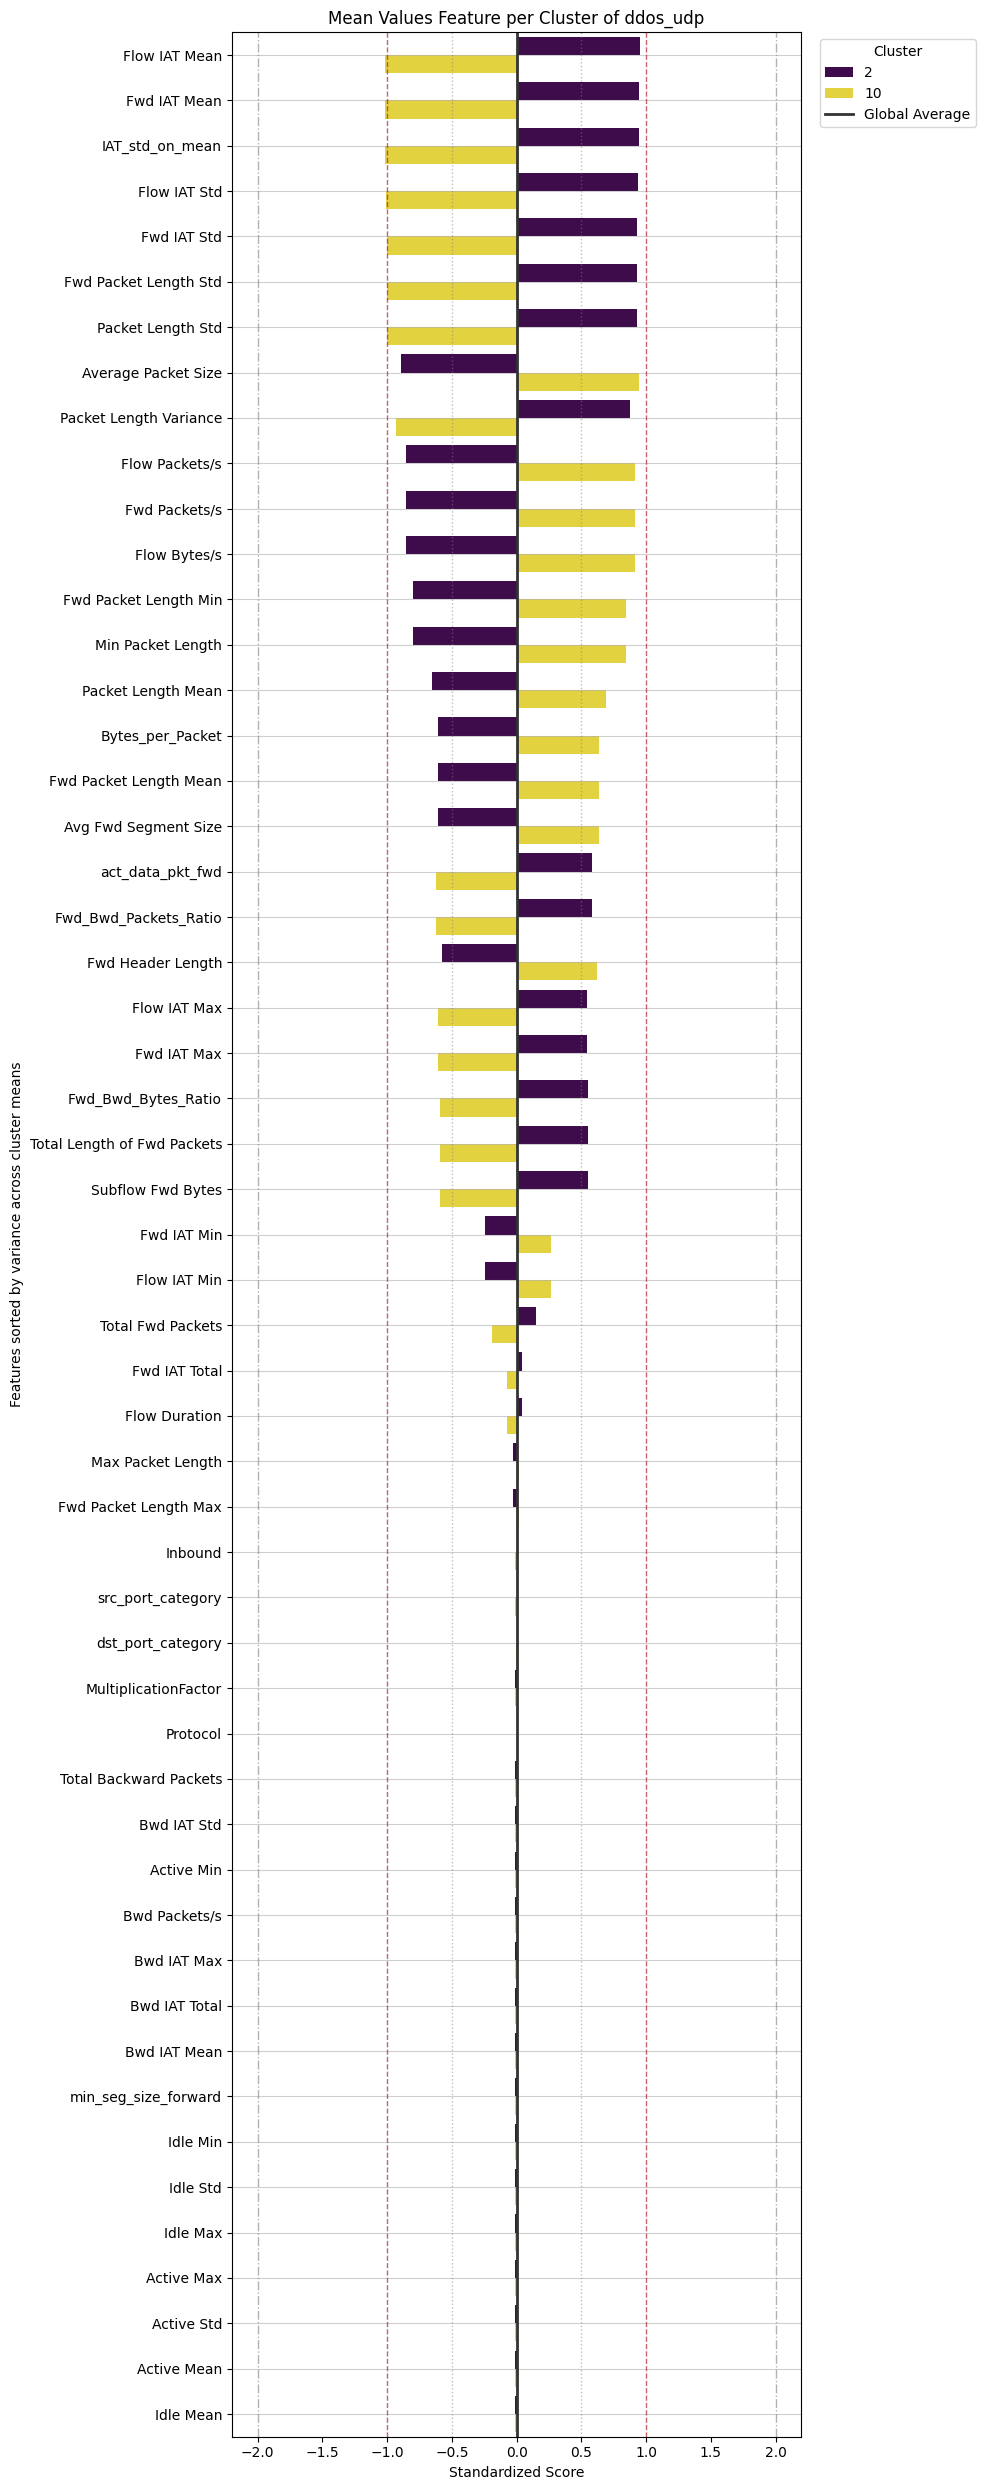

In [75]:
plotMeanFeaturesPerCluster(df_udp_scaled, "Mean", "ddos_udp")

### Attack Pattern Investigation – ddos_udp_lag

In [80]:
df_udp_lag , df_udp_lag_scaled = getClassDf("ddos_udp_lag")

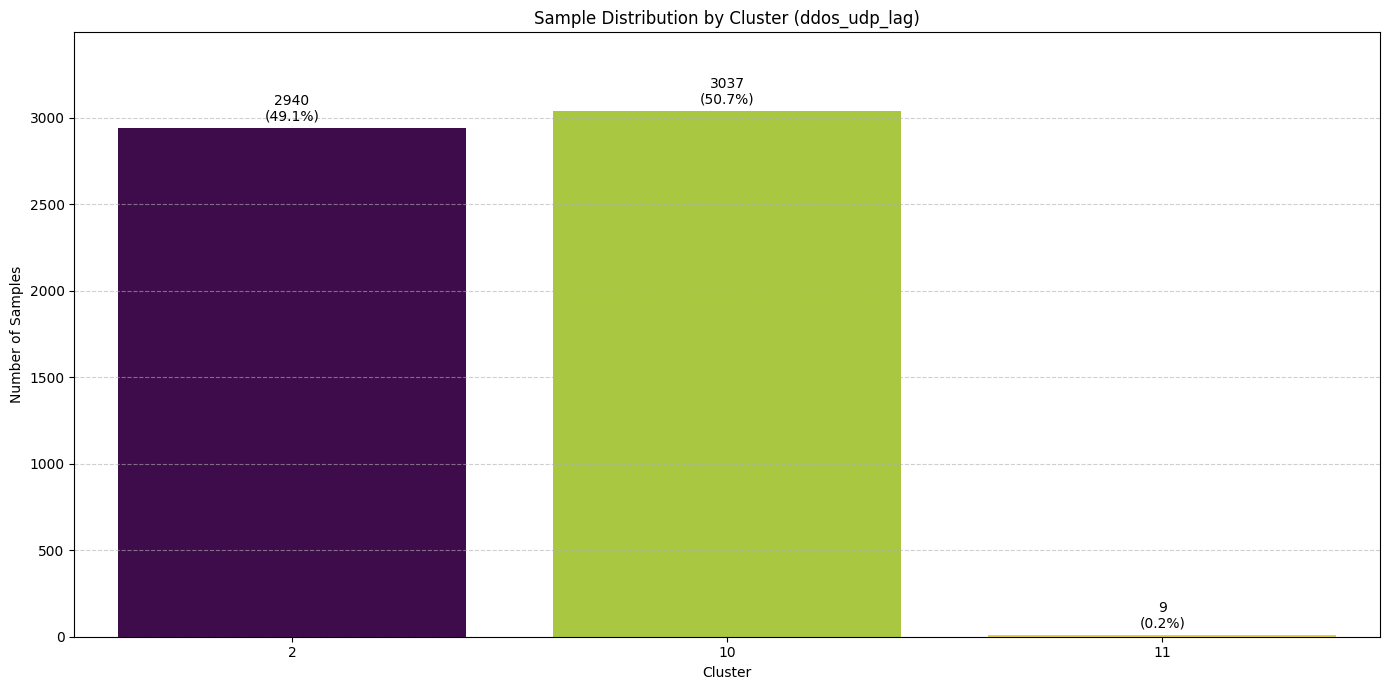

In [81]:
plotClusterSummary(df_udp_lag,"ddos_udp_lag")

In [82]:
toDrop = [11]
df_udp_lag = drop_clusters(df_udp_lag, toDrop)
df_udp_lag_scaled = drop_clusters(df_udp_lag_scaled, toDrop)

In [83]:
df_udp_lag.groupby("cluster").agg(["mean", "std", "median"])

Flow Duration                          Total Fwd Packets            \
                  mean            std    median              mean       std   
cluster                                                                       
2        172995.080272  159106.644236  108918.0          5.191837  2.892647   
10            6.710570      15.262056       1.0          2.000000  0.000000   

               Total Length of Fwd Packets                       \
        median                        mean          std  median   
cluster                                                           
2          4.0                 1842.537415  1057.463554  1438.0   
10         2.0                  773.292065    24.776537   766.0   

        Fwd Packet Length Max  ... Fwd_Bwd_Packets_Ratio Fwd_Bwd_Bytes_Ratio  \
                         mean  ...                median                mean   
cluster                        ...                                             
2                  384.745238  ...          4.000000e+12        1.842537e+15   
10                 386.646032  ...          2.000000e+12        7.732921e+14   

                                    src_port_category                   \
                  std        median              mean       std median   
cluster                                                                  
2        1.057464e+15  1.438000e+15          1.396259  0.489203    1.0   
10       2.477654e+13  7.660000e+14          1.420810  0.493770    1.0   

        dst_port_category                   
                     mean       std median  
cluster                                     
2                1.275510  0.446847    1.0  
10               1.273625  0.445892    1.0  

[2 rows x 111 columns]

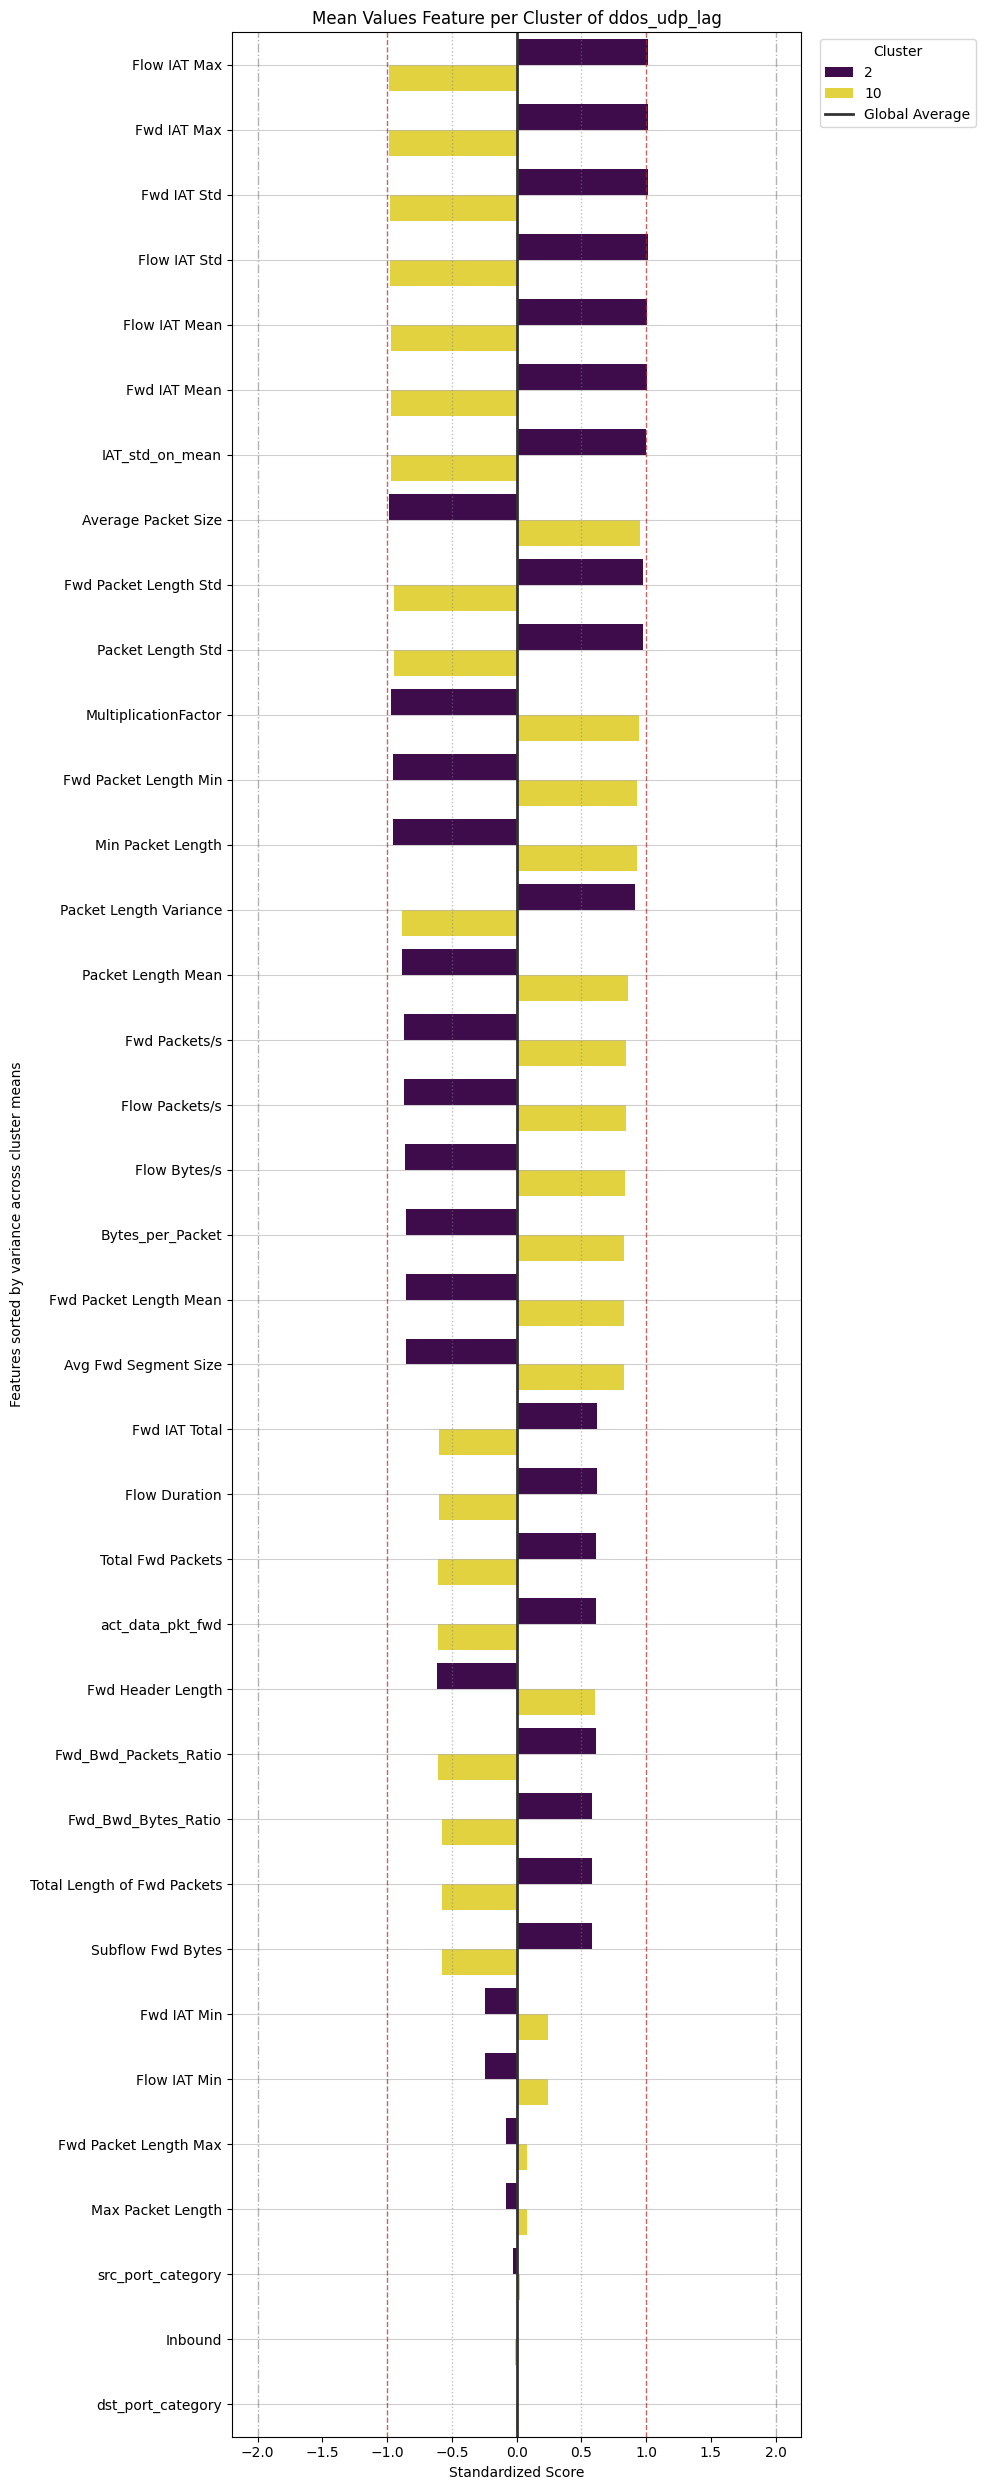

In [85]:
plotMeanFeaturesPerCluster(df_udp_lag_scaled, "Mean", "ddos_udp_lag")

### b)  Which attacks are more similar? According to which feature? Can you explain why according to their definition or attack manner? 

Yes, the clustering clearly reveals that **attacks belonging to different DDoS class show same behavioral patterns**, as they are mapped to **same clusters**.

1. To identify which attacks exhibit the most similar behaviors, we examined the standardized feature distributions of different attack labels co-existing within Clusters, ranking features according to their inter-label variance within the cluster.
2. Features that showed the same values across all clusters, were excluded from the analysis, as they do not contribute to the characterization of the different sub-attack groups.
3. Labels representing less than ~5% of the samples were excluded from the analysis, as they likely correspond to noise, outliers, or rare behaviors that do not significantly contribute to the dominant attack patterns

In [86]:
def getClusterDf(cluster_id):
    df_clustered = df_pd.copy()

    df_cluster = df_clustered[df_clustered["cluster"] == cluster_id].copy().reset_index(drop=True)
    df_cluster = df_cluster.drop(columns="cluster")
    df_cluster = df_cluster.loc[:, df_cluster.nunique() > 1]

    df_cluster_scaled = pd.DataFrame(StandardScaler().fit_transform(df_cluster.drop(columns="label")), columns=df_cluster.drop(columns="label").columns)
    df_cluster_scaled['label'] = df_cluster["label"]
    
    return df_cluster, df_cluster_scaled

In [87]:
def plotLabelSummary(df, cluster):
    counts = df["label"].value_counts().sort_index()
    percentages = (df["label"].value_counts(normalize=True).sort_index() * 100)

    plt.figure(figsize=(14, 7))

    ax = sns.barplot(x=counts.index, y=counts.values, palette='viridis', hue=counts.index, legend=False)

    labels = []
    for i in range(len(counts)):
        c = counts.values[i]
        p = percentages.values[i]
        testo = f'{int(c)}\n({p:.1f}%)'
        labels.append(testo)
        
    for i, container in enumerate(ax.containers):
        ax.bar_label(container, labels=[labels[i]], padding=3)

    plt.title(f"Sample Distribution by Label (cluster {cluster})")
    plt.xlabel("Cluster")
    plt.ylabel("Number of Samples")
    plt.ylim(0, max(counts.values) * 1.15) 
    plt.grid(axis='y', linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

In [88]:
def drop_Labels(df, toDrop):
    for id in toDrop:
        df = df[df["label"] != id].reset_index(drop=True)
    return df

In [89]:
def plotMeanFeaturesPerLabel(df_s, mesure, cluster_id):
    if mesure == "Mean":
        df_mesure = df_s.groupby("label").mean().reset_index()
        sorted_features = df_s.groupby("label").mean().var().sort_values(ascending=False).index
    elif mesure == "Median":
        df_mesure = df_s.groupby("label").median().reset_index()
        sorted_features = df_s.groupby("label").median().var().sort_values(ascending=False).index
    else:
        print("Mesure invalid")
        return
    
    df_melted = df_mesure.melt(id_vars="label", var_name="Feature", value_name="Standardized Value")

    plt.figure(figsize=(15, 25)) 

    sns.barplot(data=df_melted, x="Standardized Value", y="Feature", hue="label", palette="viridis", order=sorted_features)

    plt.axvline(0, color='#333333', linewidth=2, label='Global Average') 
    plt.axvline(x=1, color='firebrick', linestyle='--', linewidth=1, alpha=0.7)
    plt.axvline(x=-1, color='firebrick', linestyle='--', linewidth=1, alpha=0.7)
    plt.axvline(x=0.5, color='gray', linestyle=':', linewidth=1, alpha=0.5)
    plt.axvline(x=-0.5, color='gray', linestyle=':', linewidth=1, alpha=0.5)
    plt.axvline(x=2, color='gray', linestyle='-.', linewidth=1, alpha=0.6)
    plt.axvline(x=-2, color='gray', linestyle='-.', linewidth=1, alpha=0.6)

    plt.title(f"{mesure} Values Feature per Label of cluster {cluster_id}")
    plt.xlabel("Standardized Score")
    plt.ylabel("Features")
    plt.legend(title="Label", bbox_to_anchor=(1.02, 1), loc='upper left')

    plt.grid(axis='y', alpha=0.6)
    plt.tight_layout()
    plt.show()

### Attack Pattern Investigation – cluster 0

In [90]:
df_cluster_0 , df_cluster_0_scaled = getClusterDf(0)

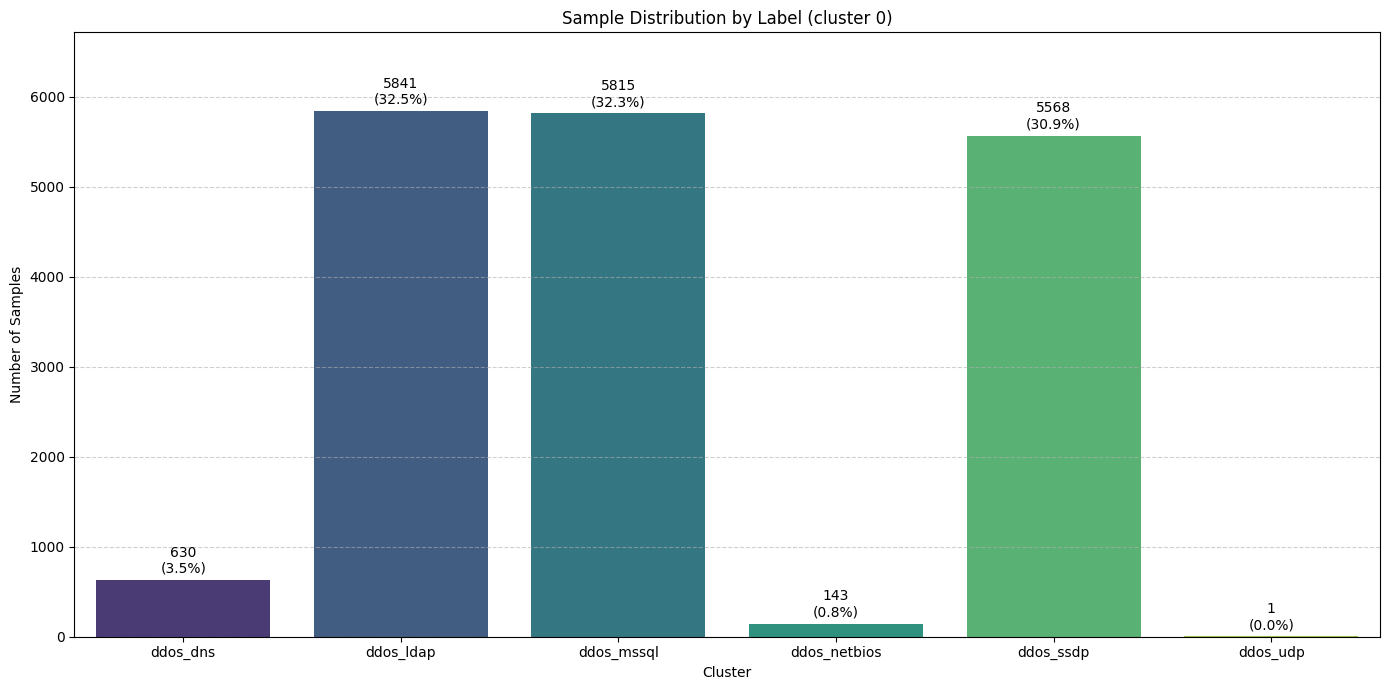

In [91]:
plotLabelSummary(df_cluster_0,0)

In [92]:
toDrop = ["ddos_dns","ddos_netbios", "ddos_udp"]
df_cluster_0 = drop_Labels(df_cluster_0, toDrop)
df_cluster_0_scaled = drop_Labels(df_cluster_0_scaled, toDrop)

In [93]:
df_cluster_0.groupby("label").agg(["mean", "std", "median"])

Flow Duration                   Total Length of Fwd Packets  \
                    mean        std median                        mean   
label                                                                    
ddos_ldap       5.000514  16.758605    1.0                 2937.762712   
ddos_mssql      5.530353  17.903308    1.0                 2936.906621   
ddos_ssdp       3.082435   6.362827    2.0                 2909.942529   

                              Fwd Packet Length Max                     \
                  std  median                  mean        std  median   
label                                                                    
ddos_ldap   26.181542  2944.0           1468.881356  13.090771  1472.0   
ddos_mssql  27.499946  2944.0           1468.453310  13.749973  1472.0   
ddos_ssdp   69.579276  2944.0           1454.971264  34.789638  1472.0   

           Fwd Packet Length Min  ... Fwd_Bwd_Bytes_Ratio src_port_category  \
                            mean  ...              median              mean   
label                             ...                                         
ddos_ldap            1468.881356  ...        2.944000e+15          0.000342   
ddos_mssql           1468.453310  ...        2.944000e+15          0.002236   
ddos_ssdp            1454.971264  ...        2.944000e+15          0.000000   

                            dst_port_category                   hour       \
                 std median              mean       std median  mean  std   
label                                                                       
ddos_ldap   0.026169    0.0          1.240199  0.468896    1.0  11.0  0.0   
ddos_mssql  0.062857    0.0          1.239209  0.462241    1.0  11.0  0.0   
ddos_ssdp   0.000000    0.0          1.235812  0.455566    1.0  12.0  0.0   

                   
           median  
label              
ddos_ldap    11.0  
ddos_mssql   11.0  
ddos_ssdp    12.0  

[3 rows x 87 columns]

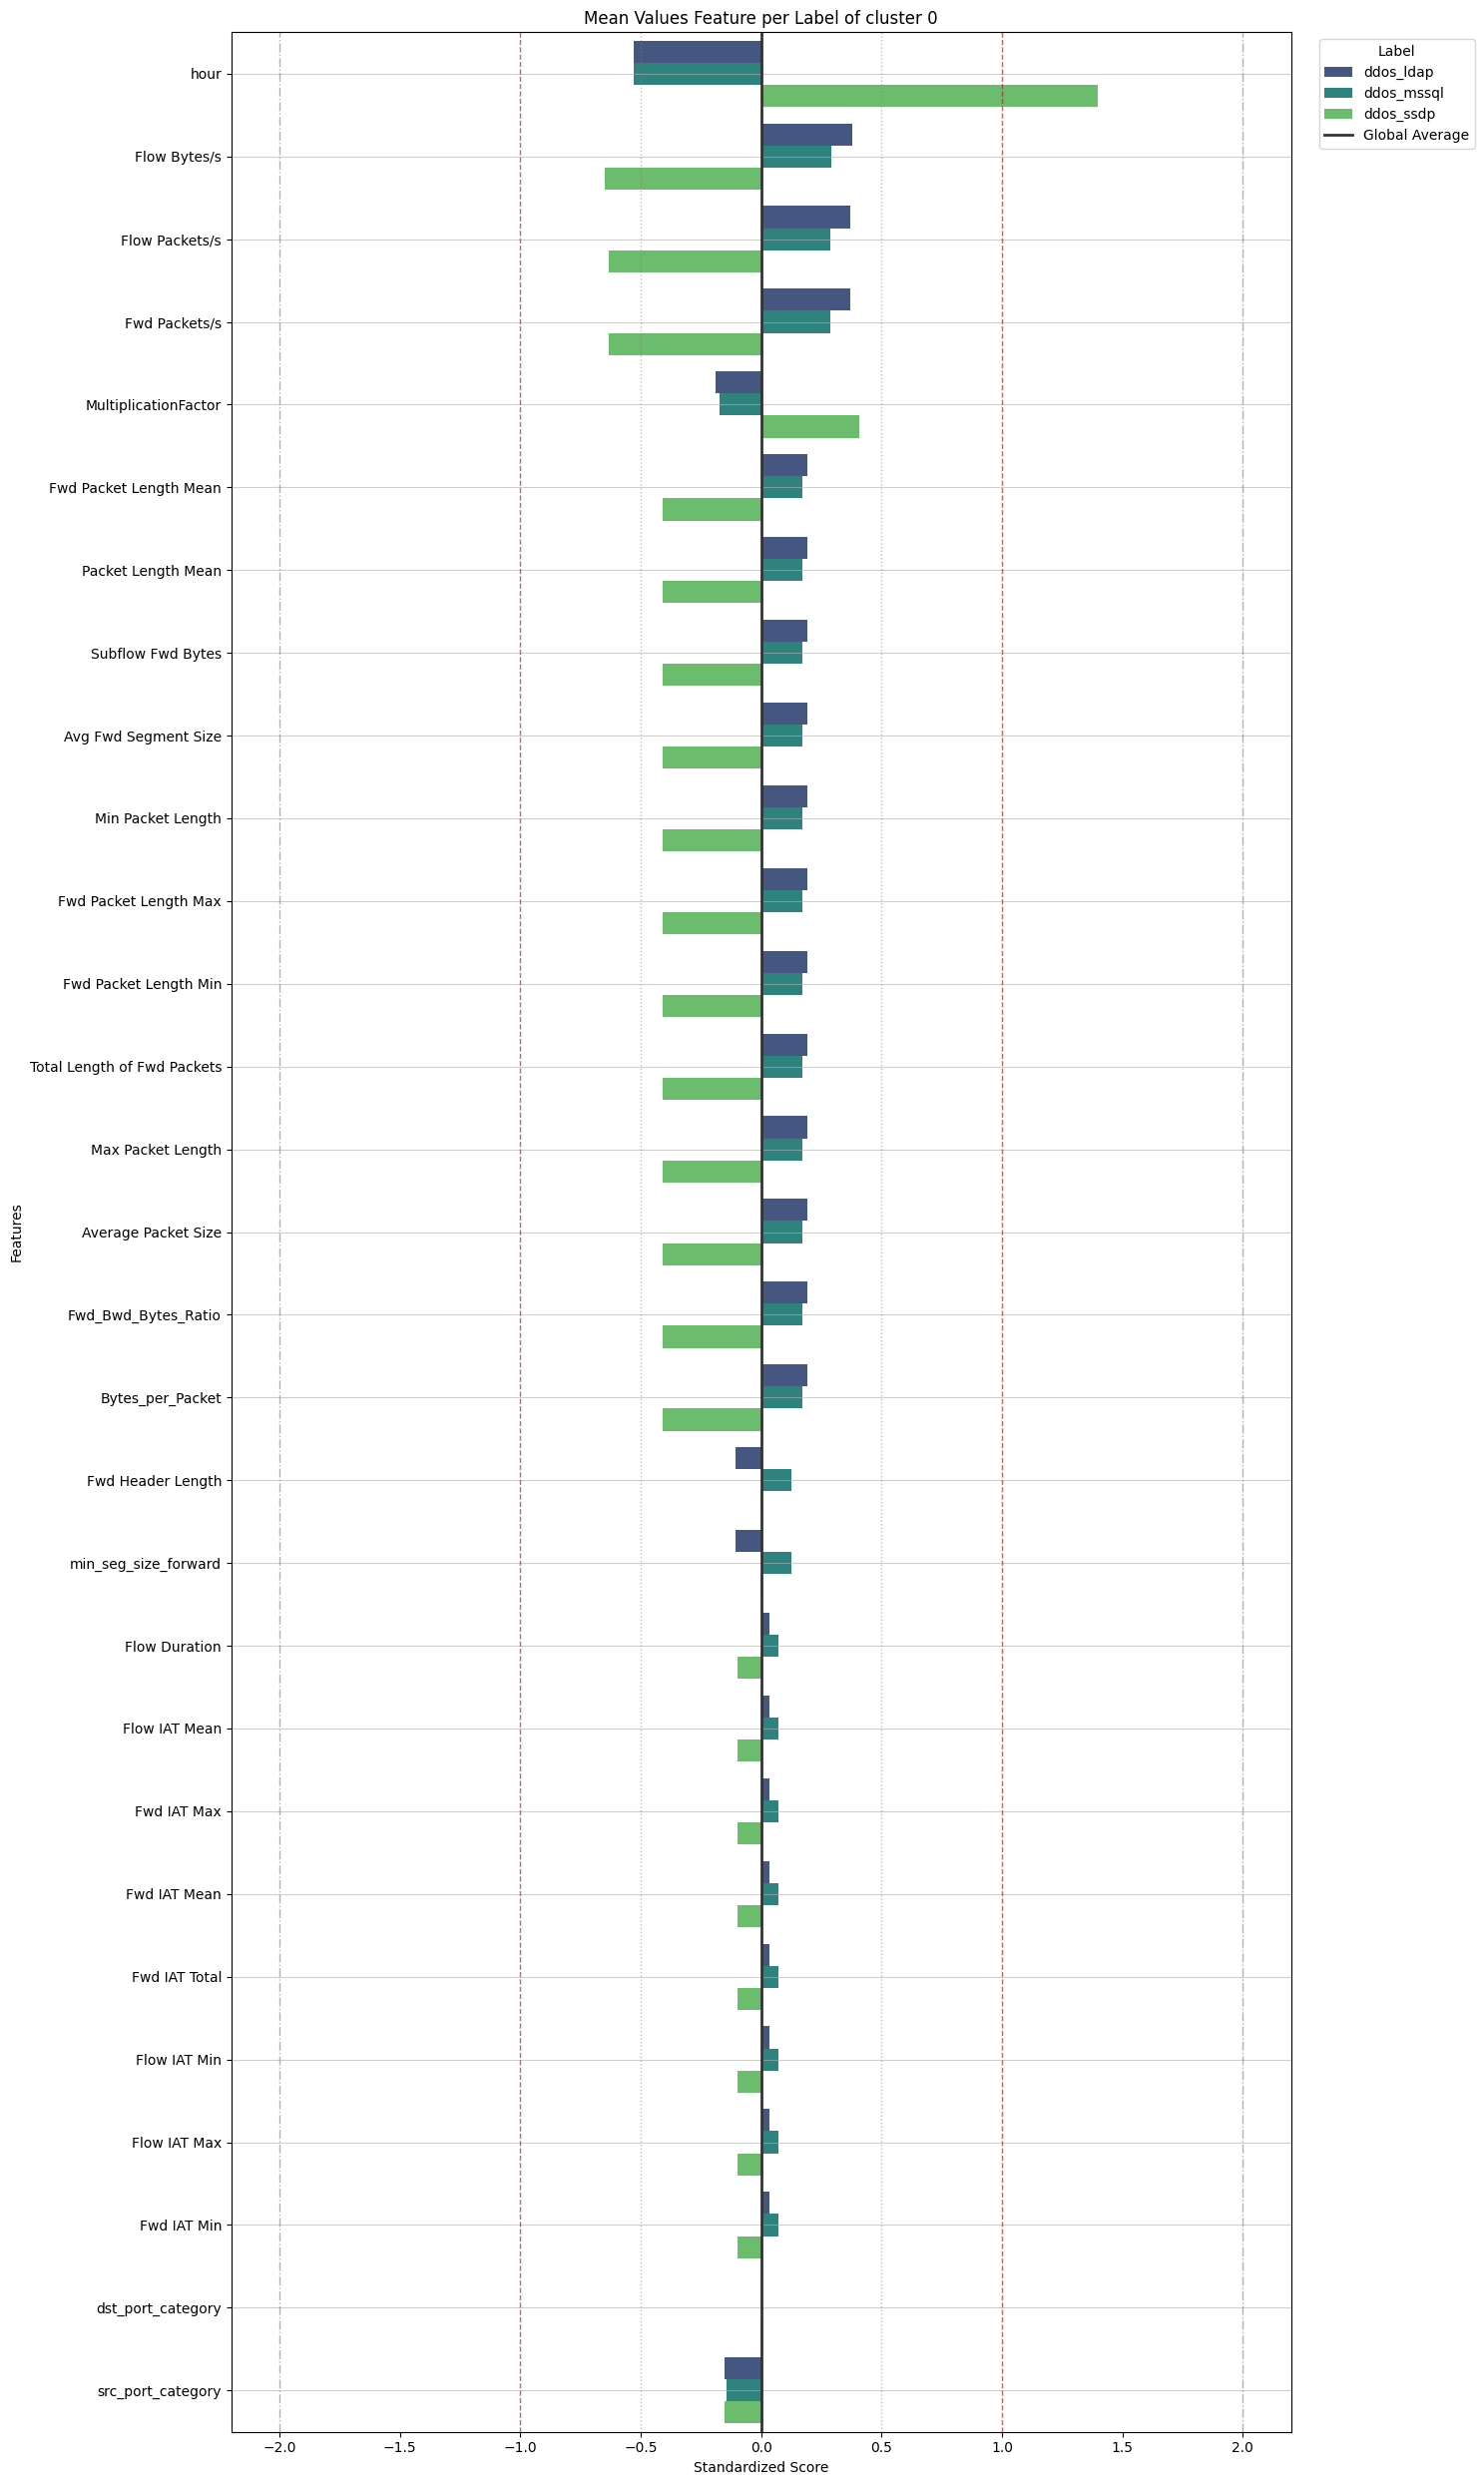

In [94]:
plotMeanFeaturesPerLabel(df_cluster_0_scaled, "Mean", 0)

### Attack Pattern Investigation – cluster 1

In [95]:
df_cluster_1 , df_cluster_1_scaled = getClusterDf(1)

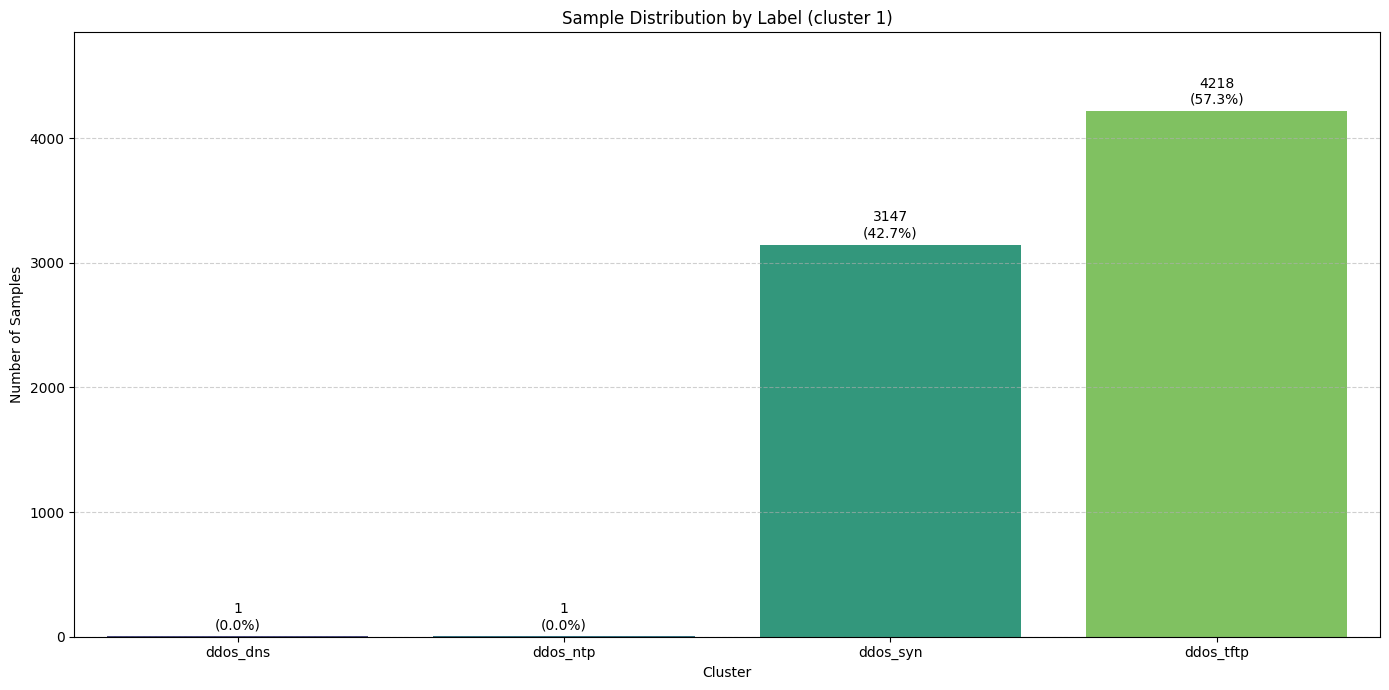

In [96]:
plotLabelSummary(df_cluster_1,1)

In [97]:
toDrop = ["ddos_dns","ddos_ntp"]
df_cluster_1 = drop_Labels(df_cluster_1, toDrop)
df_cluster_1_scaled = drop_Labels(df_cluster_1_scaled, toDrop)

In [98]:
df_cluster_1.groupby("label").agg(["mean", "std", "median"])

Flow Duration                    Total Fwd Packets                   \
                   mean         std median              mean       std median   
label                                                                           
ddos_syn      18.806165   33.194048    1.0          2.000000  0.000000    2.0   
ddos_tftp     27.510431  460.673412    1.0          2.000948  0.043545    2.0   

          Total Backward Packets                         Flow Packets/s  ...  \
                            mean       std        median           mean  ...   
label                                                                    ...   
ddos_syn                0.236416  0.645811  1.000000e-12   1.454924e+06  ...   
ddos_tftp               0.230915  0.639222  1.000000e-12   1.470863e+06  ...   

          Fwd_Bwd_Packets_Ratio src_port_category                   \
                         median              mean       std median   
label                                                                
ddos_syn           2.000000e+12          1.949476  0.289115    2.0   
ddos_tftp          2.000000e+12          1.062352  0.297249    1.0   

          dst_port_category                   hour              
                       mean       std median  mean  std median  
label                                                           
ddos_syn           1.245949  0.470231    1.0  13.0  0.0   13.0  
ddos_tftp          1.241347  0.461542    1.0  13.0  0.0   13.0  

[2 rows x 87 columns]

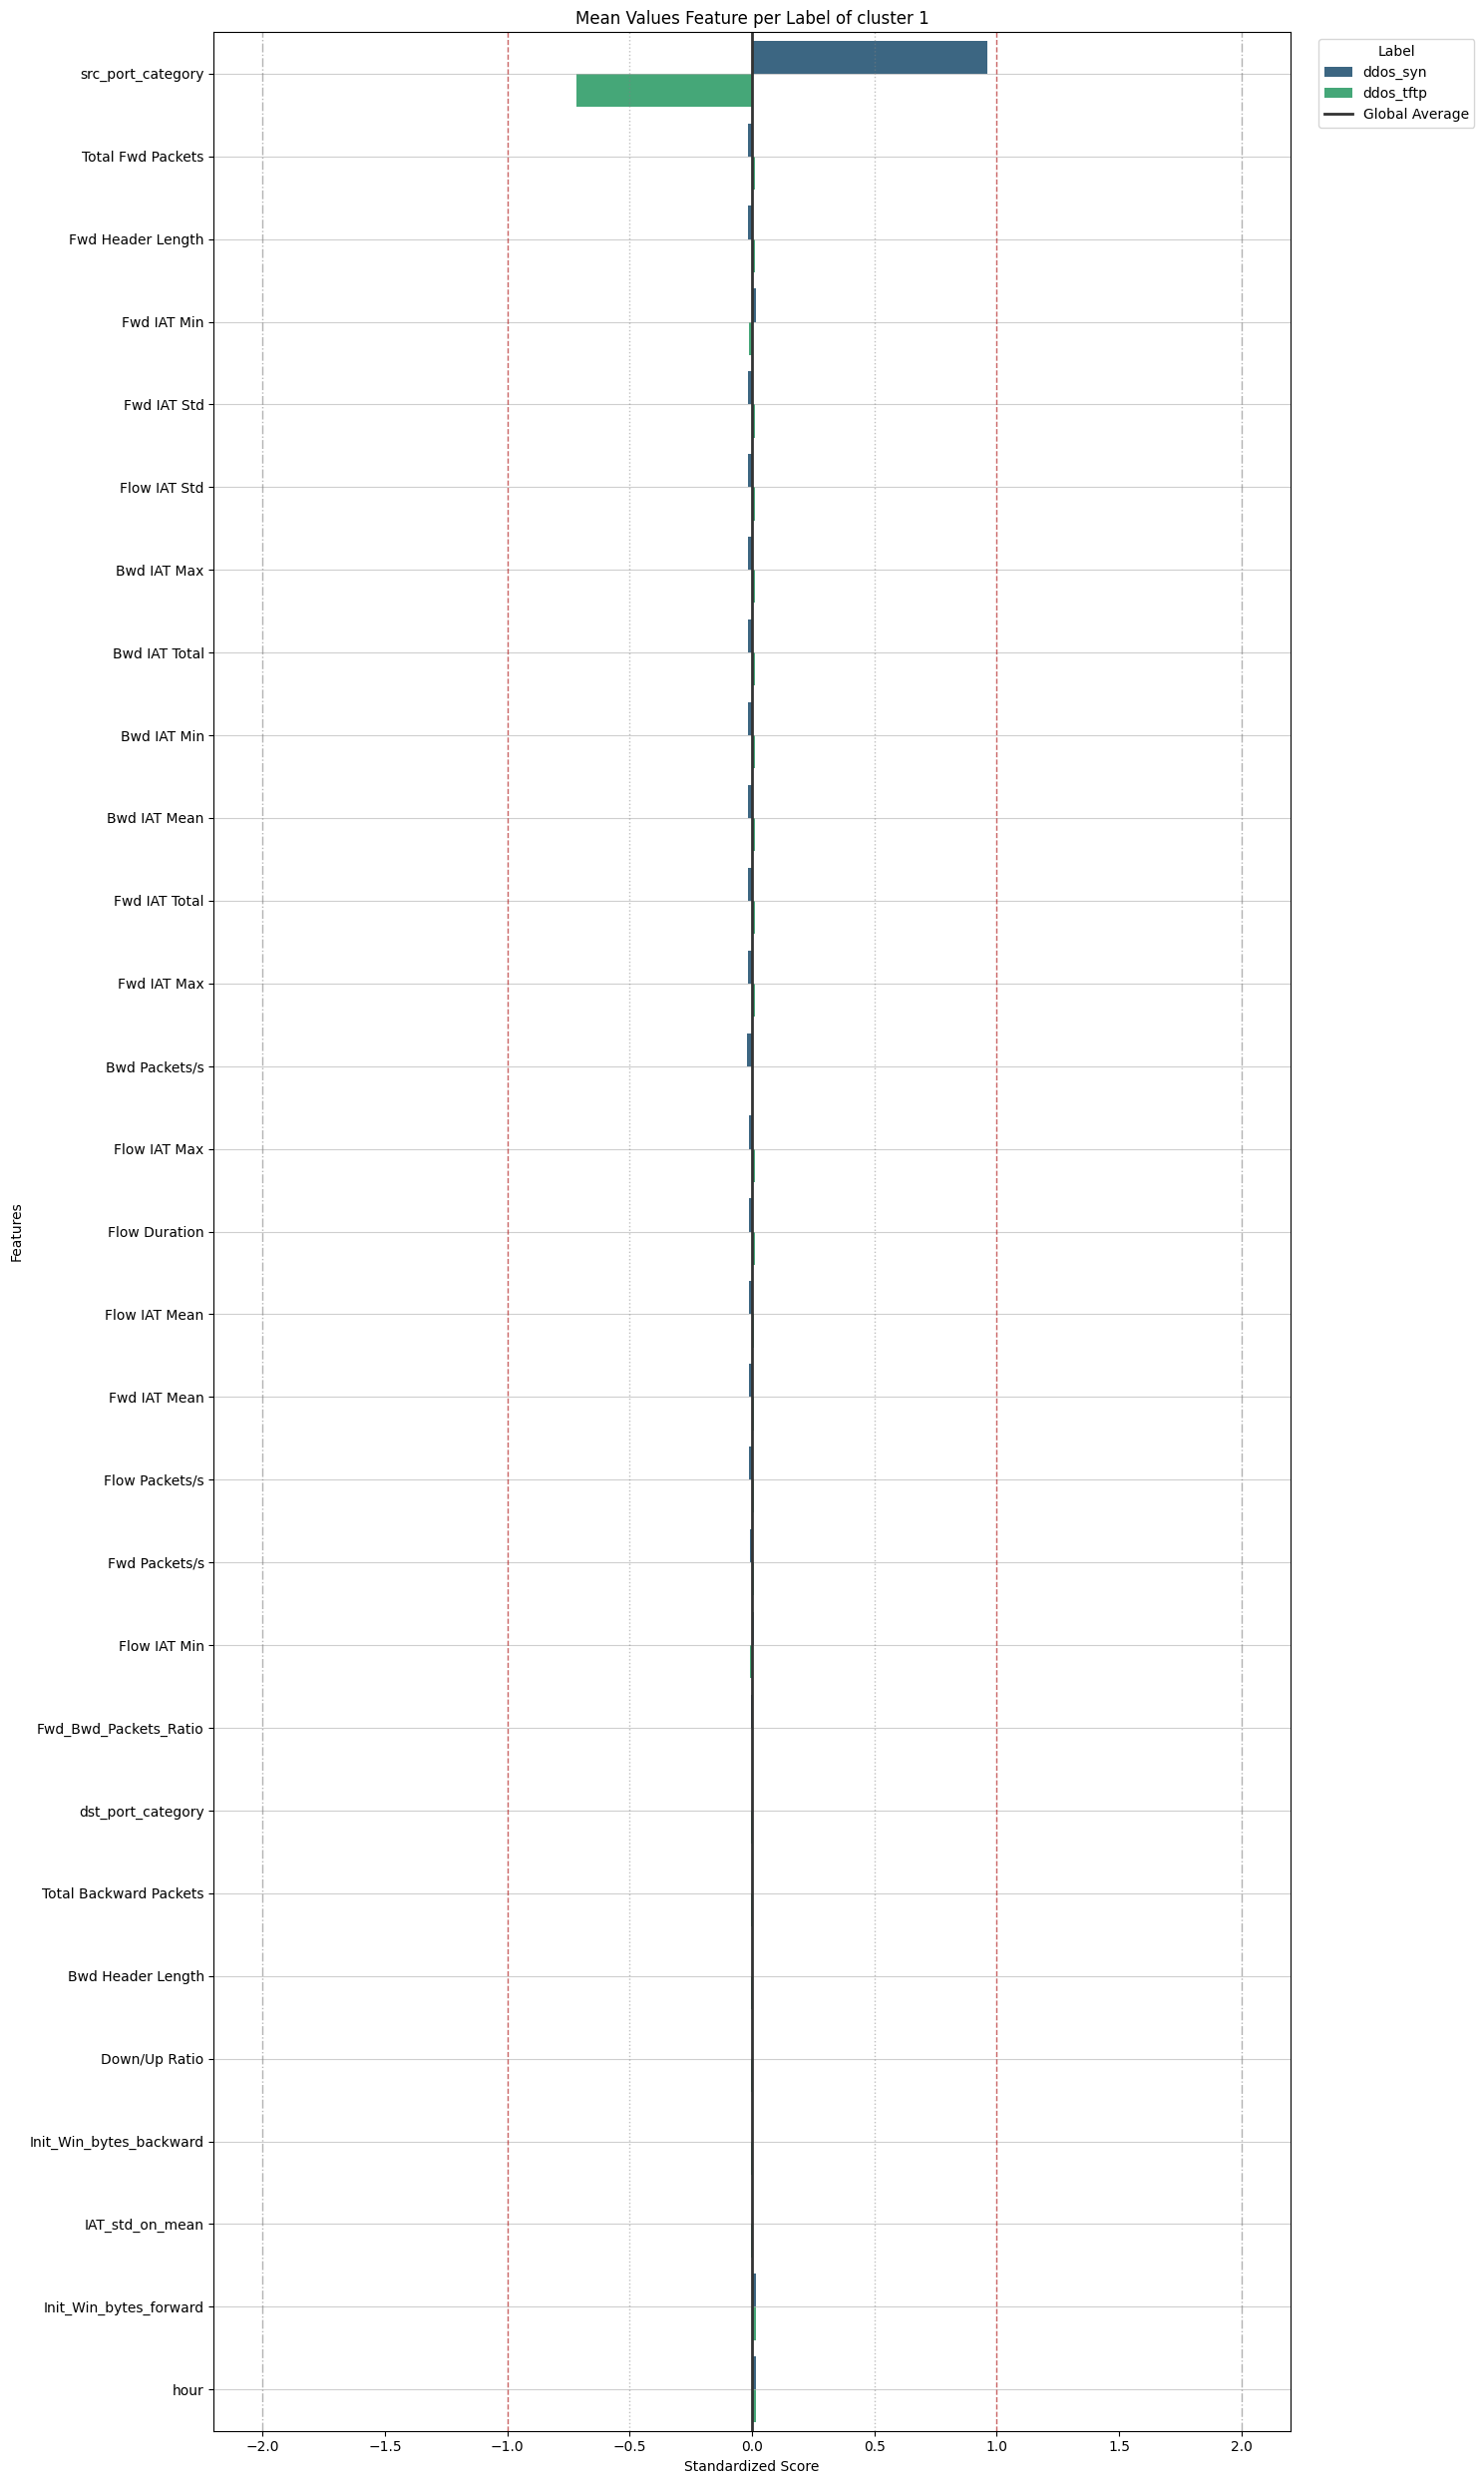

In [99]:
plotMeanFeaturesPerLabel(df_cluster_1_scaled, "Mean", 1)

### Attack Pattern Investigation – cluster 2

In [100]:
df_cluster_2 , df_cluster_2_scaled = getClusterDf(2)

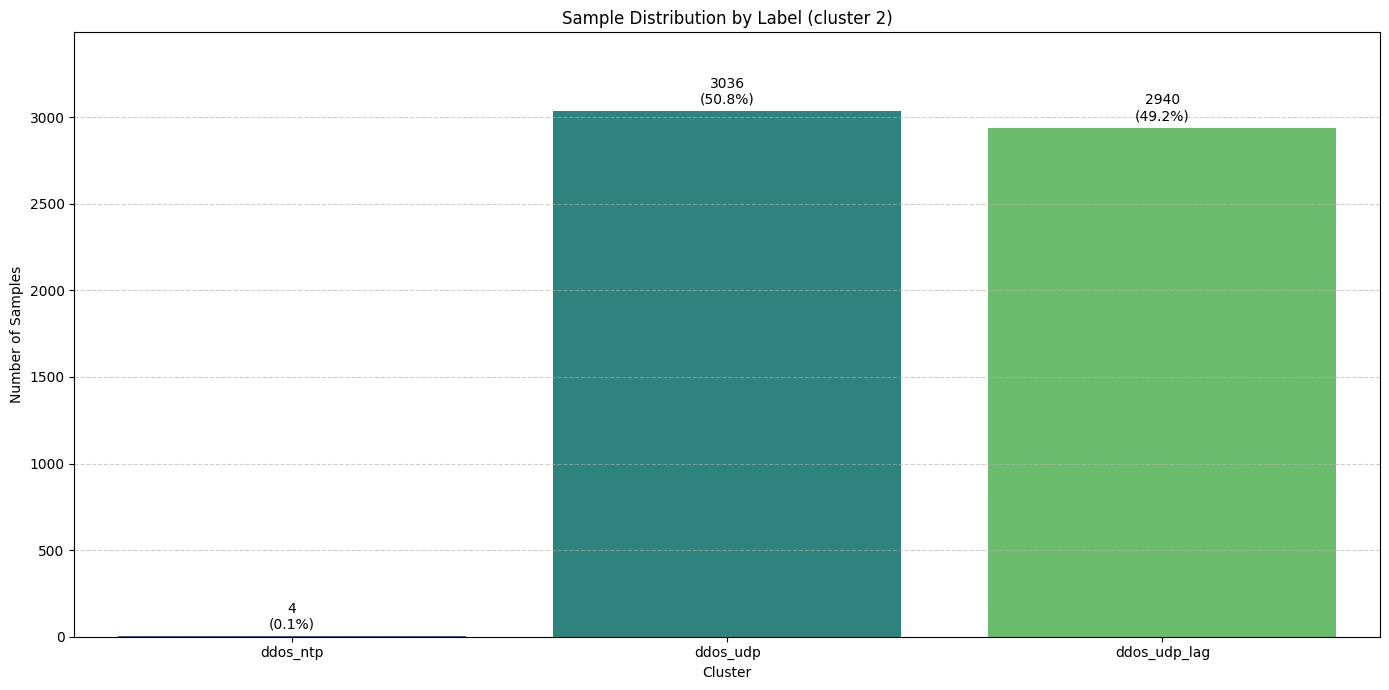

In [101]:
plotLabelSummary(df_cluster_2, 2)

In [104]:
toDrop = ["ddos_ntp"]
df_cluster_2 = drop_Labels(df_cluster_2, toDrop)
df_cluster_2_scaled = drop_Labels(df_cluster_2_scaled, toDrop)

In [105]:
df_cluster_2.groupby("label").agg(["mean", "std", "median"])

Protocol              Flow Duration                           \
                 mean  std median           mean            std    median   
label                                                                       
ddos_udp         17.0  0.0   17.0  179423.709486  168115.425728  108930.0   
ddos_udp_lag     17.0  0.0   17.0  172995.080272  159106.644236  108918.0   

             Total Fwd Packets                  Total Backward Packets  ...  \
                          mean       std median                   mean  ...   
label                                                                   ...   
ddos_udp              5.317523  3.061259    4.0           1.000000e-12  ...   
ddos_udp_lag          5.191837  2.892647    4.0           1.000000e-12  ...   

             Fwd_Bwd_Bytes_Ratio src_port_category                   \
                          median              mean       std median   
label                                                                 
ddos_udp            1.438000e+15          1.470685  0.499222    1.0   
ddos_udp_lag        1.438000e+15          1.396259  0.489203    1.0   

             dst_port_category                   hour              
                          mean       std median  mean  std median  
label                                                              
ddos_udp              1.267128  0.443276    1.0  12.0  0.0   12.0  
ddos_udp_lag          1.275510  0.446847    1.0  13.0  0.0   13.0  

[2 rows x 138 columns]

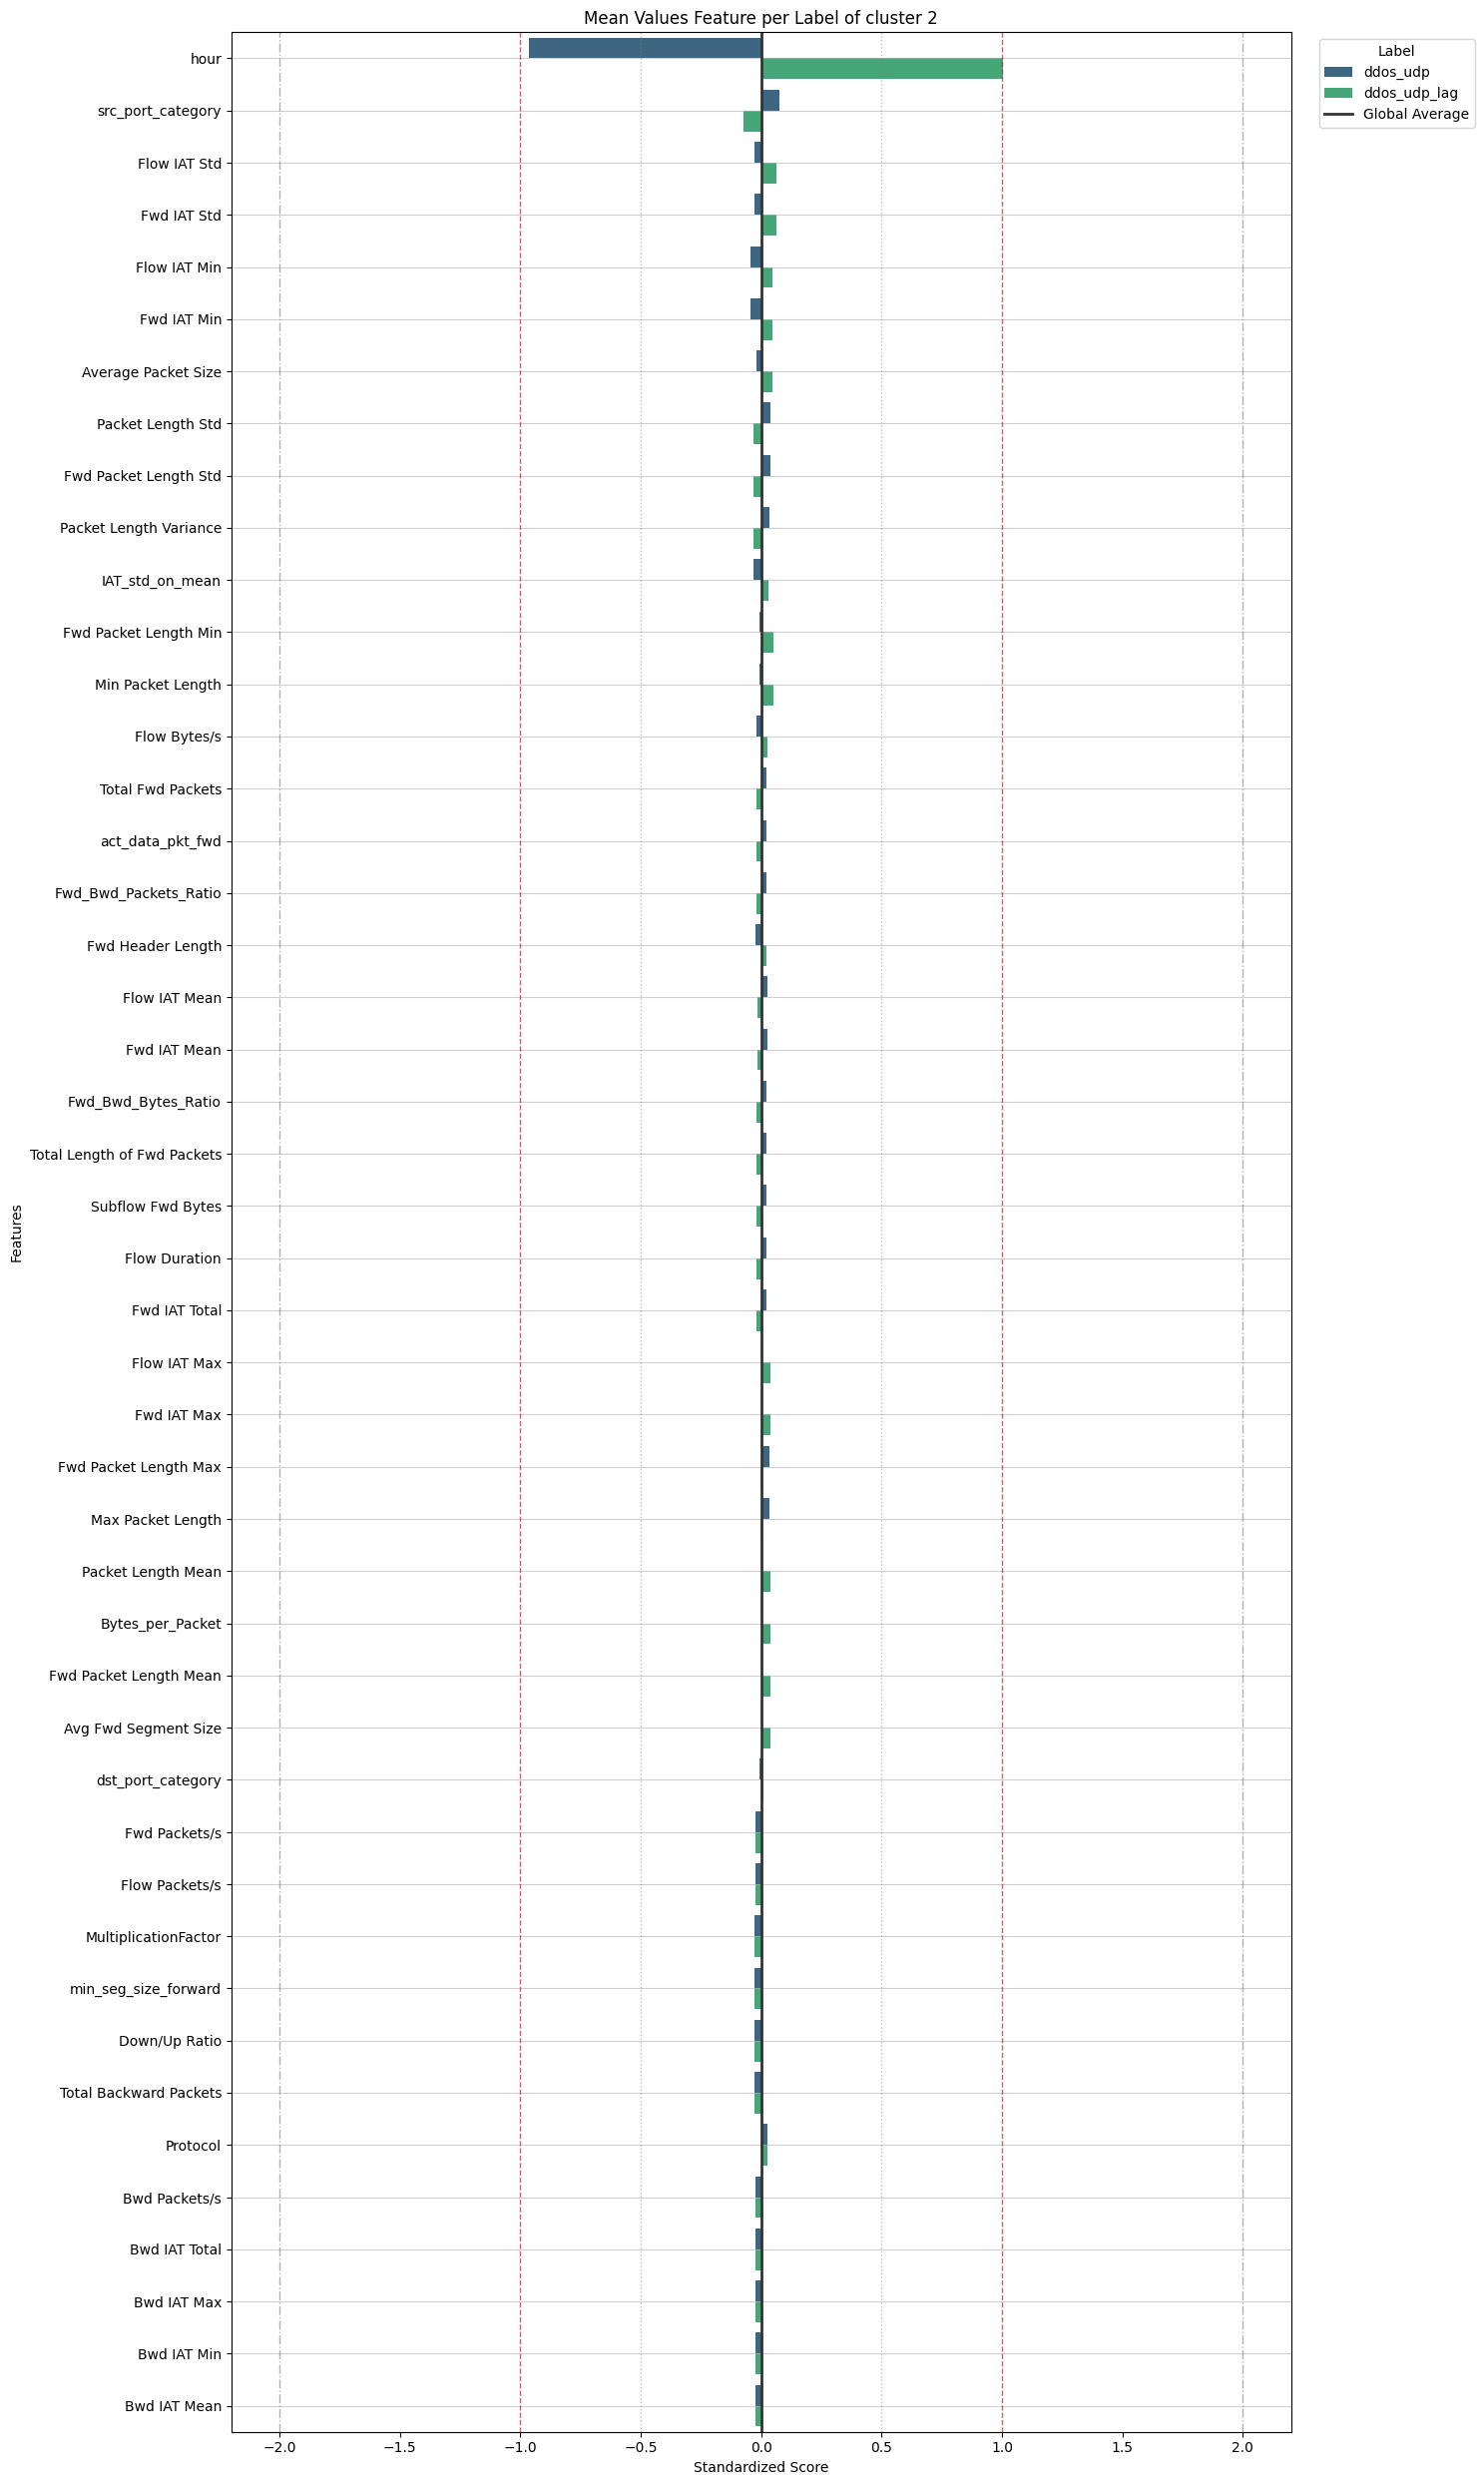

In [106]:
plotMeanFeaturesPerLabel(df_cluster_2_scaled, "Mean", 2)

### Attack Pattern Investigation – cluster 7

In [111]:
df_cluster_7 , df_cluster_7_scaled = getClusterDf(7)

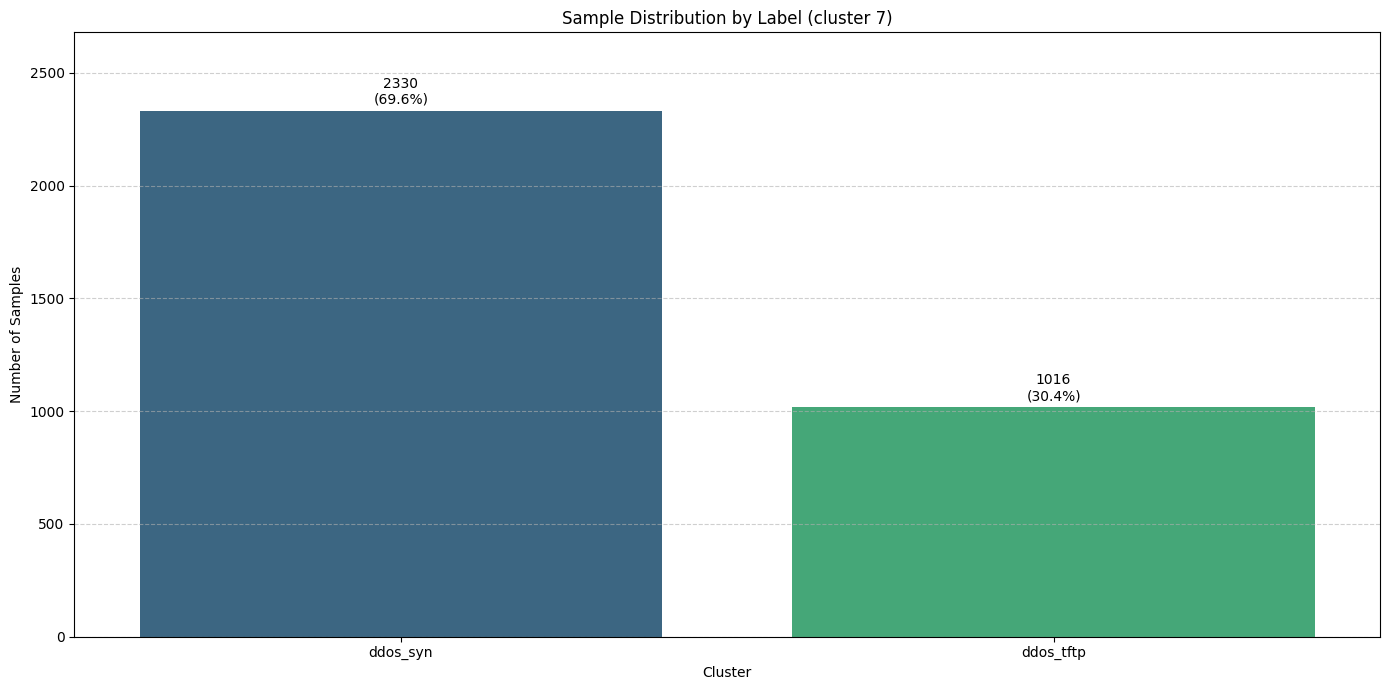

In [112]:
plotLabelSummary(df_cluster_7,7)

In [113]:
df_cluster_7.groupby("label").agg(["mean", "std", "median"])

Flow Duration                            Total Fwd Packets  \
                   mean           std       median              mean   
label                                                                  
ddos_syn   1.089501e+08  1.204771e+07  111278370.0         14.691416   
ddos_tftp  1.173903e+07  3.132387e+06   12407175.5          4.019685   

                           Total Backward Packets                          \
                std median                   mean       std        median   
label                                                                       
ddos_syn   2.715280   14.0               1.577682  1.758307  2.000000e+00   
ddos_tftp  0.197537    4.0               0.421260  0.820729  1.000000e-12   

          Flow Packets/s  ... IAT_std_on_mean Fwd_Bwd_Packets_Ratio  \
                    mean  ...          median                  mean   
label                     ...                                         
ddos_syn        0.241822  ...        1.333668          6.181116e+12   
ddos_tftp       0.594431  ...        1.732050          3.175197e+12   

                                      src_port_category                   \
                    std        median              mean       std median   
label                                                                      
ddos_syn   7.102258e+12  9.000000e+00          1.303004  0.484220    1.0   
ddos_tftp  1.644461e+12  4.000000e+12          1.277559  0.488012    1.0   

          dst_port_category                   
                       mean       std median  
label                                         
ddos_syn           1.232618  0.449188    1.0  
ddos_tftp          1.237205  0.467499    1.0  

[2 rows x 105 columns]

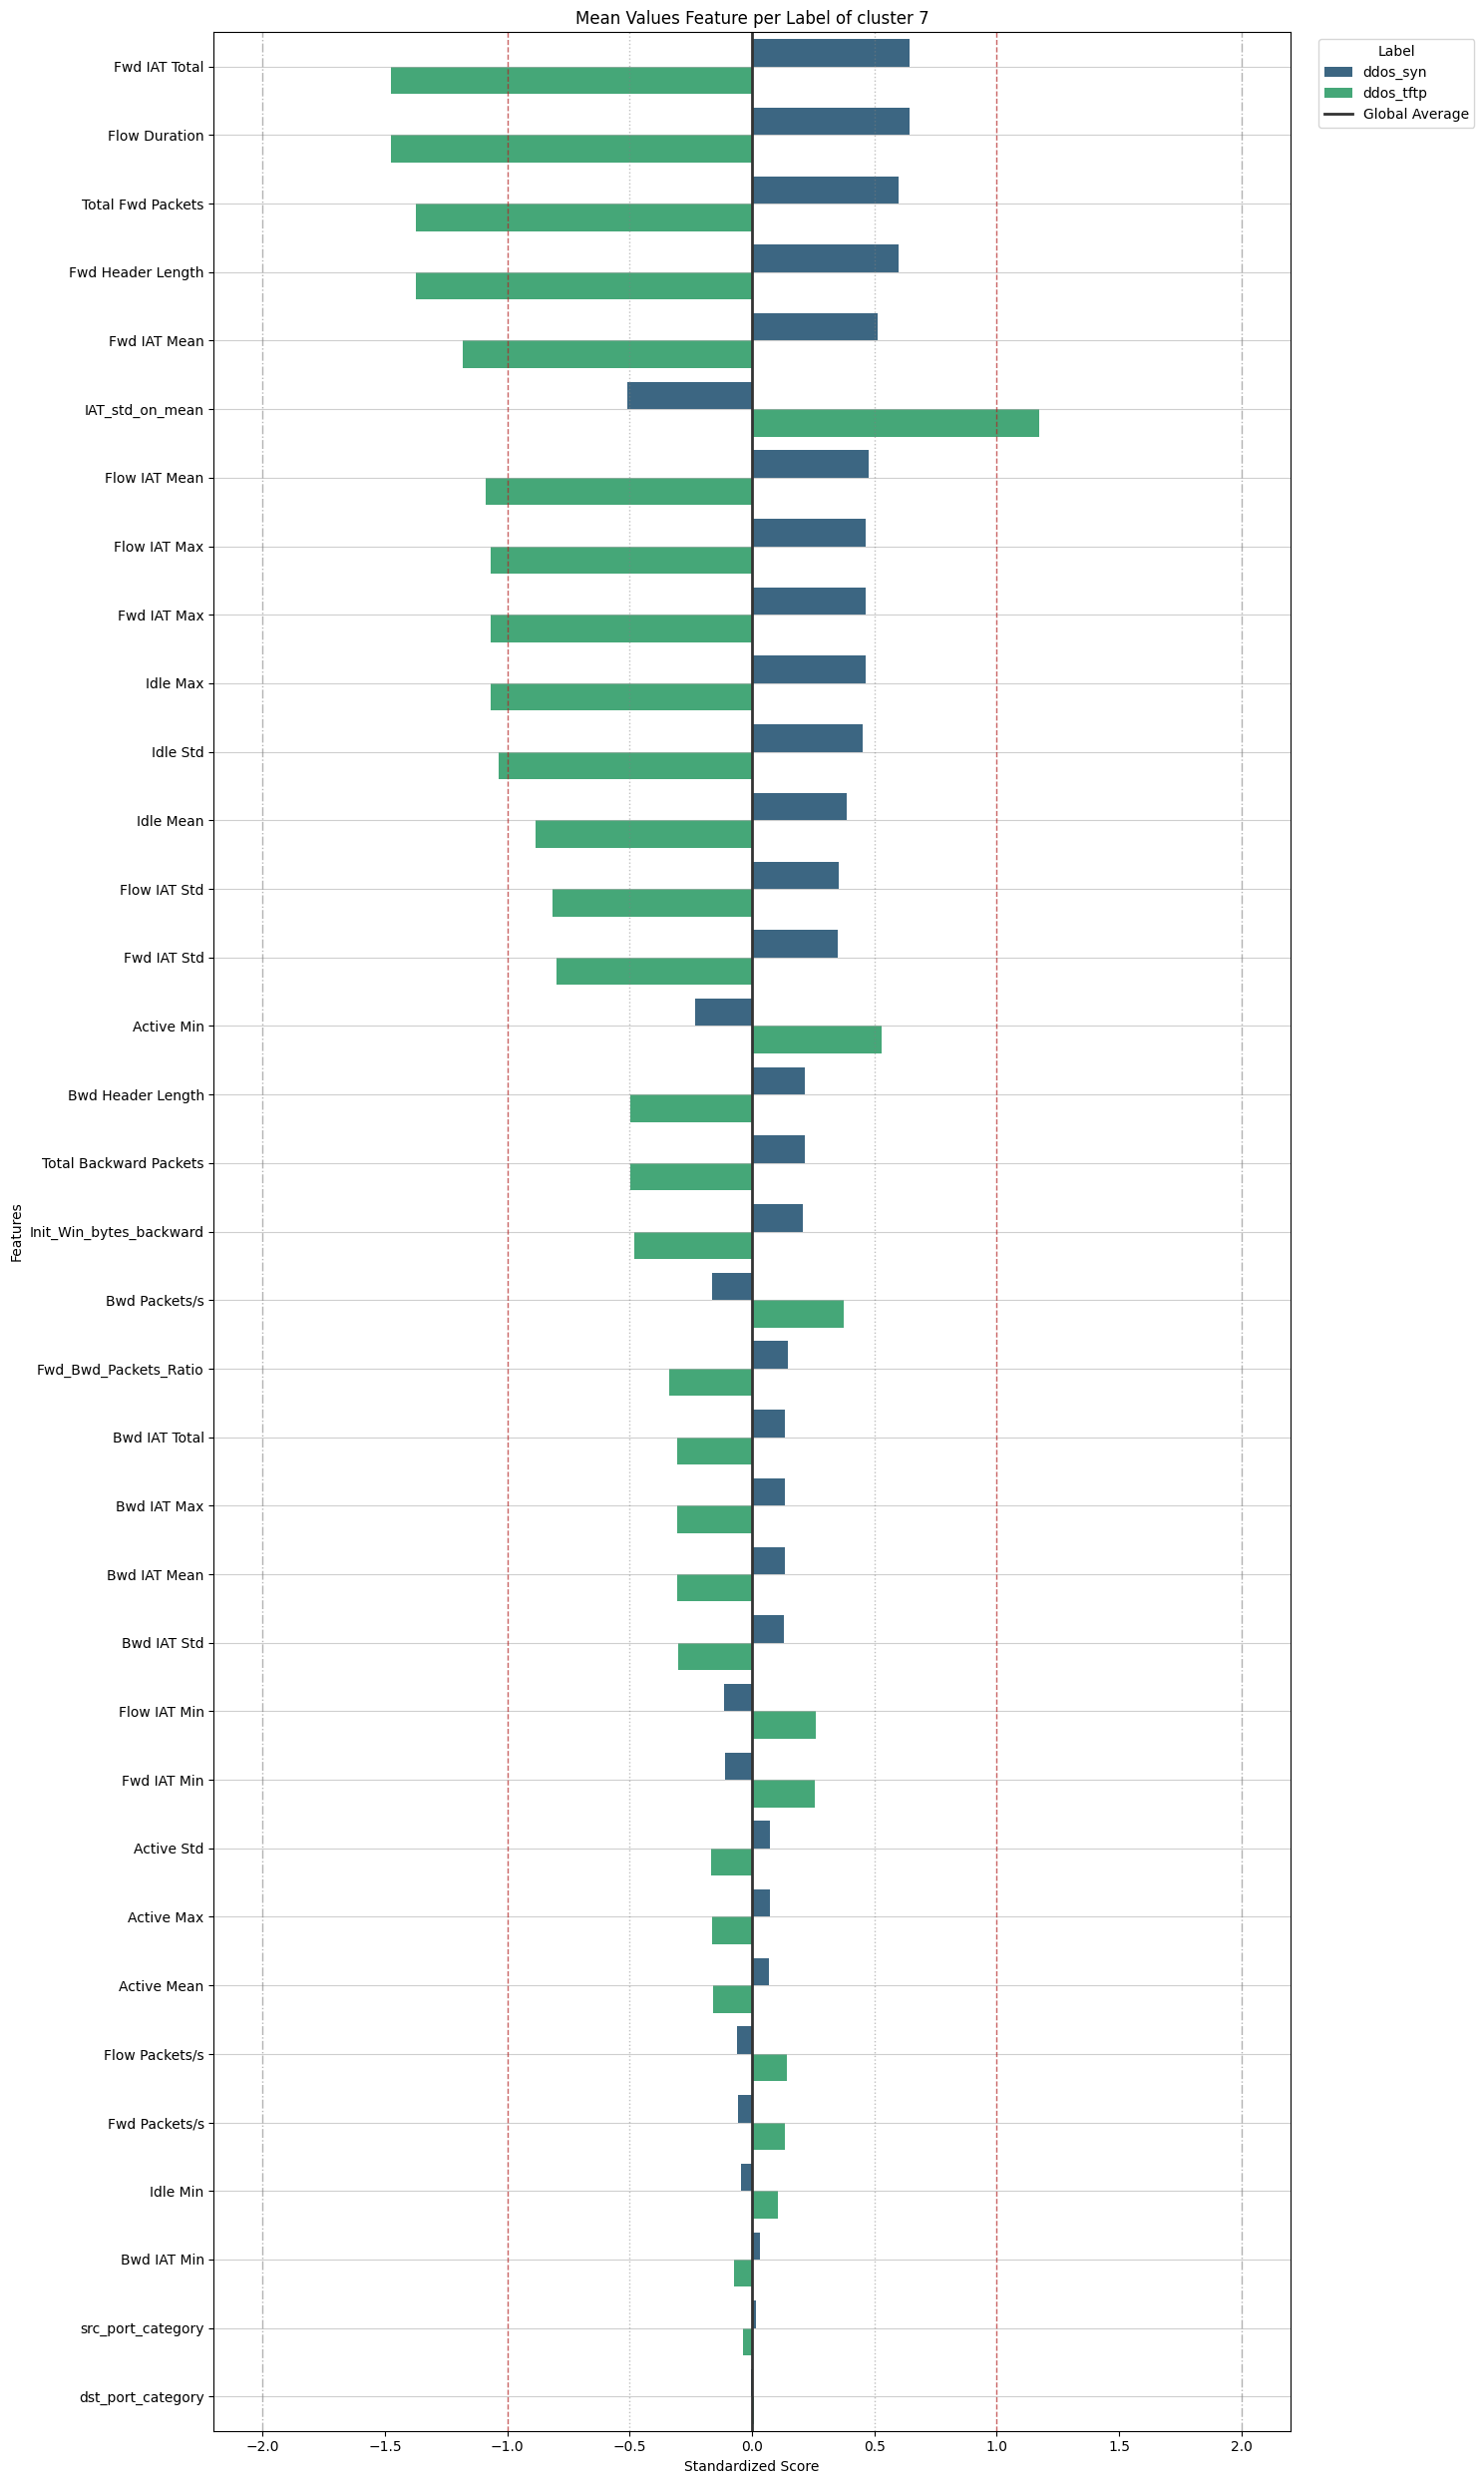

In [116]:
plotMeanFeaturesPerLabel(df_cluster_7_scaled, "Mean", 7)

### Attack Pattern Investigation – cluster 9

In [121]:
df_cluster_9 , df_cluster_9_scaled = getClusterDf(9)

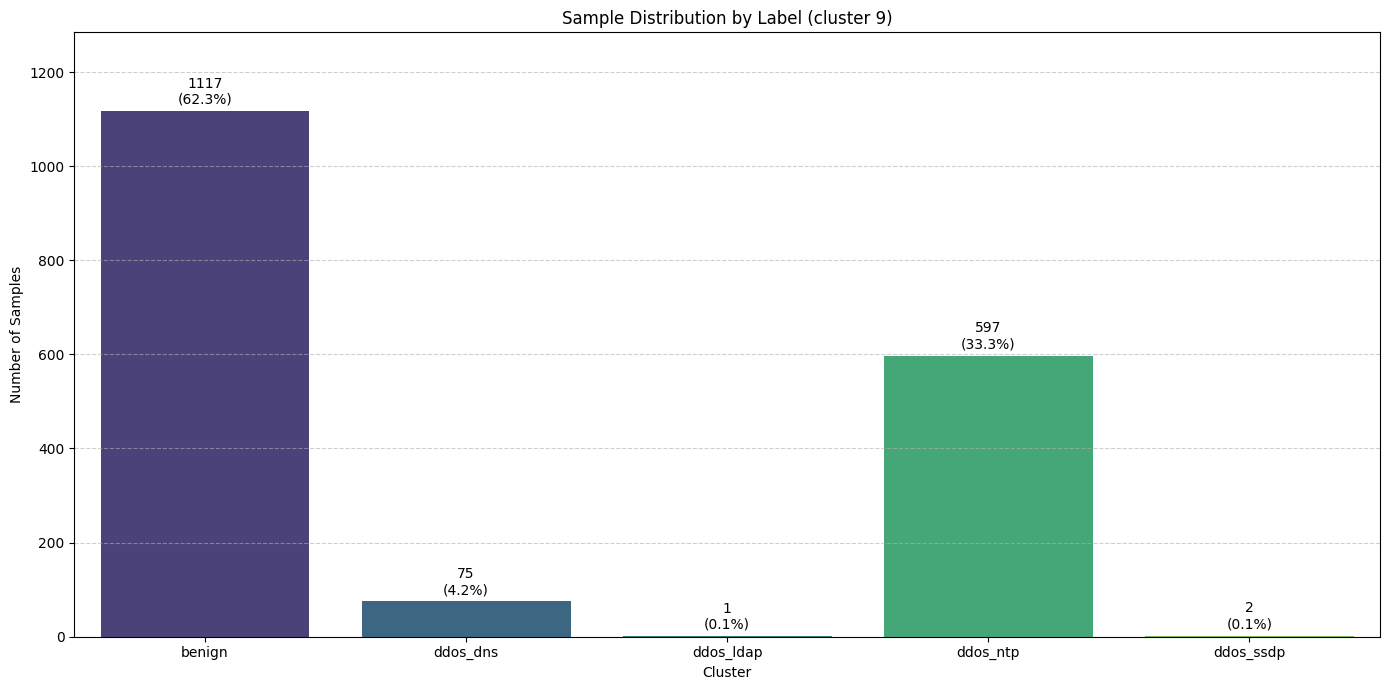

In [122]:
plotLabelSummary(df_cluster_9, 9)

In [123]:
toDrop = ["ddos_dns","ddos_ldap","ddos_ssdp"]
df_cluster_9 = drop_Labels(df_cluster_9, toDrop)
df_cluster_9_scaled = drop_Labels(df_cluster_9_scaled, toDrop)

In [124]:
df_cluster_9.groupby("label").agg(["mean", "std", "median"])

Flow Duration                        Total Fwd Packets            \
                  mean           std   median              mean       std   
label                                                                       
benign    44810.937332  75024.041768  26313.0          1.788720  1.160173   
ddos_ntp  27748.996650  95521.254974    151.0          1.090452  0.554293   

                Total Backward Packets                   \
         median                   mean       std median   
label                                                     
benign      1.0               1.097583  1.200494    1.0   
ddos_ntp    1.0               1.670017  0.704722    2.0   

         Total Length of Fwd Packets  ... src_port_category dst_port_category  \
                                mean  ...            median              mean   
label                                 ...                                       
benign                     26.376902  ...               2.0          0.000000   
ddos_ntp                    0.871022  ...               1.0          0.720268   

                          private_dst_ip                 hour                   
               std median           mean  std median     mean       std median  
label                                                                           
benign    0.000000    0.0            0.0  0.0    0.0  9.12444  0.378289    9.0  
ddos_ntp  0.807146    0.0            1.0  0.0    1.0  9.00000  0.000000    9.0  

[2 rows x 183 columns]

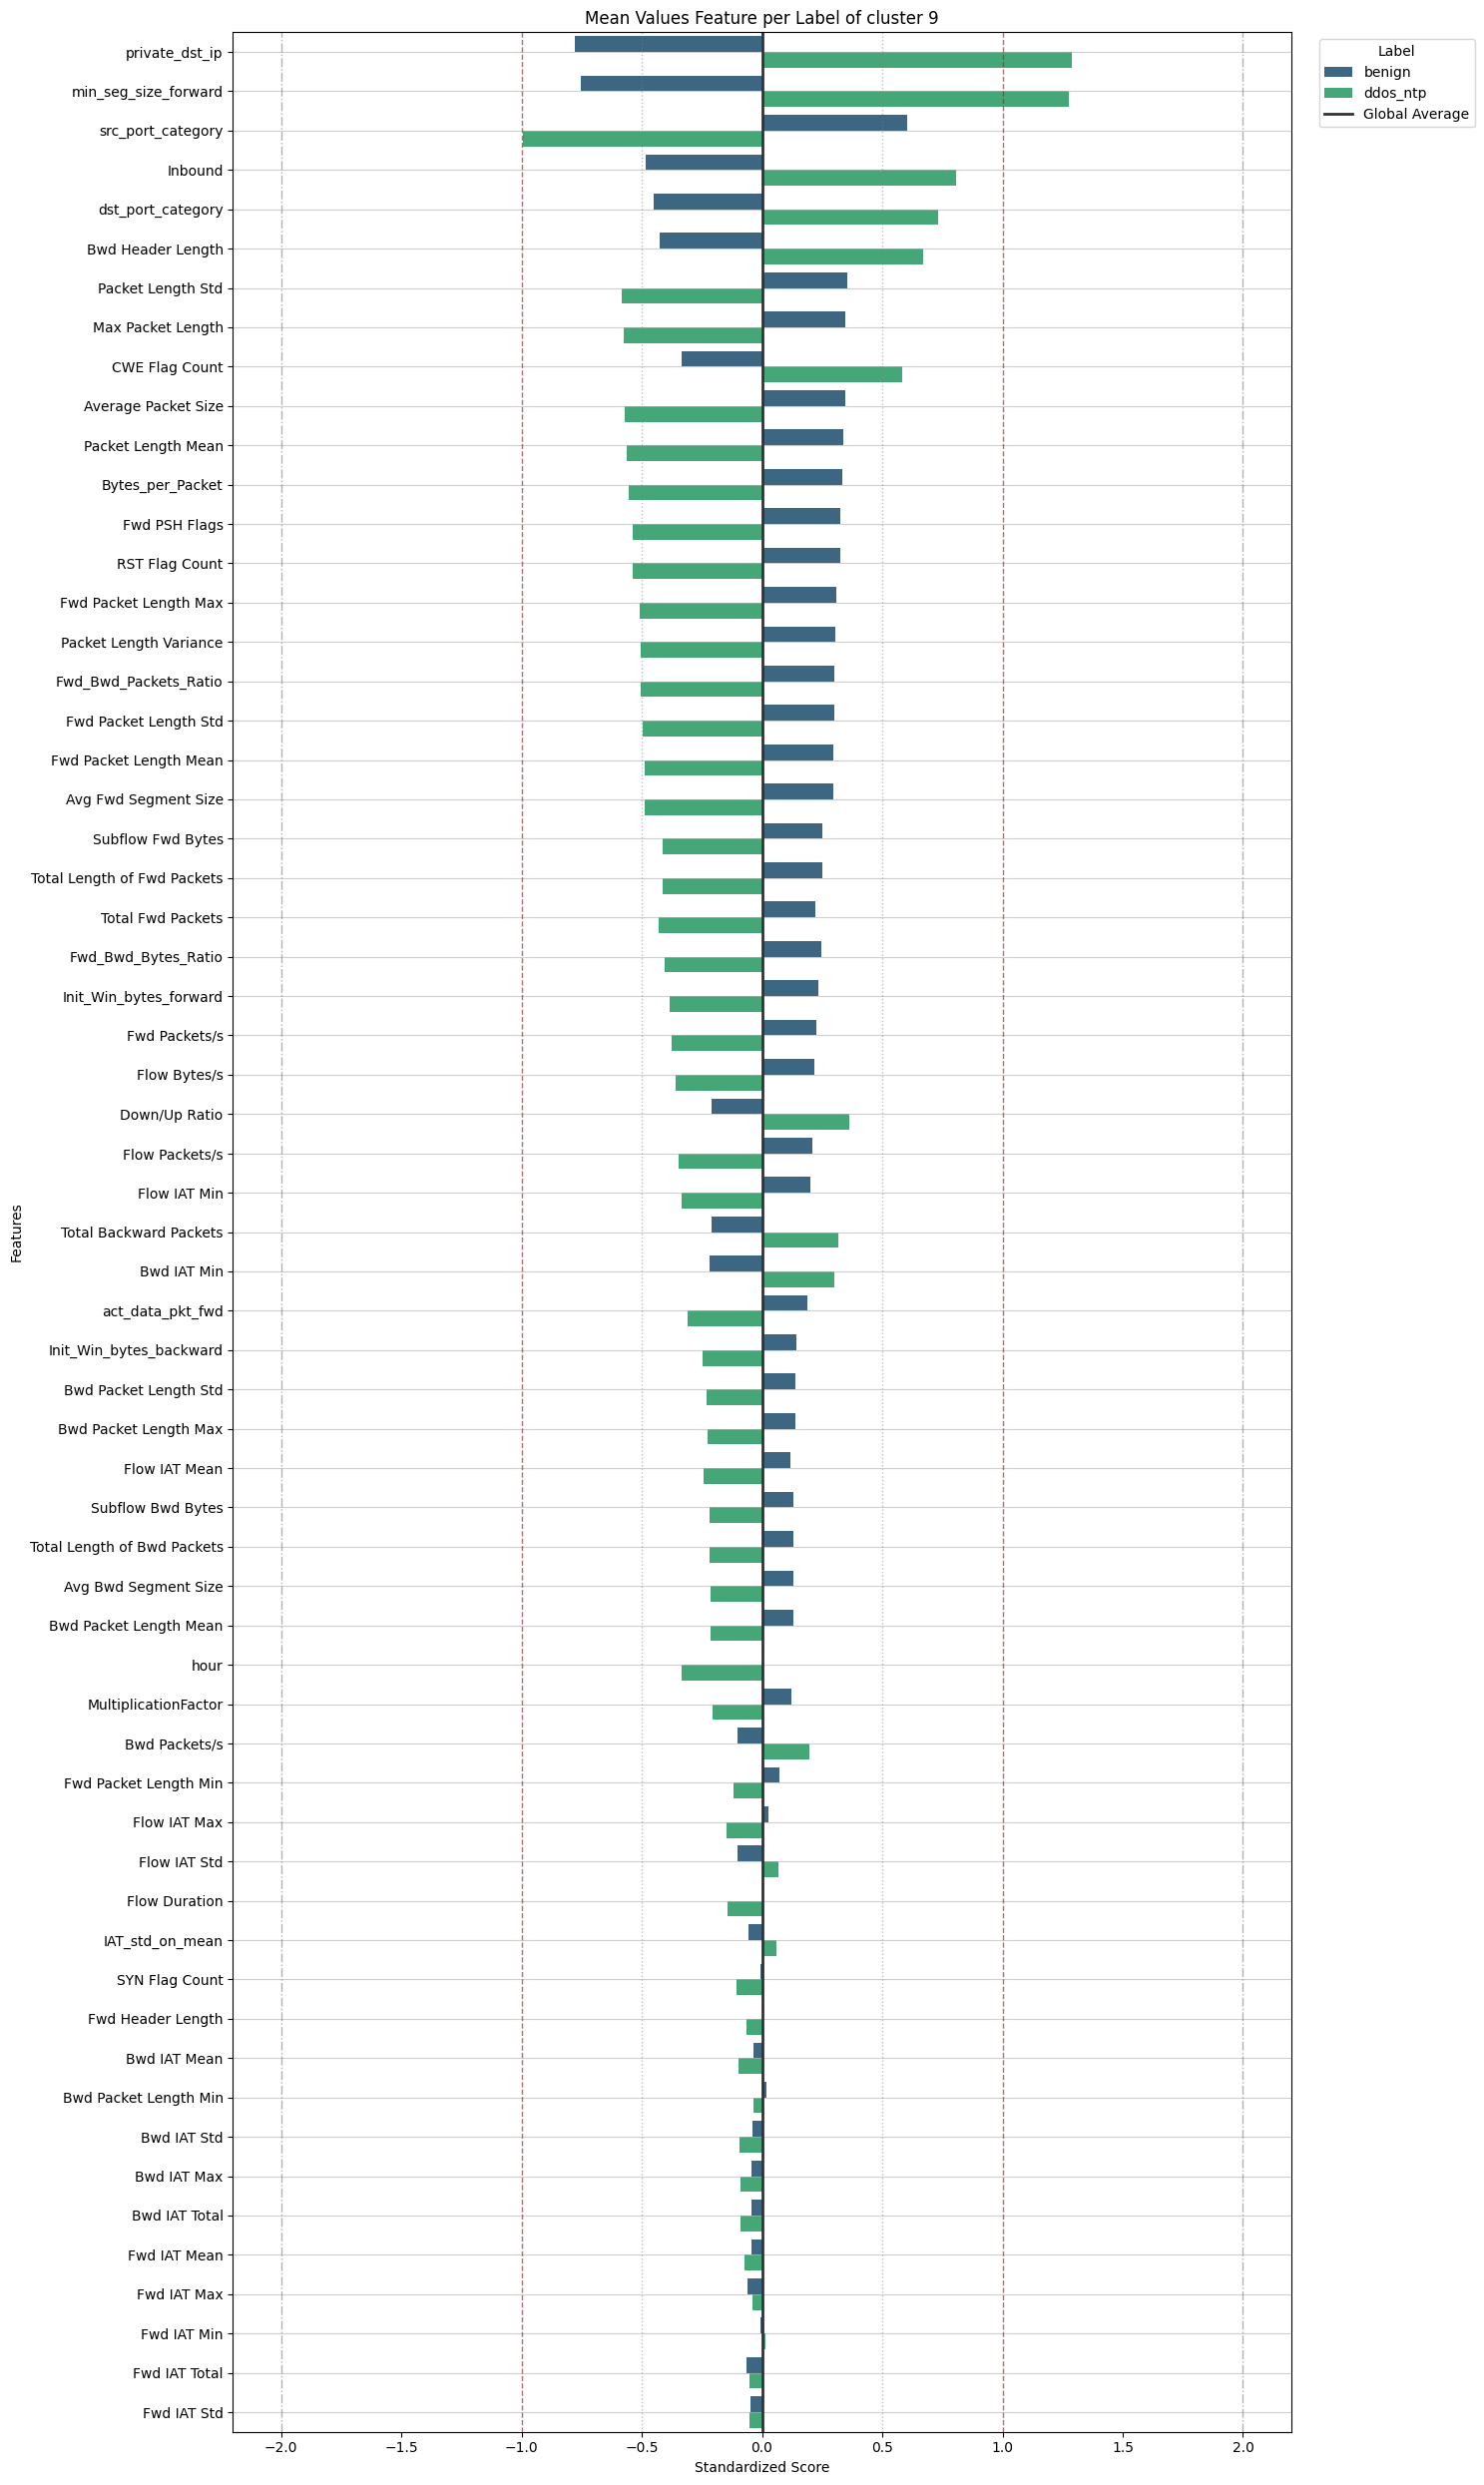

In [125]:
plotMeanFeaturesPerLabel(df_cluster_9_scaled, "Mean", 9)

### Attack Pattern Investigation – cluster 10

In [134]:
df_cluster_10 , df_cluster_10_scaled = getClusterDf(10)

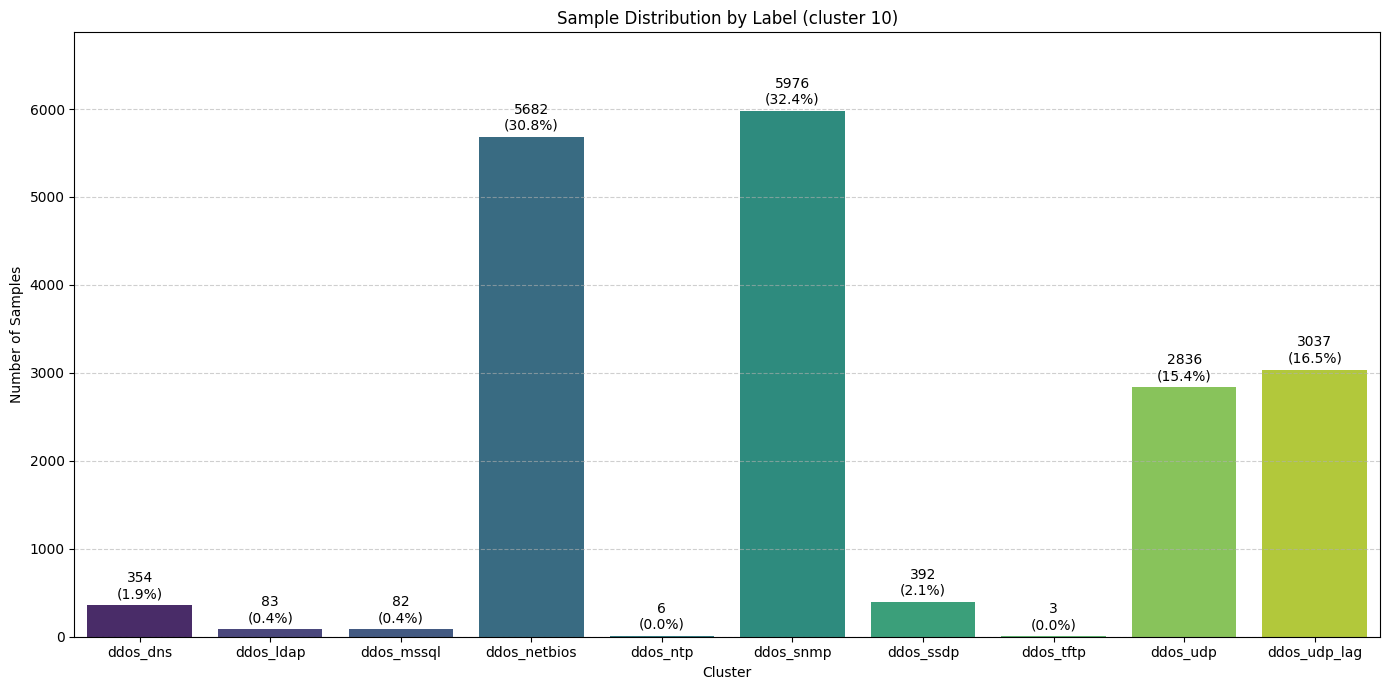

In [135]:
plotLabelSummary(df_cluster_10, 10)

In [138]:
toDrop = ["ddos_dns","ddos_ldap","ddos_mssql","ddos_ntp","ddos_ssdp","ddos_tftp"]
df_cluster_10 = drop_Labels(df_cluster_10, toDrop)
df_cluster_10_scaled = drop_Labels(df_cluster_10_scaled, toDrop)

In [139]:
df_cluster_10.groupby("label").agg(["mean", "std", "median"])

Flow Duration                   Total Fwd Packets              \
                      mean        std median              mean  std median   
label                                                                        
ddos_netbios      4.386836  12.074417    1.0               2.0  0.0    2.0   
ddos_snmp         7.435241  15.923073    1.0               2.0  0.0    2.0   
ddos_udp          6.480959  14.981823    1.0               2.0  0.0    2.0   
ddos_udp_lag      6.710570  15.262056    1.0               2.0  0.0    2.0   

             Total Length of Fwd Packets                     \
                                    mean         std median   
label                                                         
ddos_netbios                 1092.431890  349.096481  958.0   
ddos_snmp                     457.996988   20.948472  458.0   
ddos_udp                      772.654443   39.003031  766.0   
ddos_udp_lag                  773.292065   24.776537  766.0   

             Fwd Packet Length Max  ... Fwd_Bwd_Bytes_Ratio src_port_category  \
                              mean  ...              median              mean   
label                               ...                                         
ddos_netbios            546.215945  ...        9.580000e+14          1.159451   
ddos_snmp               228.998494  ...        4.580000e+14          0.000000   
ddos_udp                386.327221  ...        7.660000e+14          1.459097   
ddos_udp_lag            386.646032  ...        7.660000e+14          1.420810   

                              dst_port_category                   hour       \
                   std median              mean       std median  mean  std   
label                                                                         
ddos_netbios  0.366128    1.0          1.230025  0.456593    1.0  11.0  0.0   
ddos_snmp     0.000000    0.0          1.229250  0.466075    1.0  12.0  0.0   
ddos_udp      0.499119    1.0          1.263047  0.441165    1.0  12.0  0.0   
ddos_udp_lag  0.493770    1.0          1.273625  0.445892    1.0  13.0  0.0   

                     
             median  
label                
ddos_netbios   11.0  
ddos_snmp      12.0  
ddos_udp       12.0  
ddos_udp_lag   13.0  

[4 rows x 99 columns]

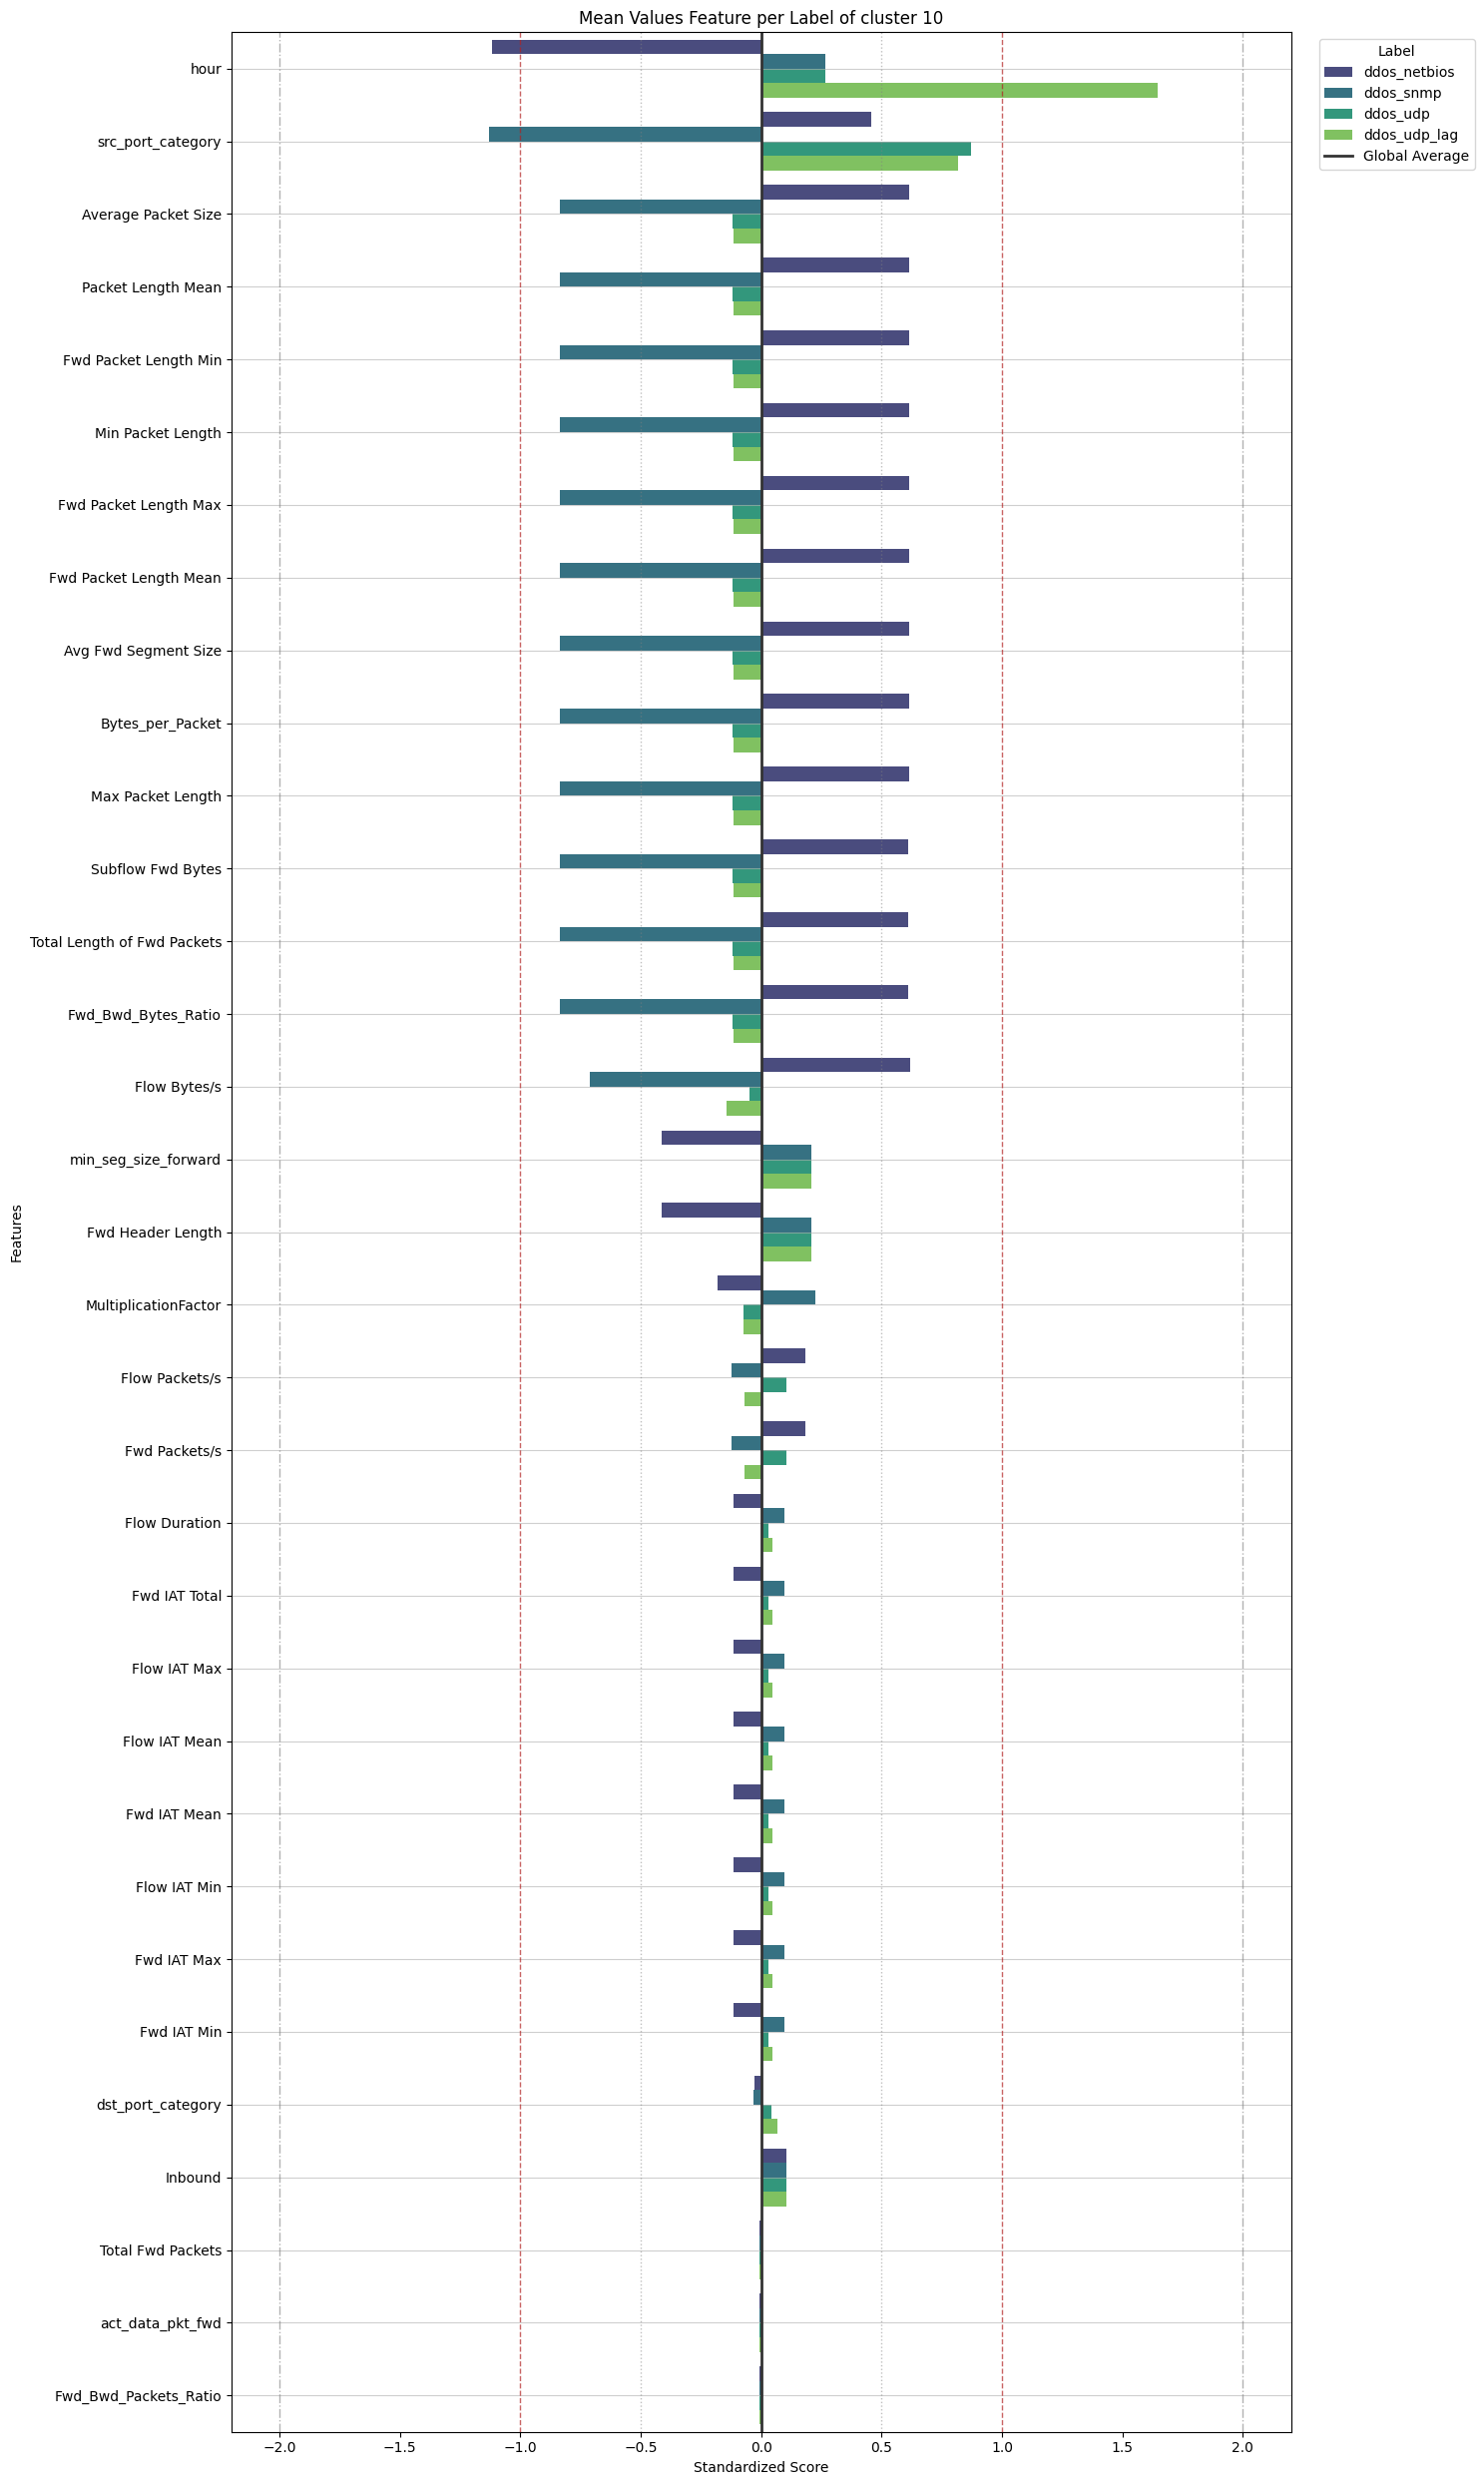

In [140]:
plotMeanFeaturesPerLabel(df_cluster_10_scaled, "Mean", 10)